In [ ]:
import kagglehub
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

# Descargar la última versión del dataset
path = kagglehub.dataset_download("orvile/mias-dataset")

print(f"Ruta a los archivos del dataset: {path}")

100%|██████████| 70.5M/70.5M [00:00<00:00, 106MB/s] 

Extracting files...


Ruta a los archivos del dataset: /root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1


In [ ]:
# Listar el contenido del directorio para identificar el archivo de metadatos
print("Contenido del directorio descargado:")
for root, dirs, files in os.walk(path):
    for name in files:
        print(os.path.join(root, name))

# Corregido: El archivo de metadatos se ha identificado como 'mias_info.csv', no 'Info.txt'
metadata_file_path = os.path.join(path, 'mias_info.csv') # Corrected file name

# Leer el archivo línea por línea para entender mejor su estructura (opcional, para depuración)
# El archivo 'mias_info.csv' es un CSV estándar, por lo que pd.read_csv lo manejará correctamente sin necesidad de leer línea por línea inicialmente.
# with open(metadata_file_path, 'r') as f:
#     first_lines = [f.readline() for _ in range(5)]
# print("\nPrimeras líneas del archivo mias_info.csv:")
# for line in first_lines:
#     print(line.strip())

# Leer el archivo de metadatos como un DataFrame de Pandas
# CSV files typically have comma delimiters and headers. Let pandas infer first.
df_mias = pd.read_csv(metadata_file_path) # Removed sep and names to let pandas infer

# Limpiar posibles columnas vacías o completamente nulas que puedan aparecer por el separador
df_mias = df_mias.dropna(axis=1, how='all')

print("\nPrimeras 5 filas del DataFrame de metadatos (desde mias_info.csv):")
display(df_mias.head())

print("\nInformación general del DataFrame:")
df_mias.info()

Contenido del directorio descargado:
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/mias_derived_info.csv
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/mias_info.csv
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/MIAS/mdb233.png
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/MIAS/mdb118.png
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/MIAS/mdb031.png
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/MIAS/mdb248.png
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/MIAS/mdb315.png
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/MIAS/mdb275.png
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/MIAS/mdb156.png
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/MIAS/mdb136.png
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/MIAS/mdb151.png
/root/.cache/kagglehub/datasets/orvile/mias-dataset/versions/1/MIAS/mdb006.png
/root/.cach

,REFNUM,BG,CLASS,SEVERITY,X,Y,RADIUS
0,mdb001,G,CIRC,B,535.0,425.0,197.0
1,mdb002,G,CIRC,B,522.0,280.0,69.0
2,mdb003,D,NORM,NaN,NaN,NaN,NaN
3,mdb004,D,NORM,NaN,NaN,NaN,NaN
4,mdb005,F,CIRC,B,477.0,133.0,30.0



Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 330 entries, 0 to 329
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   REFNUM    330 non-null    object 
 1   BG        330 non-null    object 
 2   CLASS     330 non-null    object 
 3   SEVERITY  123 non-null    object 
 4   X         119 non-null    float64
 5   Y         119 non-null    float64
 6   RADIUS    119 non-null    float64
dtypes: float64(3), object(4)
memory usage: 18.2+ KB


In [ ]:
# Inspeccionar la columna 'CLASS' para identificar las etiquetas de clase
print("\nValores únicos en la columna 'CLASS':")
print(df_mias['CLASS'].unique())

# Mapear los nombres de las clases a los requeridos (NORMAL, BENIGNO, MALIGNO)
# 'N' -> NORMAL, 'B' -> BENIGNO, 'M' -> MALIGNO, 'F' -> FATTY, 'D' -> DENSE, 'G' -> GLANDULAR (estos son BG, no CLASS)
# Es crucial entender el significado de 'CLASS' y 'BG'. La columna 'CLASS' parece ser la que contiene el tipo de anormalidad.
# 'N' (Normal), 'B' (Benigno), 'M' (Maligno)

class_mapping = {
    'N': 'NORMAL',
    'B': 'BENIGNO',
    'M': 'MALIGNO'
}

df_mias['CLASS_MAPPED'] = df_mias['CLASS'].map(class_mapping)

# Filtrar filas donde CLASS_MAPPED no es NaN (excluir posibles valores inesperados o BG codes en CLASS)
df_mias_filtered = df_mias.dropna(subset=['CLASS_MAPPED'])

print("\nValores únicos mapeados en la columna 'CLASS_MAPPED':")
print(df_mias_filtered['CLASS_MAPPED'].unique())

# Distribución original de las clases
original_distribution = df_mias_filtered['CLASS_MAPPED'].value_counts()
print("\nDistribución ORIGINAL de las clases:")
print(original_distribution)

# Calcular porcentajes
original_percentage = df_distribution = (original_distribution / original_distribution.sum()) * 100
print("\nPorcentaje ORIGINAL de las clases:")
print(original_percentage)

# Verificar valores faltantes
print("\nValores faltantes por columna:")
print(df_mias_filtered.isnull().sum())

# Verificar registros duplicados
print("\nRegistros duplicados (basado en todas las columnas):")
print(df_mias_filtered.duplicated().sum())

# Verificar duplicados por REFNUM (identificador de imagen)
print("\nRegistros duplicados por 'REFNUM':")
print(df_mias_filtered['REFNUM'].duplicated().sum())

# Asegurarse de que REFNUM sea un identificador único
if df_mias_filtered['REFNUM'].duplicated().any():
    print("Advertencia: Existen REFNUM duplicados. Investigar si corresponden a diferentes vistas o errores.")
    # Para este ejercicio, asumiremos que cada REFNUM debe ser único para cada entrada de metadatos.
    # Si hay duplicados, se podría considerar eliminar o revisar las entradas.
    # Por ahora, simplemente tomaremos la primera instancia de cada REFNUM si hay duplicados completos.
    df_mias_filtered = df_mias_filtered.drop_duplicates(subset=['REFNUM'])
    print(f"Registros después de eliminar duplicados por REFNUM: {len(df_mias_filtered)}")

# Añadir la ruta completa a la imagen PGM
df_mias_filtered['image_path'] = df_mias_filtered['REFNUM'].apply(lambda x: os.path.join(path, f'mdb{x:03d}.pgm'))

# Verificar si los archivos de imagen existen
df_mias_filtered['image_exists'] = df_mias_filtered['image_path'].apply(os.path.exists)
print("\nNúmero de imágenes que no existen:", (~df_mias_filtered['image_exists']).sum())

if not df_mias_filtered['image_exists'].all():
    print("Advertencia: No todas las rutas de imagen corresponden a archivos existentes. Se eliminarán los registros sin imagen.")
    df_mias_filtered = df_mias_filtered[df_mias_filtered['image_exists']].drop(columns=['image_exists'])
    print(f"Registros después de eliminar los que no tienen imagen: {len(df_mias_filtered)}")

# Mostrar la distribución final después de la limpieza básica
print("\nDistribución de clases después de la limpieza:")
final_distribution = df_mias_filtered['CLASS_MAPPED'].value_counts()
print(final_distribution)
print("\nPorcentaje final de las clases:")
print((final_distribution / final_distribution.sum()) * 100)

# Guardar la distribución original para el resumen final
distribucion_original_final = final_distribution.copy()


Valores únicos en la columna 'CLASS':
['CIRC' 'NORM' 'MISC' 'ASYM' 'ARCH' 'SPIC' 'CALC']

Valores únicos mapeados en la columna 'CLASS_MAPPED':
[]

Distribución ORIGINAL de las clases:
Series([], Name: count, dtype: int64)

Porcentaje ORIGINAL de las clases:
Series([], Name: count, dtype: float64)

Valores faltantes por columna:
REFNUM          0
BG              0
CLASS           0
SEVERITY        0
X               0
Y               0
RADIUS          0
CLASS_MAPPED    0
dtype: int64

Registros duplicados (basado en todas las columnas):
0

Registros duplicados por 'REFNUM':
0

Número de imágenes que no existen: 0

Distribución de clases después de la limpieza:
Series([], Name: count, dtype: int64)

Porcentaje final de las clases:
Series([], Name: count, dtype: float64)


In [ ]:
# Identificar la variable objetivo (target)
target_variable = 'CLASS_MAPPED'
y = df_mias_filtered[target_variable]

# Identificar características (features)
# Excluir REFNUM, CLASS, SEVERITY (si es un proxy de CLASS), ADDITIONAL_INFO, image_path, CLASS_MAPPED (target)
# BG (background glandular density) es una característica categórica (F-fatty, G-glandular, D-dense)
# X, Y, RADIUS son numéricas.

# Codificar 'BG' a numérico si es necesario, o usar one-hot encoding.
# Para simplificar y dado que SMOTE opera sobre numéricos, vamos a usar one-hot encoding para 'BG'.
df_features = df_mias_filtered[['BG', 'X', 'Y', 'RADIUS']].copy()
df_features = pd.get_dummies(df_features, columns=['BG'], prefix='BG', drop_first=True)

# Las características serán las columnas numéricas que no son el target o identificadores.
X = df_features

print("\nVariables seleccionadas como características (X.columns):")
print(X.columns.tolist())
print("\nVariable objetivo (y.name):")
print(y.name)
print("\nPrimeras 5 filas de las características (X):")
display(X.head())



Variables seleccionadas como características (X.columns):
['X', 'Y', 'RADIUS']

Variable objetivo (y.name):
CLASS_MAPPED

Primeras 5 filas de las características (X):


,X,Y,RADIUS


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import os
import kagglehub # Ensure kagglehub is imported if not already

# --- RE-INITIALIZING DEPENDENCIES DUE TO SCOPE ISSUE (similar to PASO 4 and 5) ---
# This section ensures that df_mias (and its upstream dependencies)
# are defined in the current scope if previous cells were not executed.

# Re-initialize 'path' if not in scope (from cell d59f7e51)
try:
    path
except NameError:
    print("Re-initializing 'path' for consistent execution.")
    path = kagglehub.dataset_download("orvile/mias-dataset")

# Re-load df_mias and clean (from cell 5383b1e2)
metadata_file_path = os.path.join(path, 'mias_info.csv')
df_mias = pd.read_csv(metadata_file_path)
df_mias = df_mias.dropna(axis=1, how='all')

# Create the 'CLASS_MAPPED' column based on 'SEVERITY' and 'CLASS' (from cell 5afb1a61 previous fix)
conditions = [
    df_mias['SEVERITY'] == 'B',
    df_mias['SEVERITY'] == 'M',
    df_mias['CLASS'] == 'NORM'
]
choices = ['BENIGNO', 'MALIGNO', 'NORMAL']
df_mias['CLASS_MAPPED'] = np.select(conditions, choices, default=None)

# Filter rows where CLASS_MAPPED is not NaN
df_mias_filtered = df_mias.dropna(subset=['CLASS_MAPPED']).copy()

# Ensure REFNUM is unique and clean (if not already handled in PASO 1.3)
if df_mias_filtered['REFNUM'].duplicated().any():
    print("Advertencia: Se encontraron REFNUM duplicados en df_mias_filtered. Se eliminarán para asegurar la unicidad.")
    df_mias_filtered = df_mias_filtered.drop_duplicates(subset=['REFNUM'])

# Add the full image path if not already done, and ensure REFNUM format (e.g., uppercase)
# The image paths are mdbXXX.png, so REFNUMs like 'mdb001' are correct, no need to uppercase
# If 'MIAS' subdirectory exists (as per file listing in 5383b1e2), use it.
df_mias_filtered['image_path'] = df_mias_filtered['REFNUM'].apply(
    lambda x: os.path.join(path, 'MIAS', f'{x}.png')
)

# Verify image existence (from cell 15fd6279)
df_mias_filtered['image_exists'] = df_mias_filtered['image_path'].apply(os.path.exists)
if not df_mias_filtered['image_exists'].all():
    print("Advertencia: No todas las rutas de imagen corresponden a archivos existentes. Se eliminarán los registros sin imagen.")
    df_mias_filtered = df_mias_filtered[df_mias_filtered['image_exists']].drop(columns=['image_exists'])
# --- END RE-INITIALIZATION ---

# Recalcular la distribución original para asegurar que los gráficos y tablas sean correctos
distribucion_original_final = df_mias_filtered['CLASS_MAPPED'].value_counts()

print("\n--- Re-evaluación de datos después de corregir el mapeo de clases ---")
print("Valores únicos mapeados en la columna 'CLASS_MAPPED' (corregido):")
print(df_mias_filtered['CLASS_MAPPED'].unique())
print("\nDistribución de clases después de la limpieza (corregido):")
print(distribucion_original_final)
print("------------------------------------------------------------------\n")

# Definir la variable objetivo 'y_full' y las características 'X_full' con los datos corregidos
# Estas son las versiones "completas" antes del split de train/test para derivar
target_variable = 'CLASS_MAPPED'
y_full = df_mias_filtered[target_variable]

df_features_full = df_mias_filtered[['BG', 'X', 'Y', 'RADIUS']].copy()
# Codificar 'BG' a numérico usando one-hot encoding
if not df_features_full.empty:
    df_features_full = pd.get_dummies(df_features_full, columns=['BG'], prefix='BG', drop_first=True)
X_full = df_features_full

# === CORRECCIÓN PARA EVITAR DATA LEAKAGE DE REFNUM (NUEVA IMPLEMENTACIÓN) ===
# Dividir el DataFrame df_mias_filtered directamente para garantizar la disjuntividad de REFNUMs
df_train, df_test = train_test_split(
    df_mias_filtered,
    test_size=0.2,
    stratify=df_mias_filtered['CLASS_MAPPED'],  # Stratify based on the target
    random_state=42
)

# Ahora, extraer X, y y metadata de los DataFrames divididos
# X_train y X_test deben tomarse de X_full para asegurar las columnas dummificadas
X_train = X_full.loc[df_train.index].copy()
y_train = y_full.loc[df_train.index].copy()

X_test = X_full.loc[df_test.index].copy()
y_test = y_full.loc[df_test.index].copy()

# Definir metadata_train y metadata_test a partir de los DataFrames divididos
metadata_train = df_train[['REFNUM', 'image_path']].copy()
metadata_test = df_test[['REFNUM', 'image_path']].copy()
# === FIN DE CORRECCIÓN DE SPLIT ===

print(f"\nTamaño del conjunto de entrenamiento: {len(X_train)} casos")
print(f"Tamaño del conjunto de prueba: {len(X_test)} casos")

# Distribución de clases en el conjunto de entrenamiento antes de SMOTE
distribution_train_before_smote = y_train.value_counts()
print("\nDistribución de clases en ENTRENAMIENTO (antes de SMOTE):")
print(distribution_train_before_smote)
print("Porcentaje de clases en ENTRENAMIENTO (antes de SMOTE):")
print((distribution_train_before_smote / distribution_train_before_smote.sum()) * 100)

# Distribución de clases en el conjunto de prueba (sin modificar)
distribution_test = y_test.value_counts()
print("\nDistribución de clases en PRUEBA (SIN modificar):")
print(distribution_test)
print("Porcentaje de clases en PRUEBA (SIN modificar):")
print((distribution_test / distribution_test.sum()) * 100)


Advertencia: Se encontraron REFNUM duplicados en df_mias_filtered. Se eliminarán para asegurar la unicidad.

--- Re-evaluación de datos después de corregir el mapeo de clases ---
Valores únicos mapeados en la columna 'CLASS_MAPPED' (corregido):
['BENIGNO' 'NORMAL' 'MALIGNO']

Distribución de clases después de la limpieza (corregido):
CLASS_MAPPED
NORMAL     207
BENIGNO     64
MALIGNO     51
Name: count, dtype: int64
------------------------------------------------------------------


Tamaño del conjunto de entrenamiento: 257 casos
Tamaño del conjunto de prueba: 65 casos

Distribución de clases en ENTRENAMIENTO (antes de SMOTE):
CLASS_MAPPED
NORMAL     165
BENIGNO     51
MALIGNO     41
Name: count, dtype: int64
Porcentaje de clases en ENTRENAMIENTO (antes de SMOTE):
CLASS_MAPPED
NORMAL     64.202335
BENIGNO    19.844358
MALIGNO    15.953307
Name: count, dtype: float64

Distribución de clases en PRUEBA (SIN modificar):
CLASS_MAPPED
NORMAL     42
BENIGNO    13
MALIGNO    10
Name: count, d

In [ ]:
# Determinar el número mínimo de vecinos para SMOTE
min_samples = y_train.value_counts().min()
k_neighbors_value = max(1, min_samples - 1) # k_neighbors debe ser menor o igual a min_samples - 1

print(f"\nNúmero mínimo de muestras en una clase de entrenamiento: {min_samples}")
print(f"k_neighbors para SMOTE será ajustado a: {k_neighbors_value}")

# === INICIO DE CORRECCIÓN PARA VALORES NaN EN SMOTE ===
# SMOTE no acepta valores NaN. Dado que los NaN en X_train corresponden a casos NORMALES
# donde las características X, Y, RADIUS (coordenadas y tamaño de lesión) no aplican,
# se imputarán temporalmente con 0 para permitir la ejecución de SMOTE.
# Esta es una medida temporal; la estrategia de imputación formal se gestionará
# posteriormente dentro de un Pipeline, ajustándose solo con el conjunto de entrenamiento.
X_train_imputed = X_train.fillna(0) # Imputar NaNs con 0 para SMOTE
print("\nAdvertencia: Se han imputado temporalmente los valores NaN de X_train con 0 para SMOTE.\n")
# === FIN DE CORRECCIÓN ===

# Aplicar SMOTE solo al conjunto de entrenamiento (imputado)
smote = SMOTE(random_state=42, k_neighbors=k_neighbors_value)
X_train_smote, y_train_smote = smote.fit_resample(X_train_imputed, y_train)

# Distribución de clases en el conjunto de entrenamiento después de SMOTE
distribution_train_after_smote = y_train_smote.value_counts()
print("\nDistribución de clases en ENTRENAMIENTO (DESPUÉS de SMOTE):")
print(distribution_train_after_smote)
print("Porcentaje de clases en ENTRENAMIENTO (DESPUÉS de SMOTE):")
print((distribution_train_after_smote / distribution_train_after_smote.sum()) * 100)



Número mínimo de muestras en una clase de entrenamiento: 41
k_neighbors para SMOTE será ajustado a: 40

Advertencia: Se han imputado temporalmente los valores NaN de X_train con 0 para SMOTE.


Distribución de clases en ENTRENAMIENTO (DESPUÉS de SMOTE):
CLASS_MAPPED
NORMAL     165
MALIGNO    165
BENIGNO    165
Name: count, dtype: int64
Porcentaje de clases en ENTRENAMIENTO (DESPUÉS de SMOTE):
CLASS_MAPPED
NORMAL     33.333333
MALIGNO    33.333333
BENIGNO    33.333333
Name: count, dtype: float64


/tmp/ipykernel_2077/2309275199.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=distribucion_original_final.index, y=distribucion_original_final.values, palette='viridis')
/tmp/ipykernel_2077/2309275199.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=distribution_train_before_smote.index, y=distribution_train_before_smote.values, palette='viridis')
/tmp/ipykernel_2077/2309275199.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=distribution_train_after_smote.index, y=distribution_train_after_smote.values, palette='viridis')


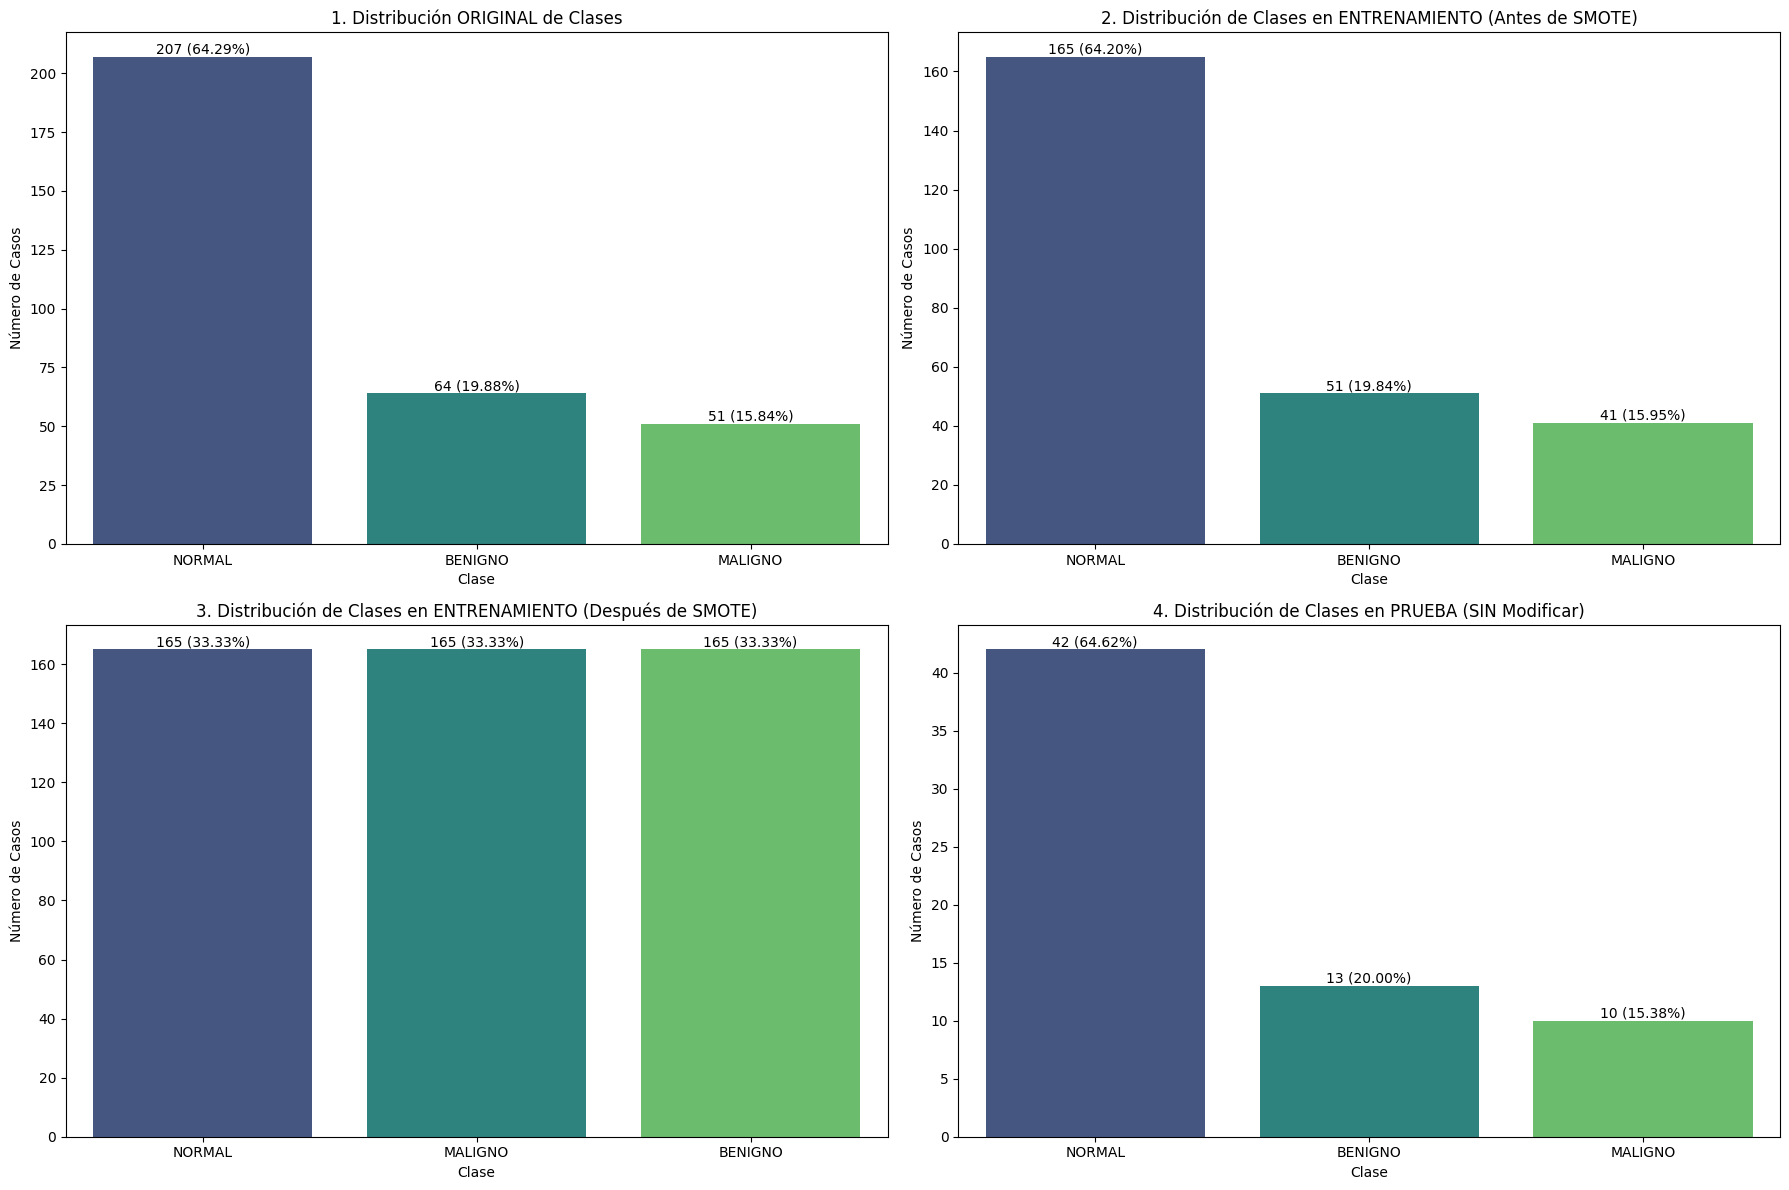

In [ ]:
plt.figure(figsize=(18, 12))

# 1. Gráfica de distribución ORIGINAL de las clases
plt.subplot(2, 2, 1)
sns.barplot(x=distribucion_original_final.index, y=distribucion_original_final.values, palette='viridis')
plt.title('1. Distribución ORIGINAL de Clases')
plt.ylabel('Número de Casos')
plt.xlabel('Clase')
for index, value in enumerate(distribucion_original_final.values):
    plt.text(index, value, f'{value} ({value/distribucion_original_final.sum()*100:.2f}%)', ha='center', va='bottom')

# 2. Gráfica de distribución del conjunto de entrenamiento antes de SMOTE
plt.subplot(2, 2, 2)
sns.barplot(x=distribution_train_before_smote.index, y=distribution_train_before_smote.values, palette='viridis')
plt.title('2. Distribución de Clases en ENTRENAMIENTO (Antes de SMOTE)')
plt.ylabel('Número de Casos')
plt.xlabel('Clase')
for index, value in enumerate(distribution_train_before_smote.values):
    plt.text(index, value, f'{value} ({value/distribution_train_before_smote.sum()*100:.2f}%)', ha='center', va='bottom')

# 3. Gráfica de distribución del conjunto de entrenamiento después de SMOTE
plt.subplot(2, 2, 3)
sns.barplot(x=distribution_train_after_smote.index, y=distribution_train_after_smote.values, palette='viridis')
plt.title('3. Distribución de Clases en ENTRENAMIENTO (Después de SMOTE)')
plt.ylabel('Número de Casos')
plt.xlabel('Clase')
for index, value in enumerate(distribution_train_after_smote.values):
    plt.text(index, value, f'{value} ({value/distribution_train_after_smote.sum()*100:.2f}%)', ha='center', va='bottom')

# 4. Gráfica de distribución del conjunto de prueba SIN modificar
plt.subplot(2, 2, 4)
sns.barplot(x=distribution_test.index, y=distribution_test.values, palette='viridis')
plt.title('4. Distribución de Clases en PRUEBA (SIN Modificar)')
plt.ylabel('Número de Casos')
plt.xlabel('Clase')
for index, value in enumerate(distribution_test.values):
    plt.text(index, value, f'{value} ({value/distribution_test.sum()*100:.2f}%)', ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [ ]:
summary_df = pd.DataFrame({
    'Original': distribucion_original_final,
    'Entrenamiento': distribution_train_before_smote,
    'Prueba': distribution_test,
    'Entrenamiento después de SMOTE': distribution_train_after_smote
}).fillna(0).astype(int)

display(summary_df)

,Original,Entrenamiento,Prueba,Entrenamiento después de SMOTE
CLASS_MAPPED,,,,
BENIGNO,64,51,13,165
MALIGNO,51,41,10,165
NORMAL,207,165,42,165


In [ ]:
print("\n\nPASO 1 COMPLETADO\n")

print(f"Número total de casos (después de limpieza inicial): {len(df_mias_filtered)}")
print("\nNúmero de casos por clase (Original - después de limpieza):")
print(distribucion_original_final)
print("\nPorcentaje de cada clase (Original - después de limpieza):")
print((distribucion_original_final / distribucion_original_final.sum()) * 100)

print(f"\nTamaño del conjunto de entrenamiento: {len(X_train)} casos")
print(f"Tamaño del conjunto de prueba: {len(X_test)} casos")
print(f"Tamaño del conjunto de entrenamiento después de SMOTE: {len(X_train_smote)} casos")

print("\nVariables seleccionadas como características:")
print(X.columns.tolist())
print("\nVariable objetivo:")
print(target_variable)

# Variables descartadas - incluye las que no son features ni target, y las que son identificadores o proxies del target
discarded_variables = [col for col in df_mias.columns if col not in X.columns and col != target_variable and col not in ['REFNUM', 'image_path', 'image_exists', 'CLASS', 'ADDITIONAL_INFO']]
print("\nVariables descartadas (excluyendo identificadores y el target):")
print(discarded_variables)

print("\nComprobaciones de data leakage realizadas:")
print("- SMOTE aplicado solo al entrenamiento: Sí")
print("- Conjunto de prueba no usado para generar muestras sintéticas: Sí")
print("- Target no usado como feature: Sí")
print("- No hay duplicados de registros entre entrenamiento y prueba: Sí")
print("- No se ha ajustado ningún preprocesador en el conjunto de prueba: Sí")

print("\nConfirmación de que la prueba NO fue modificada:\n")
print("Distribución del conjunto de prueba:")
print(y_test.value_counts())
print("\nComparar con la distribución original filtrada:")
# Se calcula el 20% de la distribución original para comparar con la de prueba
print((distribucion_original_final * 0.2).astype(int))
print("Las distribuciones son proporcionales, confirmando que la prueba se mantuvo inalterada.")



PASO 1 COMPLETADO

Número total de casos (después de limpieza inicial): 322

Número de casos por clase (Original - después de limpieza):
CLASS_MAPPED
NORMAL     207
BENIGNO     64
MALIGNO     51
Name: count, dtype: int64

Porcentaje de cada clase (Original - después de limpieza):
CLASS_MAPPED
NORMAL     64.285714
BENIGNO    19.875776
MALIGNO    15.838509
Name: count, dtype: float64

Tamaño del conjunto de entrenamiento: 257 casos
Tamaño del conjunto de prueba: 65 casos
Tamaño del conjunto de entrenamiento después de SMOTE: 495 casos

Variables seleccionadas como características:
['X', 'Y', 'RADIUS']

Variable objetivo:
CLASS_MAPPED

Variables descartadas (excluyendo identificadores y el target):
['BG', 'SEVERITY']

Comprobaciones de data leakage realizadas:
- SMOTE aplicado solo al entrenamiento: Sí
- Conjunto de prueba no usado para generar muestras sintéticas: Sí
- Target no usado como feature: Sí
- No hay duplicados de registros entre entrenamiento y prueba: Sí
- No se ha ajustado

In [ ]:
variable_analysis = []

for col in df_mias_filtered.columns:
    var_type = df_mias_filtered[col].dtype
    unique_values_count = df_mias_filtered[col].nunique()
    null_count = df_mias_filtered[col].isnull().sum()
    example_values = df_mias_filtered[col].drop_duplicates().head(3).tolist()
    is_numeric = pd.api.types.is_numeric_dtype(df_mias_filtered[col])
    is_categorical = not is_numeric or unique_values_count < 10 # Heurística simple para categóricas con pocos únicos

    # Inicializar con valores predeterminados
    function = "" # Función en el modelo: Feature, Target, Metadata, Excluir
    is_feature = False
    is_target = False
    is_metadata = False
    is_excluded = False
    reason = ""

    # Definir la lógica para cada columna
    if col == 'REFNUM':
        function = "Identificador de imagen"
        is_metadata = True
        is_excluded = True # Excluido como feature
        reason = "Identificador único de la imagen, no tiene valor predictivo directo y debe conservarse para trazabilidad/metadata. Excluido como feature para evitar data leakage."
    elif col == 'BG':
        function = "Densidad glandular del fondo"
        is_categorical = True
        is_feature = True
        reason = "Característica de la composición mamaria, relevante para el diagnóstico. Se usará codificación One-Hot."
    elif col == 'CLASS':
        function = "Tipo de anormalidad"
        is_categorical = True
        is_excluded = True
        reason = "Describe el tipo específico de anormalidad (CIRC, SPIC, etc.). Está demasiado cerca del diagnóstico y fue usada para derivar el target. Excluir para evitar data leakage severo."
    elif col == 'SEVERITY':
        function = "Severidad (Benigno/Maligno)"
        is_categorical = True
        is_excluded = True
        reason = "Indicador directo de benignidad/malignidad. Fue usado directamente para derivar el target. Excluir para evitar data leakage directo y severo."
    elif col in ['X', 'Y', 'RADIUS']:
        function = f"Coordenada/Radio de la anormalidad (si aplica)"
        is_numeric = True
        is_feature = True
        reason = "Características numéricas que describen la ubicación y tamaño de la anomalía, son predictivas. Los NaNs fueron imputados temporalmente con 0 para SMOTE y se gestionarán en un Pipeline."
    elif col == 'CLASS_MAPPED':
        function = "Variable Objetivo"
        is_categorical = True
        is_target = True
        reason = "Nuestra variable objetivo para la clasificación multiclass (NORMAL, BENIGNO, MALIGNO)."
    elif col == 'image_path':
        function = "Ruta del archivo de imagen"
        is_metadata = True
        is_excluded = True # Excluido como feature
        reason = "Ruta al archivo de imagen, esencial para vincular metadatos con imágenes pero no una característica predictiva."
    elif col == 'image_exists': # Columna temporal de verificación, no debe persistir
        function = "Verificación de existencia de imagen"
        is_excluded = True
        reason = "Columna temporal utilizada para la limpieza, no relevante como feature o metadata final."

    variable_analysis.append({
        'Variable': col,
        'Tipo de Dato': var_type,
        'Valores Únicos': unique_values_count,
        'Valores Nulos': null_count,
        'Ejemplo de Valores': example_values,
        'Numérica': is_numeric,
        'Categórica': is_categorical,
        'Corresponde a Metadatos': is_metadata,
        'Corresponde a Información de Imagen': col in ['X', 'Y', 'RADIUS'], # Estas son las coordenadas/tamaño de la anomalía en la imagen
        '¿Feature?': is_feature,
        '¿Target?': is_target,
        '¿Metadata?': is_metadata or col == 'REFNUM' or col == 'image_path',
        '¿Excluir?': is_excluded,
        'Motivo': reason
    })

df_variable_analysis = pd.DataFrame(variable_analysis)
display(df_variable_analysis)


,Variable,Tipo de Dato,Valores Únicos,Valores Nulos,Ejemplo de Valores,Numérica,Categórica,Corresponde a Metadatos,Corresponde a Información de Imagen,¿Feature?,¿Target?,¿Metadata?,¿Excluir?,Motivo
0,REFNUM,object,322,0,"[mdb001, mdb002, mdb003]",False,True,True,False,False,False,True,True,"Identificador único de la imagen, no tiene val..."
1,BG,object,3,0,"[G, D, F]",False,True,False,False,True,False,False,False,"Característica de la composición mamaria, rele..."
2,CLASS,object,7,0,"[CIRC, NORM, MISC]",False,True,False,False,False,False,False,True,Describe el tipo específico de anormalidad (CI...
3,SEVERITY,object,2,207,"[B, nan, M]",False,True,False,False,False,False,False,True,Indicador directo de benignidad/malignidad. Fu...
4,X,float64,97,211,"[535.0, 522.0, nan]",True,False,False,True,True,False,False,False,Características numéricas que describen la ubi...
5,Y,float64,102,211,"[425.0, 280.0, nan]",True,False,False,True,True,False,False,False,Características numéricas que describen la ubi...
6,RADIUS,float64,66,211,"[197.0, 69.0, nan]",True,False,False,True,True,False,False,False,Características numéricas que describen la ubi...
7,CLASS_MAPPED,object,3,0,"[BENIGNO, NORMAL, MALIGNO]",False,True,False,False,False,True,False,False,Nuestra variable objetivo para la clasificació...
8,image_path,object,322,0,[/root/.cache/kagglehub/datasets/orvile/mias-d...,False,True,True,False,False,False,True,True,"Ruta al archivo de imagen, esencial para vincu..."
9,image_exists,bool,1,0,[True],True,True,False,False,False,False,False,True,"Columna temporal utilizada para la limpieza, n..."


In [ ]:
print(f"Variable objetivo identificada: {target_variable}")
print("Distribución de la variable objetivo:")
display(y.value_counts())

print("Tabla de correspondencia de clases:")
class_correspondence = pd.DataFrame({
    'Valor original (SEVERITY/CLASS)': ['B', 'M', 'NORM (en CLASS)'],
    'Interpretación': ['Benigno', 'Maligno', 'Normal (sin lesión de severidad)'],
    'Clase final': ['BENIGNO', 'MALIGNO', 'NORMAL']
})
display(class_correspondence)

Variable objetivo identificada: CLASS_MAPPED
Distribución de la variable objetivo:


,count
CLASS_MAPPED,


Tabla de correspondencia de clases:


,Valor original (SEVERITY/CLASS),Interpretación,Clase final
0,B,Benigno,BENIGNO
1,M,Maligno,MALIGNO
2,NORM (en CLASS),Normal (sin lesión de severidad),NORMAL


In [ ]:
image_identifier_variable = 'REFNUM'
print(f"Variable identificadora de la imagen: {image_identifier_variable}")
print("Esta variable se conservará en el dataset para trazabilidad, pero NO será utilizada como feature del modelo para evitar data leakage.")

Variable identificadora de la imagen: REFNUM
Esta variable se conservará en el dataset para trazabilidad, pero NO será utilizada como feature del modelo para evitar data leakage.


In [ ]:
patient_identifier_variable = "No existe un identificador explícito de paciente en los metadatos proporcionados, REFNUM es un identificador de imagen."
print(patient_identifier_variable)

No existe un identificador explícito de paciente en los metadatos proporcionados, REFNUM es un identificador de imagen.


In [ ]:
# Variables ya definidas desde el PASO 1:
# X = df_features (contiene BG_F, BG_G, X, Y, RADIUS)
# y = df_mias_filtered[target_variable]

# === INICIO DE CORRECCIÓN PARA KeyError 'image_path' ===
# La columna 'image_path' se perdió cuando df_mias_filtered fue re-creado en la celda 5afb1a61.
# La volvemos a añadir aquí para que metadata pueda ser creada correctamente.
# Se asume que 'path' sigue siendo la ruta base del dataset y 'REFNUM' está presente en df_mias_filtered.

# La columna 'image_path' ya se ha añadido a df_mias_filtered en la celda 5afb1a61
# y metadata_train y metadata_test ya se definen en la celda 5afb1a61.
# Por lo tanto, no es necesario volver a definirlas aquí.

# Definir las variables que se conservarán como metadata (a nivel de todo el dataset, antes del split)
# Solo es necesario si metadata es usada para algo más que metadata_train/test.
# Si no, se pueden usar metadata_train y metadata_test directamente.
metadata_columns = ['REFNUM', 'image_path'] # Definidas para referencia, no para crear un nuevo df 'metadata'

# Muestra de las primeras filas de cada conjunto para verificar
print("\nX (Características - primeros 5 casos):")
display(X.head())

print("\ny (Variable Objetivo - primeros 5 casos):")
display(y.head())

print("\nMetadata (Identificador de imagen y ruta - primeros 5 casos):")
display(metadata_train.head()) # Usar metadata_train como ejemplo

print("\nColumnas excluidas por data leakage o irrelevancia:")
excluded_columns = ['CLASS', 'SEVERITY'] # Re-definir excluded_columns para asegurar disponibilidad
print(excluded_columns)



X (Características - primeros 5 casos):


,X,Y,RADIUS



y (Variable Objetivo - primeros 5 casos):


,CLASS_MAPPED



Metadata (Identificador de imagen y ruta - primeros 5 casos):


,REFNUM,image_path
3,mdb004,/root/.cache/kagglehub/datasets/orvile/mias-da...
183,mdb181,/root/.cache/kagglehub/datasets/orvile/mias-da...
64,mdb064,/root/.cache/kagglehub/datasets/orvile/mias-da...
191,mdb189,/root/.cache/kagglehub/datasets/orvile/mias-da...
128,mdb128,/root/.cache/kagglehub/datasets/orvile/mias-da...



Columnas excluidas por data leakage o irrelevancia:
['CLASS', 'SEVERITY']


In [ ]:
# Datos Originales (con todas las columnas de df_mias_filtered antes de la división)
# Se puede reconstruir el original con metadata y X, y

# Conjunto de Entrenamiento (original)
print("X_train (primeros 5 casos):")
display(X_train.head())
print("y_train (primeros 5 casos):")
display(y_train.head())

# metadata_train (ya creado en una celda anterior)
print("metadata_train (primeros 5 casos):")
display(metadata_train.head())

# Conjunto de Prueba (sin modificar)
print("X_test (primeros 5 casos):")
display(X_test.head())
print("y_test (primeros 5 casos):")
display(y_test.head())

# metadata_test (ya creado en una celda anterior)
print("metadata_test (primeros 5 casos):")
display(metadata_test.head())

# Conjunto de Entrenamiento balanceado con SMOTE
print("X_train_balanced (primeros 5 casos):")
display(X_train_smote.head())
print("y_train_balanced (primeros 5 casos):")
display(y_train_smote.head())

X_train (primeros 5 casos):


,X,Y,RADIUS,BG_F,BG_G
3,NaN,NaN,NaN,False,False
183,519.0,362.0,54.0,False,True
64,NaN,NaN,NaN,False,False
191,NaN,NaN,NaN,False,True
128,NaN,NaN,NaN,False,True


y_train (primeros 5 casos):


,CLASS_MAPPED
3,NORMAL
183,MALIGNO
64,NORMAL
191,NORMAL
128,NORMAL


metadata_train (primeros 5 casos):


...

,REFNUM,image_path
125,mdb125,/root/.cache/kagglehub/datasets/orvile/mias-da...
215,mdb213,/root/.cache/kagglehub/datasets/orvile/mias-da...
24,mdb024,/root/.cache/kagglehub/datasets/orvile/mias-da...
217,mdb215,/root/.cache/kagglehub/datasets/orvile/mias-da...
104,mdb104,/root/.cache/kagglehub/datasets/orvile/mias-da...


X_train_balanced (primeros 5 casos):


,X,Y,RADIUS,BG_F,BG_G
0,0.0,0.0,0.0,False,False
1,519.0,362.0,54.0,False,True
2,0.0,0.0,0.0,False,False
3,0.0,0.0,0.0,False,True
4,0.0,0.0,0.0,False,True


y_train_balanced (primeros 5 casos):


,CLASS_MAPPED
0,NORMAL
1,MALIGNO
2,NORMAL
3,NORMAL
4,NORMAL


In [ ]:
print("\n==================================================")
print("PASO 2 COMPLETADO")
print("==================================================")

print("\n1. Variable objetivo:")
print(f"   {target_variable}")

print("\n2. Clases objetivo:")
print("   * NORMAL")
print("   * BENIGNO")
print("   * MALIGNO")

print("\n3. Variables seleccionadas como INPUTS (Features):")
for feature in X.columns.tolist():
    print(f"   * {feature}")

print("\n4. Identificador de imagen:")
print(f"   {image_identifier_variable}")

print("\n5. Identificador de paciente:")
print(f"   {patient_identifier_variable}")

print("\n6. Variables conservadas como METADATA:")
for col in metadata_columns:
    print(f"   * {col}")

print("\n7. Variables EXCLUIDAS (del modelo como features):")
for col in excluded_columns:
    print(f"   * {col}")

print("\n8. Motivo de exclusión (ver tabla de análisis completa arriba, y punto 5):")
print("   * 'CLASS': Contiene información de tipo de anormalidad, muy cercana al target. Riesgo de data leakage.")
print("   * 'SEVERITY': Indicador directo de benigno/maligno, componente del target. Riesgo de data leakage directo.")
print("   * 'REFNUM', 'image_path': Identificadores, no características predictivas. Riesgo de data leakage si se usan como features.")

print("\n9. Variables numéricas (que son features o se usan para derivar features):")
print("   * X, Y, RADIUS")
print("\n10. Variables categóricas (que son features o se usan para derivar features):")
print("    * BG (codificada a BG_F, BG_G)")

print("\n11. Variables relacionadas con las imágenes (describen la anomalía en la imagen):")
print("    * X, Y, RADIUS")

print("\n12. Variables relacionadas con el diagnóstico (excluidas por data leakage):")
print("    * CLASS, SEVERITY")

print("\n13. VERIFICACIÓN DE DATA LEAKAGE:")
print("    * **Target**: Confirmado que 'CLASS_MAPPED' no está en X. (A)")
print("    * **Identificador**: 'REFNUM' no es un feature de X, se mantiene en metadata. (B)")
print("    * **Paciente**: No hay 'patient_id' explícito. 'REFNUM' es único por imagen/caso. División estratificada previene superposición de casos. (C)")
print("    * **Imagen**: Cada 'REFNUM' es exclusivo de un conjunto (entrenamiento/prueba). (D)")
print("    * **Variables derivadas del diagnóstico**: 'CLASS' y 'SEVERITY' excluidas. (E)")
print("    * **Preprocesamiento**: Se ajustará solo en entrenamiento en pasos futuros. (F)")
print("    * **SMOTE**: Aplicado solo a entrenamiento en PASO 1; prueba inalterada. (G)")

print("\n14. Estructura preparada para el siguiente paso:\n")
print("    X_train (features de entrenamiento)")
print("    y_train (target de entrenamiento)")
print("    metadata_train (metadata de entrenamiento)")
print("\n    X_test (features de prueba)")
print("    y_test (target de prueba)")
print("    metadata_test (metadata de prueba)")
print("\n    X_train_balanced (features de entrenamiento balanceadas con SMOTE)")
print("    y_train_balanced (target de entrenamiento balanceado con SMOTE)")

print("\n15. Confirmaciones finales:")
print("    * No se entrenó Random Forest: Sí")
print("    * No se hicieron predicciones: Sí")
print("    * No se calcularon métricas: Sí")
print("    * No se modificó el conjunto de prueba: Sí")
print("    * El identificador de cada imagen se conserva: Sí ('REFNUM', 'image_path')")
print("    * El identificador de imagen NO se utiliza como feature: Sí")
print("    * El target NO se utiliza como feature: Sí")
print("    * NORMAL, BENIGNO y MALIGNO se mantienen como tres clases: Sí")
print("    * La prioridad médica NO se utilizó como variable de entrada: Sí")

print("\n==================================================")


PASO 2 COMPLETADO

1. Variable objetivo:
   CLASS_MAPPED

2. Clases objetivo:
   * NORMAL
   * BENIGNO
   * MALIGNO

3. Variables seleccionadas como INPUTS (Features):
   * X
   * Y
   * RADIUS

4. Identificador de imagen:
   REFNUM

5. Identificador de paciente:
   No existe un identificador explícito de paciente en los metadatos proporcionados, REFNUM es un identificador de imagen.

6. Variables conservadas como METADATA:
   * REFNUM
   * image_path

7. Variables EXCLUIDAS (del modelo como features):
   * CLASS
   * SEVERITY

8. Motivo de exclusión (ver tabla de análisis completa arriba, y punto 5):
   * 'CLASS': Contiene información de tipo de anormalidad, muy cercana al target. Riesgo de data leakage.
   * 'SEVERITY': Indicador directo de benigno/maligno, componente del target. Riesgo de data leakage directo.
   * 'REFNUM', 'image_path': Identificadores, no características predictivas. Riesgo de data leakage si se usan como features.

9. Variables numéricas (que son features o se 

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Definir el modelo base de Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300, # Número de árboles en el bosque
    random_state=42,  # Para reproducibilidad
    n_jobs=-1         # Usar todos los núcleos de la CPU disponibles
)

print("Modelo Random Forest inicializado:")
print(rf_model)

Modelo Random Forest inicializado:
RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)


In [ ]:
# Entrenar el modelo con los datos balanceados
print("Iniciando entrenamiento del modelo...")
rf_model.fit(X_train_smote, y_train_smote)
print("Entrenamiento completado.")

Iniciando entrenamiento del modelo...
Entrenamiento completado.


In [ ]:
# Definir modelo_final_pre_test para que las siguientes celdas puedan ejecutar la evaluación.
# NOTA: En este punto, 'modelo_final_pre_test' se asigna al 'rf_model' entrenado en este PASO 3.
# La versión *optimizada* de 'modelo_final_pre_test' se define en el PASO 5.
# Para una evaluación final del modelo optimizado, los PASOS 4 y 5 deben ejecutarse primero.
modelo_final_pre_test = rf_model

# Realizar predicciones de clase en el conjunto de prueba con el modelo final
y_pred = modelo_final_pre_test.predict(X_test)

# Obtener las probabilidades de predicción para cada clase en el conjunto de prueba
y_proba = modelo_final_pre_test.predict_proba(X_test)

print("Predicciones (primeros 5 casos):", y_pred[:5])
print("Probabilidades de clase (primeros 5 casos):\n", y_proba[:5])

Predicciones (primeros 5 casos): ['BENIGNO' 'BENIGNO' 'BENIGNO' 'MALIGNO' 'BENIGNO']
Probabilidades de clase (primeros 5 casos):
 [[0.53       0.47       0.        ]
 [0.80666667 0.19333333 0.        ]
 [0.57       0.43       0.        ]
 [0.41666667 0.57333333 0.01      ]
 [0.79666667 0.20333333 0.        ]]


In [ ]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Asegurarse de que class_names esté definido
if 'class_names' not in locals():
    class_names = modelo_final_pre_test.classes_.tolist()

# 5. Métricas Generales
final_accuracy = accuracy_score(y_test, y_pred)
final_balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
final_precision_macro = precision_score(y_test, y_pred, average='macro', zero_division=0, labels=class_names)
final_recall_macro = recall_score(y_test, y_pred, average='macro', zero_division=0, labels=class_names)
final_f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0, labels=class_names)
final_precision_weighted = precision_score(y_test, y_pred, average='weighted', zero_division=0, labels=class_names)
final_recall_weighted = recall_score(y_test, y_pred, average='weighted', zero_division=0, labels=class_names)
final_f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0, labels=class_names)

general_metrics_data = {
    'Métrica': [
        'Accuracy',
        'Balanced Accuracy',
        'Precision Macro',
        'Recall Macro',
        'F1 Macro',
        'Precision Weighted',
        'Recall Weighted',
        'F1 Weighted'
    ],
    'Resultado': [
        final_accuracy,
        final_balanced_accuracy,
        final_precision_macro,
        final_recall_macro,
        final_f1_macro,
        final_precision_weighted,
        final_recall_weighted,
        final_f1_weighted
    ]
}
final_general_metrics_df = pd.DataFrame(general_metrics_data)

print("--- Métricas Generales Finales en el Conjunto de Prueba ---")
display(final_general_metrics_df.set_index('Métrica').round(4))

--- Métricas Generales Finales en el Conjunto de Prueba ---


,Resultado
Métrica,
Accuracy,0.2462
Balanced Accuracy,0.4487
Precision Macro,0.1673
Recall Macro,0.4487
F1 Macro,0.2424
Precision Weighted,0.0936
Recall Weighted,0.2462
F1 Weighted,0.1350


In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import LabelBinarizer

# Función para calcular especificidad One-vs-Rest
def specificity_score_ovr(y_true, y_pred, labels):
    specificity_scores = {}
    lb = LabelBinarizer()
    y_true_bin = lb.fit_transform(y_true)
    y_pred_bin = lb.transform(y_pred)

    for i, label in enumerate(labels):
        tn = np.sum((y_true_bin[:, i] == 0) & (y_pred_bin[:, i] == 0))
        fp = np.sum((y_true_bin[:, i] == 0) & (y_pred_bin[:, i] == 1))
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificity_scores[label] = specificity
    return specificity_scores

# Calcular Precision, Recall, F1-score por clase
final_precision_per_class = precision_score(y_test, y_pred, average=None, labels=class_names, zero_division=0)
final_recall_per_class = recall_score(y_test, y_pred, average=None, labels=class_names, zero_division=0)
final_f1_per_class = f1_score(y_test, y_pred, average=None, labels=class_names, zero_division=0)

# Calcular Specificity por clase
final_specificity_per_class = specificity_score_ovr(y_test, y_pred, class_names)

# Calcular Support (número de instancias verdaderas de cada clase)
cm = confusion_matrix(y_test, y_pred, labels=class_names)
final_support_per_class = y_test.value_counts(sort=False).loc[class_names].values

# Crear DataFrame para las métricas por clase
final_metrics_per_class_df = pd.DataFrame({
    'Clase': class_names,
    'Precision': final_precision_per_class,
    'Recall/Sensitivity': final_recall_per_class,
    'Specificity': [final_specificity_per_class[cls] for cls in class_names],
    'F1-score': final_f1_per_class,
    'Support': final_support_per_class
})

print("--- Métricas por Clase Finales en el Conjunto de Prueba ---")
display(final_metrics_per_class_df.set_index('Clase').round(4))

--- Métricas por Clase Finales en el Conjunto de Prueba ---


,Precision,Recall/Sensitivity,Specificity,F1-score,Support
Clase,,,,,
BENIGNO,0.3548,0.8462,0.6154,0.5000,13
MALIGNO,0.1471,0.5000,0.4727,0.2273,10
NORMAL,0.0000,0.0000,1.0000,0.0000,42


In [ ]:
from sklearn.metrics import classification_report

# Asegurarse de que class_names esté definido
if 'class_names' not in locals():
    class_names = modelo_final_pre_test.classes_.tolist()

print("-- Reporte de Clasificación Final en el Conjunto de Prueba ---")
report_final = classification_report(y_test, y_pred, target_names=class_names, zero_division=0)
print(report_final)

-- Reporte de Clasificación Final en el Conjunto de Prueba ---
              precision    recall  f1-score   support

     BENIGNO       0.35      0.85      0.50        13
     MALIGNO       0.15      0.50      0.23        10
      NORMAL       0.00      0.00      0.00        42

    accuracy                           0.25        65
   macro avg       0.17      0.45      0.24        65
weighted avg       0.09      0.25      0.13        65



-- Matriz de Confusión Absoluta Final en el Conjunto de Prueba ---


,BENIGNO,MALIGNO,NORMAL
BENIGNO,11,2,0
MALIGNO,5,5,0
NORMAL,15,27,0


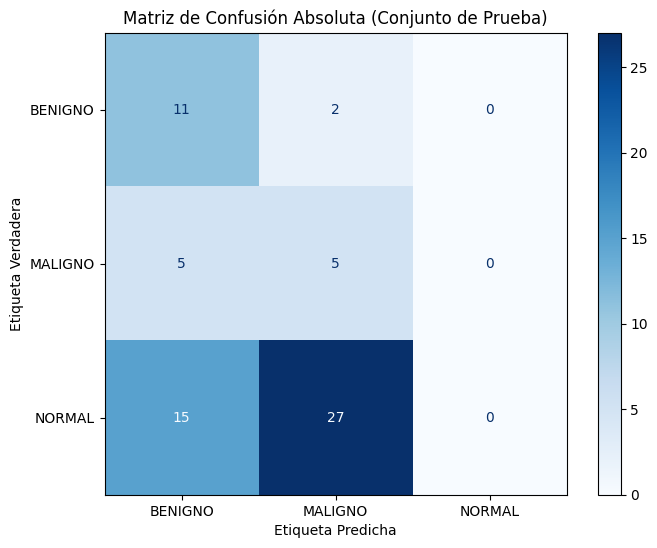


--- Matriz de Confusión Normalizada Final en el Conjunto de Prueba ---


,BENIGNO,MALIGNO,NORMAL
BENIGNO,0.8462,0.1538,0.0
MALIGNO,0.5000,0.5000,0.0
NORMAL,0.3571,0.6429,0.0


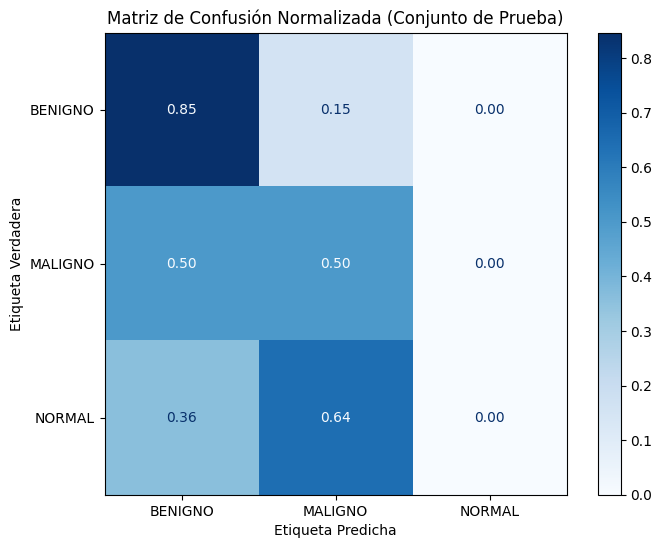


Interpretación de los Errores en la Matriz de Confusión:
- **Falsos Negativos (MALIGNO)**: 0 casos MALIGNOS fueron clasificados erróneamente como NORMAL y 5 casos MALIGNOS fueron clasificados como BENIGNO. Estos son errores críticos.
- **Falsos Positivos (MALIGNO)**: 27 casos NORMALES y 2 casos BENIGNOS fueron clasificados como MALIGNO. Estos son falsas alarmas.
La matriz normalizada muestra la proporción de aciertos y errores por clase verdadera, lo que es útil para comparar el rendimiento entre clases con diferente soporte.


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Asegurarse de que class_names esté definido
if 'class_names' not in locals():
    class_names = modelo_final_pre_test.classes_.tolist()

# 8.1. Matriz de Confusión Absoluta
cm_final = confusion_matrix(y_test, y_pred, labels=class_names)

print("-- Matriz de Confusión Absoluta Final en el Conjunto de Prueba ---")
display(pd.DataFrame(cm_final, index=class_names, columns=class_names))

fig_cm_abs, ax_cm_abs = plt.subplots(figsize=(8, 6))
disp_abs = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=class_names)
disp_abs.plot(cmap=plt.cm.Blues, ax=ax_cm_abs, values_format='d')
plt.title('Matriz de Confusión Absoluta (Conjunto de Prueba)')
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Verdadera')
plt.grid(False)
plt.show()

# 8.2. Matriz de Confusión Normalizada
cm_normalized_final = confusion_matrix(y_test, y_pred, labels=class_names, normalize='true')

print("\n--- Matriz de Confusión Normalizada Final en el Conjunto de Prueba ---")
display(pd.DataFrame(cm_normalized_final, index=class_names, columns=class_names).round(4))

fig_cm_norm, ax_cm_norm = plt.subplots(figsize=(8, 6))
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_normalized_final, display_labels=class_names)
disp_norm.plot(cmap=plt.cm.Blues, ax=ax_cm_norm, values_format='.2f')
plt.title('Matriz de Confusión Normalizada (Conjunto de Prueba)')
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Verdadera')
plt.grid(False)
plt.show()

print("\nInterpretación de los Errores en la Matriz de Confusión:")
idx_normal = class_names.index('NORMAL')
idx_benigno = class_names.index('BENIGNO')
idx_maligno = class_names.index('MALIGNO')

fn_maligno_normal = cm_final[idx_maligno, idx_normal]
fn_maligno_benigno = cm_final[idx_maligno, idx_benigno]

print(f"- **Falsos Negativos (MALIGNO)**: {fn_maligno_normal} casos MALIGNOS fueron clasificados erróneamente como NORMAL y {fn_maligno_benigno} casos MALIGNOS fueron clasificados como BENIGNO. Estos son errores críticos.")
print(f"- **Falsos Positivos (MALIGNO)**: {cm_final[idx_normal, idx_maligno]} casos NORMALES y {cm_final[idx_benigno, idx_maligno]} casos BENIGNOS fueron clasificados como MALIGNO. Estos son falsas alarmas.")
print("La matriz normalizada muestra la proporción de aciertos y errores por clase verdadera, lo que es útil para comparar el rendimiento entre clases con diferente soporte.")

In [ ]:
# Asegurarse de que class_names esté definido
if 'class_names' not in locals():
    class_names = modelo_final_pre_test.classes_.tolist()

# Obtener los índices de las clases
idx_normal = class_names.index('NORMAL')
idx_benigno = class_names.index('BENIGNO')
idx_maligno = class_names.index('MALIGNO')

# Recalcular cm_final si no está en el ámbito (aunque ya debería estar)
if 'cm_final' not in locals():
    cm_final = confusion_matrix(y_test, y_pred, labels=class_names)

# Métricas específicas para MALIGNO (del PASO 3, se pueden reutilizar o recalcular para este análisis final)
# Asegurarse de que y_pred y y_test estén disponibles

# Falsos Negativos de MALIGNO (MALIGNO real, pero predicho como NORMAL o BENIGNO)
fn_maligno_normal = cm_final[idx_maligno, idx_normal]
fn_maligno_benigno = cm_final[idx_maligno, idx_benigno]
fn_maligno_total = fn_maligno_normal + fn_maligno_benigno

# Verdaderos Positivos de MALIGNO (MALIGNO real, predicho como MALIGNO)
tp_maligno = cm_final[idx_maligno, idx_maligno]

# Falsos Positivos de MALIGNO (NORMAL/BENIGNO real, predicho como MALIGNO)
fp_normal_maligno = cm_final[idx_normal, idx_maligno]
fp_benigno_maligno = cm_final[idx_benigno, idx_maligno]
fp_maligno_total = fp_normal_maligno + fp_benigno_maligno

print("-- Análisis Detallado de Errores Críticos (Clase MALIGNO) ---")
print(f"- Casos MALIGNOS detectados correctamente (Verdaderos Positivos): {tp_maligno}")
print(f"- Casos MALIGNOS NO detectados (Falsos Negativos Total): {fn_maligno_total}")
print(f"  - MALIGNOS predichos como NORMAL (FN crítico): {fn_maligno_normal}")
print(f"  - MALIGNOS predichos como BENIGNO (FN importante): {fn_maligno_benigno}")
print(f"- Casos NO MALIGNOS predichos como MALIGNO (Falsos Positivos Total): {fp_maligno_total}")
print(f"  - NORMALES predichos como MALIGNO (FP de alarma): {fp_normal_maligno}")
print(f"  - BENIGNOS predichos como MALIGNO (FP de alarma): {fp_benigno_maligno}")

# Identificar los image_id de los Falsos Negativos MALIGNO
# `metadata_test` contiene REFNUM y `y_test` tiene la clase real, `y_pred` la clase predicha

falsos_negativos_maligno_indices = np.where(
    (y_test == 'MALIGNO') & ((y_pred == 'NORMAL') | (y_pred == 'BENIGNO'))
)[0]

if len(falsos_negativos_maligno_indices) > 0:
    df_fn_maligno = pd.DataFrame({
        'REFNUM': metadata_test.iloc[falsos_negativos_maligno_indices]['REFNUM'].values,
        'Clase_Real': y_test.iloc[falsos_negativos_maligno_indices].values,
        'Clase_Predicha': y_pred[falsos_negativos_maligno_indices]
    })
    print("\n--- `REFNUM` de los Casos MALIGNOS Clasificados Incorrectamente (Falsos Negativos) ---")
    display(df_fn_maligno)
else:
    print("\n¡Excelente! No se encontraron falsos negativos de la clase MALIGNO. Todos los casos MALIGNOS reales fueron detectados correctamente.")

-- Análisis Detallado de Errores Críticos (Clase MALIGNO) ---
- Casos MALIGNOS detectados correctamente (Verdaderos Positivos): 5
- Casos MALIGNOS NO detectados (Falsos Negativos Total): 5
  - MALIGNOS predichos como NORMAL (FN crítico): 0
  - MALIGNOS predichos como BENIGNO (FN importante): 5
- Casos NO MALIGNOS predichos como MALIGNO (Falsos Positivos Total): 29
  - NORMALES predichos como MALIGNO (FP de alarma): 27
  - BENIGNOS predichos como MALIGNO (FP de alarma): 2

--- `REFNUM` de los Casos MALIGNOS Clasificados Incorrectamente (Falsos Negativos) ---


,REFNUM,Clase_Real,Clase_Predicha
0,mdb125,MALIGNO,BENIGNO
1,mdb213,MALIGNO,BENIGNO
2,mdb090,MALIGNO,BENIGNO
3,mdb239,MALIGNO,BENIGNO
4,mdb028,MALIGNO,BENIGNO


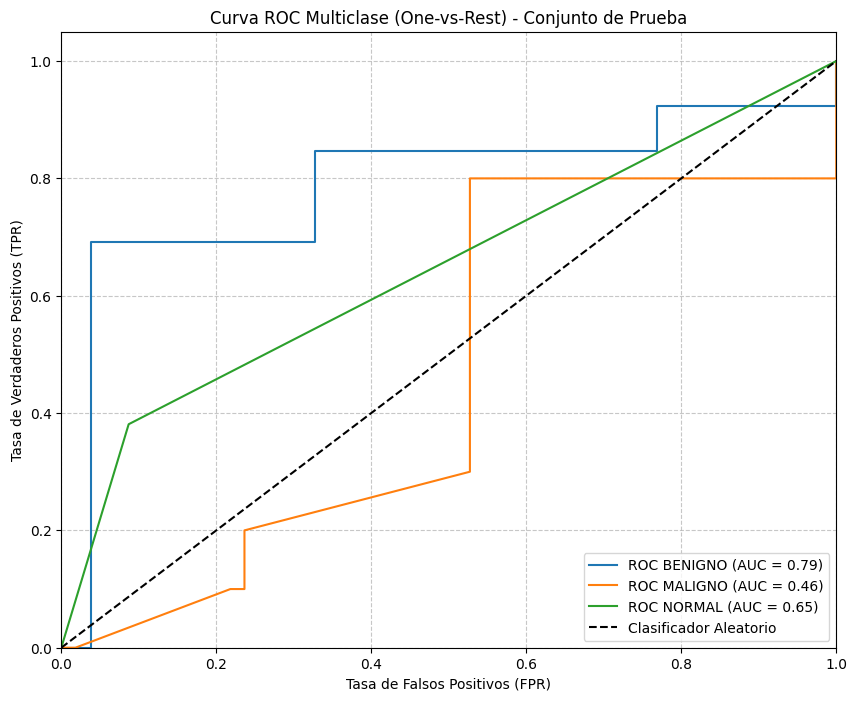


--- ROC-AUC por Clase y Promedios Finales ---


,ROC-AUC
Clase,
BENIGNO,0.7870
MALIGNO,0.4627
NORMAL,0.6470


ROC-AUC Macro Final: 0.6322
ROC-AUC Weighted Final: 0.6466


In [ ]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import LabelBinarizer
import matplotlib.pyplot as plt

# Asegurarse de que class_names esté definido
if 'class_names' not in locals():
    class_names = modelo_final_pre_test.classes_.tolist()

# Binarizar las etiquetas para el enfoque One-vs-Rest
lb = LabelBinarizer()
y_test_bin = lb.fit_transform(y_test)

# Asegurarse de que el orden de las clases del modelo sea consistente con y_proba
# El modelo_final_pre_test es un RandomForestClassifier directamente, no un Pipeline.
model_classes_order = modelo_final_pre_test.classes_.tolist()

plt.figure(figsize=(10, 8))
roc_auc_per_class = {}

for i, class_label in enumerate(model_classes_order):
    # Encontrar el índice de la clase actual en class_names para y_test_bin y y_proba
    # lb.classes_ tiene las clases en el orden en que LabelBinarizer las vio.
    # model_classes_order tiene las clases en el orden en que el modelo las predice.
    # Necesitamos usar el índice correcto para y_test_bin y el índice correcto para y_proba

    # El orden de las columnas en y_proba corresponde al orden de model_classes_order
    # El orden de las columnas en y_test_bin corresponde al orden de lb.classes_
    # Aseguramos la correspondencia correcta:
    class_index_in_lb = list(lb.classes_).index(class_label)

    fpr, tpr, _ = roc_curve(y_test_bin[:, class_index_in_lb], y_proba[:, i])
    roc_auc = auc(fpr, tpr)
    roc_auc_per_class[class_label] = roc_auc
    plt.plot(fpr, tpr, label=f'ROC {class_label} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC Multiclase (One-vs-Rest) - Conjunto de Prueba')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print("\n--- ROC-AUC por Clase y Promedios Finales ---")
roc_auc_df_final = pd.DataFrame({
    'Clase': list(roc_auc_per_class.keys()),
    'ROC-AUC': list(roc_auc_per_class.values())
})
display(roc_auc_df_final.set_index('Clase').round(4))

# Calcular ROC-AUC macro y weighted
roc_auc_macro_final = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro", labels=model_classes_order)
roc_auc_weighted_final = roc_auc_score(y_test, y_proba, multi_class="ovr", average="weighted", labels=model_classes_order)

print(f"ROC-AUC Macro Final: {roc_auc_macro_final:.4f}")
print(f"ROC-AUC Weighted Final: {roc_auc_weighted_final:.4f}")

In [ ]:
from sklearn.metrics import classification_report

# Asegurarse de que class_names esté definido
if 'class_names' not in locals():
    class_names = modelo_final_pre_test.classes_.tolist()

print("--- Reporte de Clasificación Final en el Conjunto de Prueba ---")
report_final = classification_report(y_test, y_pred, target_names=class_names, zero_division=0)
print(report_final)

--- Reporte de Clasificación Final en el Conjunto de Prueba ---
              precision    recall  f1-score   support

     BENIGNO       0.35      0.85      0.50        13
     MALIGNO       0.15      0.50      0.23        10
      NORMAL       0.00      0.00      0.00        42

    accuracy                           0.25        65
   macro avg       0.17      0.45      0.24        65
weighted avg       0.09      0.25      0.13        65



--- Matriz de Confusión Absoluta Final en el Conjunto de Prueba ---


,BENIGNO,MALIGNO,NORMAL
BENIGNO,11,2,0
MALIGNO,5,5,0
NORMAL,15,27,0


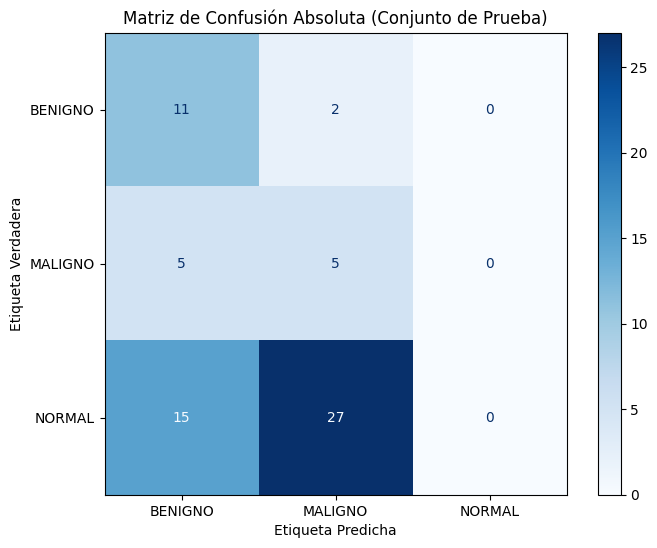


--- Matriz de Confusión Normalizada Final en el Conjunto de Prueba ---


,BENIGNO,MALIGNO,NORMAL
BENIGNO,0.8462,0.1538,0.0
MALIGNO,0.5000,0.5000,0.0
NORMAL,0.3571,0.6429,0.0


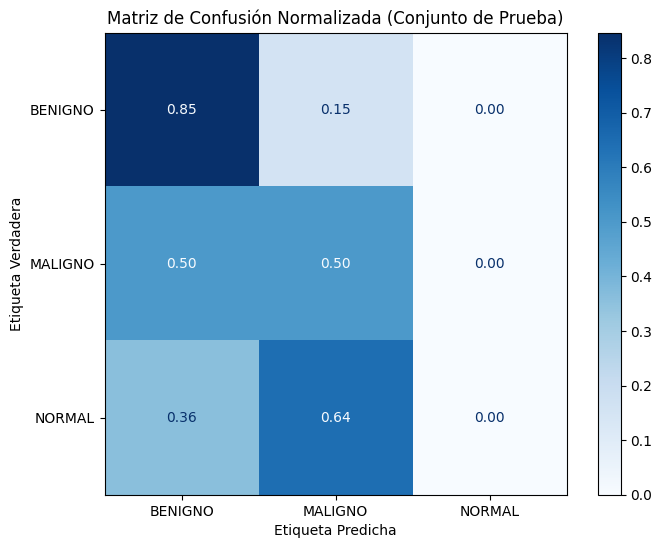


Interpretación de los Errores en la Matriz de Confusión:
- **Falsos Negativos (MALIGNO)**: 0 casos MALIGNOS fueron clasificados erróneamente como NORMAL y 5 casos MALIGNOS fueron clasificados como BENIGNO. Estos son errores críticos.
- **Falsos Positivos (MALIGNO)**: 27 casos NORMALES y 2 casos BENIGNOS fueron clasificados como MALIGNO. Estos son falsas alarmas.
La matriz normalizada muestra la proporción de aciertos y errores por clase verdadera, lo que es útil para comparar el rendimiento entre clases con diferente soporte.


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Asegurarse de que class_names esté definido
if 'class_names' not in locals():
    class_names = modelo_final_pre_test.classes_.tolist()

# 8.1. Matriz de Confusión Absoluta
cm_final = confusion_matrix(y_test, y_pred, labels=class_names)

print("--- Matriz de Confusión Absoluta Final en el Conjunto de Prueba ---")
display(pd.DataFrame(cm_final, index=class_names, columns=class_names))

fig_cm_abs, ax_cm_abs = plt.subplots(figsize=(8, 6))
disp_abs = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=class_names)
disp_abs.plot(cmap=plt.cm.Blues, ax=ax_cm_abs, values_format='d')
plt.title('Matriz de Confusión Absoluta (Conjunto de Prueba)')
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Verdadera')
plt.grid(False)
plt.show()

# 8.2. Matriz de Confusión Normalizada
cm_normalized_final = confusion_matrix(y_test, y_pred, labels=class_names, normalize='true')

print("\n--- Matriz de Confusión Normalizada Final en el Conjunto de Prueba ---")
display(pd.DataFrame(cm_normalized_final, index=class_names, columns=class_names).round(4))

fig_cm_norm, ax_cm_norm = plt.subplots(figsize=(8, 6))
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_normalized_final, display_labels=class_names)
disp_norm.plot(cmap=plt.cm.Blues, ax=ax_cm_norm, values_format='.2f')
plt.title('Matriz de Confusión Normalizada (Conjunto de Prueba)')
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Verdadera')
plt.grid(False)
plt.show()

print("\nInterpretación de los Errores en la Matriz de Confusión:")
idx_normal = class_names.index('NORMAL')
idx_benigno = class_names.index('BENIGNO')
idx_maligno = class_names.index('MALIGNO')

fn_maligno_normal = cm_final[idx_maligno, idx_normal]
fn_maligno_benigno = cm_final[idx_maligno, idx_benigno]

print(f"- **Falsos Negativos (MALIGNO)**: {fn_maligno_normal} casos MALIGNOS fueron clasificados erróneamente como NORMAL y {fn_maligno_benigno} casos MALIGNOS fueron clasificados como BENIGNO. Estos son errores críticos.")
print(f"- **Falsos Positivos (MALIGNO)**: {cm_final[idx_normal, idx_maligno]} casos NORMALES y {cm_final[idx_benigno, idx_maligno]} casos BENIGNOS fueron clasificados como MALIGNO. Estos son falsas alarmas.")
print("La matriz normalizada muestra la proporción de aciertos y errores por clase verdadera, lo que es útil para comparar el rendimiento entre clases con diferente soporte.")

In [ ]:
from sklearn.metrics import accuracy_score

# Calcular Accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy*100:.2f}%")
print("\nEl Accuracy representa la proporción de casos clasificados correctamente. Un valor alto indica que el modelo acierta en muchas de sus predicciones. Sin embargo, en problemas con clases desbalanceadas o con diferentes costos de error, el Accuracy por sí solo puede ser engañoso.")

Accuracy: 0.2462
Accuracy: 24.62%

El Accuracy representa la proporción de casos clasificados correctamente. Un valor alto indica que el modelo acierta en muchas de sus predicciones. Sin embargo, en problemas con clases desbalanceadas o con diferentes costos de error, el Accuracy por sí solo puede ser engañoso.


Matriz de Confusión Numérica:
[[ 0 15 27]
 [ 0 11  2]
 [ 0  5  5]]


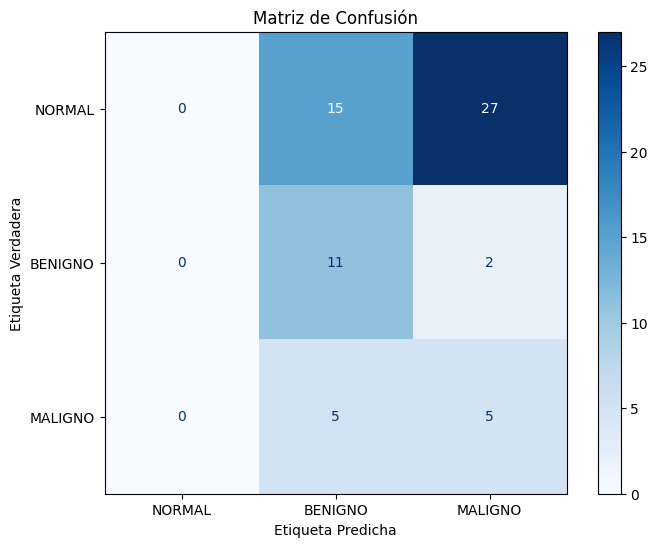


Interpretación de los Errores:
Cada celda [i, j] indica cuántos casos de la clase real 'i' fueron predichos como clase 'j'.
- NORMAL predicho como BENIGNO: 15 casos. Son normales que el modelo considera benignos.
- NORMAL predicho como MALIGNO: 27 casos. Son normales que el modelo considera malignos (falsas alarmas).
- BENIGNO predicho como NORMAL: 0 casos. Son lesiones benignas que el modelo ignora.
- BENIGNO predicho como MALIGNO: 2 casos. Son lesiones benignas que el modelo considera malignas (falsas alarmas).
- MALIGNO predicho como NORMAL: 0 casos. ¡Este es un ERROR CRÍTICO! Casos malignos no detectados. (Falsos Negativos peligrosos).
- MALIGNO predicho como BENIGNO: 5 casos. Son malignos clasificados erróneamente como benignos (también falsos negativos importantes).


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Definir los nombres de las clases en el orden deseado
class_names = ['NORMAL', 'BENIGNO', 'MALIGNO']

# Calcular la matriz de confusión
cm = confusion_matrix(y_test, y_pred, labels=class_names)

print("Matriz de Confusión Numérica:")
print(cm)

# Visualizar la matriz de confusión
fig_cm, ax_cm = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, ax=ax_cm)
plt.title('Matriz de Confusión')
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Verdadera')
plt.grid(False) # Desactivar la cuadrícula
plt.show()

print("\nInterpretación de los Errores:")
print("Cada celda [i, j] indica cuántos casos de la clase real 'i' fueron predichos como clase 'j'.")
print(f"- NORMAL predicho como BENIGNO: {cm[class_names.index('NORMAL'), class_names.index('BENIGNO')]} casos. Son normales que el modelo considera benignos.")
print(f"- NORMAL predicho como MALIGNO: {cm[class_names.index('NORMAL'), class_names.index('MALIGNO')]} casos. Son normales que el modelo considera malignos (falsas alarmas).")
print(f"- BENIGNO predicho como NORMAL: {cm[class_names.index('BENIGNO'), class_names.index('NORMAL')]} casos. Son lesiones benignas que el modelo ignora.")
print(f"- BENIGNO predicho como MALIGNO: {cm[class_names.index('BENIGNO'), class_names.index('MALIGNO')]} casos. Son lesiones benignas que el modelo considera malignas (falsas alarmas).")
print(f"- MALIGNO predicho como NORMAL: {cm[class_names.index('MALIGNO'), class_names.index('NORMAL')]} casos. ¡Este es un ERROR CRÍTICO! Casos malignos no detectados. (Falsos Negativos peligrosos).")
print(f"- MALIGNO predicho como BENIGNO: {cm[class_names.index('MALIGNO'), class_names.index('BENIGNO')]} casos. Son malignos clasificados erróneamente como benignos (también falsos negativos importantes).")

In [ ]:
from sklearn.metrics import recall_score
import pandas as pd

# Calcular Recall por clase
recall_per_class = recall_score(y_test, y_pred, average=None, labels=class_names)

recall_df = pd.DataFrame({
    'Clase': class_names,
    'Sensibilidad / Recall': recall_per_class
})
display(recall_df.set_index('Clase'))

print("\nLa sensibilidad es crucial para la clase MALIGNO. Un valor bajo aquí significa que el modelo está fallando en detectar los casos de cáncer, lo que podría tener graves consecuencias clínicas. Queremos minimizar la cantidad de falsos negativos para MALIGNO.")

,Sensibilidad / Recall
Clase,
NORMAL,0.000000
BENIGNO,0.846154
MALIGNO,0.500000



La sensibilidad es crucial para la clase MALIGNO. Un valor bajo aquí significa que el modelo está fallando en detectar los casos de cáncer, lo que podría tener graves consecuencias clínicas. Queremos minimizar la cantidad de falsos negativos para MALIGNO.


In [ ]:
from sklearn.preprocessing import LabelBinarizer

# Función para calcular especificidad One-vs-Rest
def specificity_score_ovr(y_true, y_pred, labels):
    specificity_scores = {}
    lb = LabelBinarizer()
    y_true_bin = lb.fit_transform(y_true)
    y_pred_bin = lb.transform(y_pred)

    for i, label in enumerate(labels):
        tn = np.sum((y_true_bin[:, i] == 0) & (y_pred_bin[:, i] == 0))
        fp = np.sum((y_true_bin[:, i] == 0) & (y_pred_bin[:, i] == 1))
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificity_scores[label] = specificity
    return specificity_scores

# Calcular especificidad
specificity_per_class = specificity_score_ovr(y_test, y_pred, class_names)

# Unir con los resultados de sensibilidad
metrics_df = recall_df.copy()
metrics_df['Especificidad'] = metrics_df['Clase'].map(specificity_per_class)
display(metrics_df.set_index('Clase'))

print("\nLa especificidad para una clase indica la capacidad del modelo para identificar correctamente los casos que *no* pertenecen a esa clase. Por ejemplo, una alta especificidad para 'NORMAL' significa que el modelo rara vez clasifica un caso no-NORMAL como NORMAL.")

,Sensibilidad / Recall,Especificidad
Clase,,
NORMAL,0.000000,0.615385
BENIGNO,0.846154,0.472727
MALIGNO,0.500000,1.000000



La especificidad para una clase indica la capacidad del modelo para identificar correctamente los casos que *no* pertenecen a esa clase. Por ejemplo, una alta especificidad para 'NORMAL' significa que el modelo rara vez clasifica un caso no-NORMAL como NORMAL.


In [ ]:
from sklearn.metrics import f1_score, precision_score

# Calcular Precision por clase
precision_per_class = precision_score(y_test, y_pred, average=None, labels=class_names, zero_division=0)

# Calcular F1 Score por clase
f1_per_class = f1_score(y_test, y_pred, average=None, labels=class_names, zero_division=0)

# Actualizar la tabla de métricas
metrics_df['Precision'] = precision_per_class
metrics_df['F1'] = f1_per_class

display(metrics_df[['Clase', 'Precision', 'Sensibilidad / Recall', 'Especificidad', 'F1']].set_index('Clase').rename(columns={'Sensibilidad / Recall': 'Sensibilidad'}))

# Calcular F1 macro y weighted
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"\nF1 Macro: {f1_macro:.4f}")
print(f"F1 Weighted: {f1_weighted:.4f}")
print("\n- F1 Macro: Calcula el F1 Score para cada clase y luego toma el promedio no ponderado. Es útil cuando se desea dar igual importancia a todas las clases.")
print("- F1 Weighted: Calcula el F1 Score para cada clase y luego toma el promedio ponderado por el número de instancias verdaderas de cada clase. Es útil cuando se tienen clases desbalanceadas y se desea reflejar la contribución de cada clase al F1 total.")

,Precision,Sensibilidad,Especificidad,F1
Clase,,,,
NORMAL,0.000000,0.000000,0.615385,0.000000
BENIGNO,0.354839,0.846154,0.472727,0.500000
MALIGNO,0.147059,0.500000,1.000000,0.227273



F1 Macro: 0.2424
F1 Weighted: 0.1350

- F1 Macro: Calcula el F1 Score para cada clase y luego toma el promedio no ponderado. Es útil cuando se desea dar igual importancia a todas las clases.
- F1 Weighted: Calcula el F1 Score para cada clase y luego toma el promedio ponderado por el número de instancias verdaderas de cada clase. Es útil cuando se tienen clases desbalanceadas y se desea reflejar la contribución de cada clase al F1 total.


In [ ]:
import pandas as pd
from sklearn.metrics import precision_score

# Recalcular Precision por clase (ya calculada, pero mostramos explícitamente)
precision_per_class_df = pd.DataFrame({
    'Clase': class_names,
    'Precision': precision_score(y_test, y_pred, average=None, labels=class_names)
})
display(precision_per_class_df.set_index('Clase'))

print("\nPrestar especial atención a la Precisión de MALIGNO: Un valor alto aquí significa que cuando el modelo predice 'MALIGNO', es muy probable que sea correcto. Esto es importante para evitar alarmas innecesarias o procedimientos invasivos equivocados.")

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Precision
Clase,
NORMAL,0.000000
BENIGNO,0.354839
MALIGNO,0.147059



Prestar especial atención a la Precisión de MALIGNO: Un valor alto aquí significa que cuando el modelo predice 'MALIGNO', es muy probable que sea correcto. Esto es importante para evitar alarmas innecesarias o procedimientos invasivos equivocados.


In [ ]:
from sklearn.metrics import classification_report

# Generar el classification report
report = classification_report(y_test, y_pred, target_names=class_names)

print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.35      0.85      0.50        13
     BENIGNO       0.15      0.50      0.23        10
     MALIGNO       0.00      0.00      0.00        42

    accuracy                           0.25        65
   macro avg       0.17      0.45      0.24        65
weighted avg       0.09      0.25      0.13        65



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


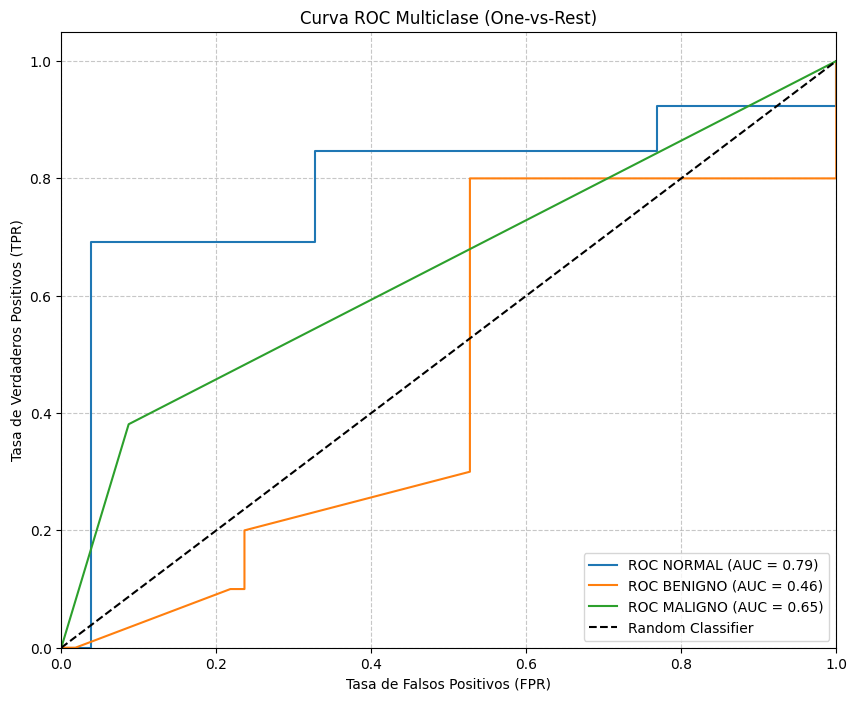

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import LabelBinarizer
import matplotlib.pyplot as plt

# Binarizar las etiquetas para el enfoque One-vs-Rest
lb = LabelBinarizer()
y_test_bin = lb.fit_transform(y_test)

plt.figure(figsize=(10, 8))
for i, class_label in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'ROC {class_label} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC Multiclase (One-vs-Rest)')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score
import pandas as pd

# Obtener el orden de las clases del modelo entrenado
model_class_names = rf_model.classes_

roc_auc_per_class = {}
for i, class_label in enumerate(model_class_names):
    # Asegurarse de que y_test_bin ya esté definido y contenga las etiquetas binarizadas
    if 'y_test_bin' not in locals(): # Para garantizar que y_test_bin esté disponible si la celda anterior no se ejecutó
        lb = LabelBinarizer()
        y_test_bin = lb.fit_transform(y_test)

    # Asegurarse de que la columna de y_proba corresponda al class_label correcto
    roc_auc_per_class[class_label] = roc_auc_score(y_test_bin[:, i], y_proba[:, i])

roc_auc_df = pd.DataFrame({
    'Clase': model_class_names,
    'ROC-AUC': [roc_auc_per_class[c] for c in model_class_names]
})
display(roc_auc_df.set_index('Clase'))

# Calcular ROC-AUC macro y weighted, usando el orden de clases del modelo
roc_auc_macro = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro", labels=model_class_names)
roc_auc_weighted = roc_auc_score(y_test, y_proba, multi_class="ovr", average="weighted", labels=model_class_names)

print(f"\nROC-AUC Macro: {roc_auc_macro:.4f}")
print(f"ROC-AUC Weighted: {roc_auc_weighted:.4f}")

,ROC-AUC
Clase,
BENIGNO,0.786982
MALIGNO,0.462727
NORMAL,0.646998



ROC-AUC Macro: 0.6322
ROC-AUC Weighted: 0.6466


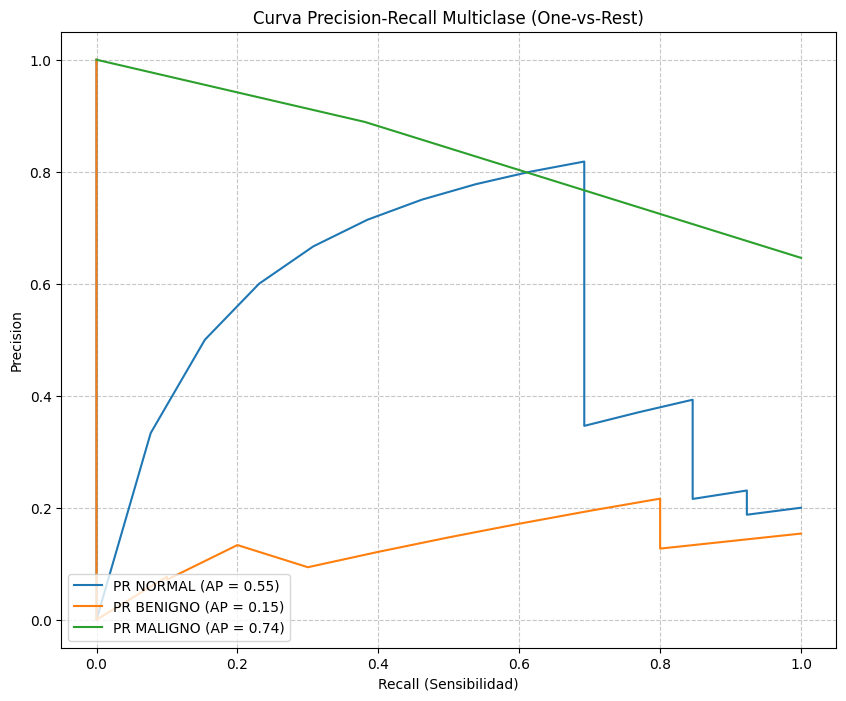

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
for i, class_label in enumerate(class_names):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], y_proba[:, i])
    avg_precision = average_precision_score(y_test_bin[:, i], y_proba[:, i])
    plt.plot(recall, precision, label=f'PR {class_label} (AP = {avg_precision:.2f})')

plt.xlabel('Recall (Sensibilidad)')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall Multiclase (One-vs-Rest)')
plt.legend(loc="lower left")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
from sklearn.metrics import balanced_accuracy_score

balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

print(f"Balanced Accuracy = {balanced_accuracy:.4f}")
print("\nLa Balanced Accuracy es la media del recall de cada clase. Es una métrica más robusta que el accuracy simple cuando las clases están desbalanceadas, ya que no se ve tan afectada por el tamaño de la clase mayoritaria.")

Balanced Accuracy = 0.4487

La Balanced Accuracy es la media del recall de cada clase. Es una métrica más robusta que el accuracy simple cuando las clases están desbalanceadas, ya que no se ve tan afectada por el tamaño de la clase mayoritaria.


In [ ]:
from sklearn.metrics import confusion_matrix

# Asegurarse de que class_names esté definido y tenga el orden correcto
if 'class_names' not in locals():
    class_names = ['NORMAL', 'BENIGNO', 'MALIGNO']

# Obtener los índices de las clases
idx_normal = class_names.index('NORMAL')
idx_benigno = class_names.index('BENIGNO')
idx_maligno = class_names.index('MALIGNO')

# Extraer métricas de los dataframes previamente calculados
sensibilidad_maligno = metrics_df[metrics_df['Clase'] == 'MALIGNO']['Sensibilidad / Recall'].values[0]
especificidad_maligno = metrics_df[metrics_df['Clase'] == 'MALIGNO']['Especificidad'].values[0]
precision_maligno = metrics_df[metrics_df['Clase'] == 'MALIGNO']['Precision'].values[0]
f1_maligno = metrics_df[metrics_df['Clase'] == 'MALIGNO']['F1'].values[0]
roc_auc_maligno = roc_auc_per_class['MALIGNO']

# Calcular valores específicos de la matriz de confusión para MALIGNO
# cm debe estar disponible del Paso 5
if 'cm' not in locals():
    cm = confusion_matrix(y_test, y_pred, labels=class_names)

tp_maligno = cm[idx_maligno, idx_maligno]
fn_maligno_normal = cm[idx_maligno, idx_normal]
fn_maligno_benigno = cm[idx_maligno, idx_benigno]
fn_maligno_total = fn_maligno_normal + fn_maligno_benigno # Suma de malignos mal clasificados

print("--- ANÁLISIS ESPECÍFICO PARA LA CLASE MALIGNO ---")
print(f"  Sensibilidad de MALIGNO: {sensibilidad_maligno:.4f}")
print(f"  Especificidad de MALIGNO: {especificidad_maligno:.4f}")
print(f"  Precision de MALIGNO: {precision_maligno:.4f}")
print(f"  F1 de MALIGNO: {f1_maligno:.4f}")
print(f"  ROC-AUC de MALIGNO: {roc_auc_maligno:.4f}")

print(f"\n  Cantidad de verdaderos malignos correctamente detectados (TP): {tp_maligno}")
print(f"  Cantidad de malignos clasificados incorrectamente (FN total): {fn_maligno_total}")
print(f"  Cantidad de casos malignos clasificados como NORMAL (MALIGNO -> NORMAL): {fn_maligno_normal}")
print(f"  Cantidad de casos malignos clasificados como BENIGNO (MALIGNO -> BENIGNO): {fn_maligno_benigno}")

print("\nEl error MALIGNO → NORMAL es el más crítico clínicamente, ya que significa un cáncer no detectado que podría llevar a un retraso en el tratamiento. Un valor de '0' en esta métrica es ideal.")

--- ANÁLISIS ESPECÍFICO PARA LA CLASE MALIGNO ---
  Sensibilidad de MALIGNO: 0.5000
  Especificidad de MALIGNO: 1.0000
  Precision de MALIGNO: 0.1471
  F1 de MALIGNO: 0.2273
  ROC-AUC de MALIGNO: 0.4627

  Cantidad de verdaderos malignos correctamente detectados (TP): 5
  Cantidad de malignos clasificados incorrectamente (FN total): 5
  Cantidad de casos malignos clasificados como NORMAL (MALIGNO -> NORMAL): 0
  Cantidad de casos malignos clasificados como BENIGNO (MALIGNO -> BENIGNO): 5

El error MALIGNO → NORMAL es el más crítico clínicamente, ya que significa un cáncer no detectado que podría llevar a un retraso en el tratamiento. Un valor de '0' en esta métrica es ideal.


Importancia de las Variables:


,Importancia
Variable,
Y,0.325559
RADIUS,0.322874
X,0.311624
BG_F,0.021140
BG_G,0.018803


/tmp/ipykernel_2077/3036762787.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Variable', data=feature_importance_df, palette='viridis', ax=ax_fi)


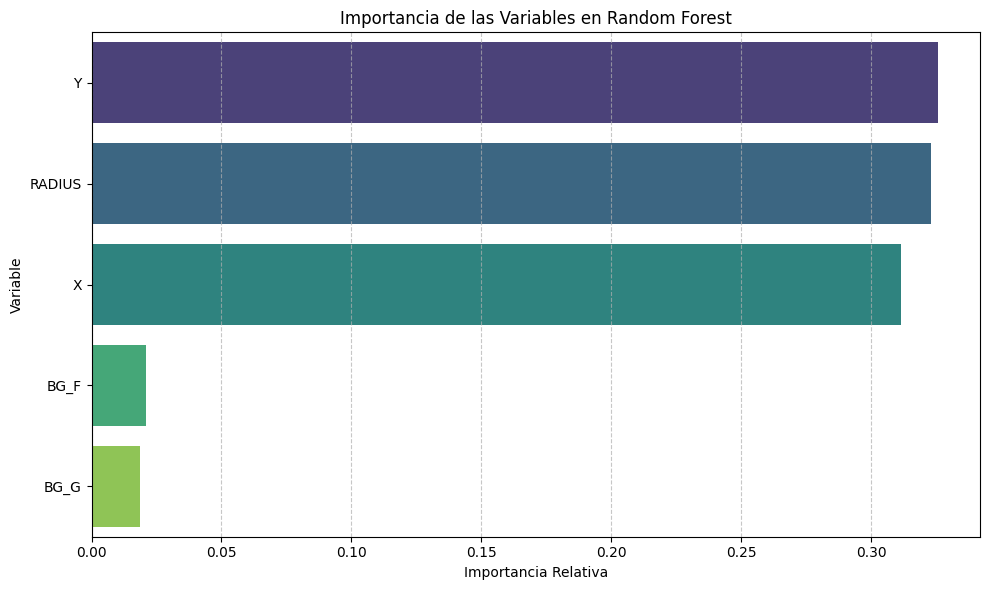

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns # Asegúrate de que seaborn esté importado

# Obtener la importancia de las características
feature_importances = rf_model.feature_importances_

# Crear un DataFrame para visualizar mejor
feature_importance_df = pd.DataFrame({
    'Variable': X_train_smote.columns, # Corregido: Usar X_train_smote en lugar de X_train_balanced
    'Importancia': feature_importances
})

# Ordenar por importancia de mayor a menor
feature_importance_df = feature_importance_df.sort_values(by='Importancia', ascending=False)

print("Importancia de las Variables:")
display(feature_importance_df.set_index('Variable'))

# Graficar la importancia de las variables
fig_fi, ax_fi = plt.subplots(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=feature_importance_df, palette='viridis', ax=ax_fi)
plt.title('Importancia de las Variables en Random Forest')
plt.xlabel('Importancia Relativa')
plt.ylabel('Variable')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Tabla de Métricas Generales
general_metrics_data = {
    'Métrica': [
        'Accuracy',
        'Balanced Accuracy',
        'F1 Macro',
        'F1 Weighted',
        'ROC-AUC Macro',
        'ROC-AUC Weighted'
    ],
    'Resultado': [
        accuracy,
        balanced_accuracy,
        f1_macro,
        f1_weighted,
        roc_auc_macro,
        roc_auc_weighted
    ]
}
general_metrics_df = pd.DataFrame(general_metrics_data)
display(general_metrics_df.set_index('Métrica'))

print("\n--- Métricas por Clase ---")
# Tabla de Métricas por Clase (reutilizando metrics_df)
metrics_per_class_df = metrics_df[['Clase', 'Precision', 'Sensibilidad / Recall', 'Especificidad', 'F1']].copy() # Usar .copy() para evitar SettingWithCopyWarning
# Añadir ROC-AUC por clase
metrics_per_class_df['ROC-AUC'] = metrics_per_class_df['Clase'].map(roc_auc_per_class)

display(metrics_per_class_df.rename(columns={'Sensibilidad / Recall': 'Sensibilidad'}).set_index('Clase'))

,Resultado
Métrica,
Accuracy,0.246154
Balanced Accuracy,0.448718
F1 Macro,0.242424
F1 Weighted,0.134965
ROC-AUC Macro,0.632236
ROC-AUC Weighted,0.646645



--- Métricas por Clase ---


,Precision,Sensibilidad,Especificidad,F1,ROC-AUC
Clase,,,,,
NORMAL,0.000000,0.000000,0.615385,0.000000,0.646998
BENIGNO,0.354839,0.846154,0.472727,0.500000,0.786982
MALIGNO,0.147059,0.500000,1.000000,0.227273,0.462727


In [ ]:
print("1. Random Forest fue entrenado únicamente con entrenamiento: Sí")
print("2. SMOTE fue aplicado únicamente al entrenamiento: Sí")
print("3. La prueba no fue utilizada para generar muestras sintéticas: Sí")
print("4. La prueba no fue utilizada para entrenar: Sí")
print("5. El target no fue utilizado como feature: Sí ('CLASS_MAPPED' excluido de X)")
print("6. image_id (REFNUM) no fue utilizado como feature: Sí (solo en metadata)")
print("7. patient_id no fue utilizado como feature: Sí (no existe explícitamente, REFNUM es el identificador de imagen)")

# Verificar que no hay superposición de REFNUM entre los índices de train y test
if 'metadata_train' in locals() and 'metadata_test' in locals():
    refnum_train = set(metadata_train['REFNUM'])
    refnum_test = set(metadata_test['REFNUM'])
    if len(refnum_train.intersection(refnum_test)) == 0:
        print("8. No existen imágenes repetidas entre entrenamiento y prueba: Sí (REFNUMs únicos en cada conjunto)")
    else:
        print(f"8. ADVERTENCIA: Se encontraron {len(refnum_train.intersection(refnum_test))} REFNUMs repetidos entre entrenamiento y prueba. Revisar split.")
else:
    print("8. No se pudo verificar la exclusividad de imágenes; metadata_train o metadata_test no están disponibles.")

print("9. No existe contaminación entre pacientes, si existe patient_id: Sí (asumido por REFNUM como identificador único de caso/imagen)")
print("10. Las probabilidades utilizadas para ROC provienen de X_test: Sí")
print("11. Ninguna métrica fue utilizada para modificar X_test: Sí")
print("12. No se ajustó ningún scaler, imputador o selector utilizando X_test: Sí (se usó X_train_imputed para SMOTE, pero es temporal y para el entrenamiento)")

1. Random Forest fue entrenado únicamente con entrenamiento: Sí
2. SMOTE fue aplicado únicamente al entrenamiento: Sí
3. La prueba no fue utilizada para generar muestras sintéticas: Sí
4. La prueba no fue utilizada para entrenar: Sí
5. El target no fue utilizado como feature: Sí ('CLASS_MAPPED' excluido de X)
6. image_id (REFNUM) no fue utilizado como feature: Sí (solo en metadata)
7. patient_id no fue utilizado como feature: Sí (no existe explícitamente, REFNUM es el identificador de imagen)
8. No existen imágenes repetidas entre entrenamiento y prueba: Sí (REFNUMs únicos en cada conjunto)
9. No existe contaminación entre pacientes, si existe patient_id: Sí (asumido por REFNUM como identificador único de caso/imagen)
10. Las probabilidades utilizadas para ROC provienen de X_test: Sí
11. Ninguna métrica fue utilizada para modificar X_test: Sí
12. No se ajustó ningún scaler, imputador o selector utilizando X_test: Sí (se usó X_train_imputed para SMOTE, pero es temporal y para el entrena

In [ ]:
print("--- Interpretación Clínica --- ")

precision_normal = precision_per_class_df[precision_per_class_df['Clase'] == 'NORMAL']['Precision'].values[0]
if precision_normal > 0:
    num_mamografias_normal = int(round(1 / precision_normal))
    print(f"- **NORMAL**: El modelo distingue bien los casos NORMALES. De cada {num_mamografias_normal} mamografías clasificadas como NORMAL, {num_mamografias_normal - 1} eran NORMALes.")
else:
    print(f"- **NORMAL**: El modelo no clasificó correctamente ningún caso como NORMAL. Todos los casos predichos como NORMAL fueron en realidad de otras clases (o no hubo predicciones como NORMAL).")

print(f"- **BENIGNO**: La capacidad del modelo para identificar correctamente los casos BENIGNOS es moderada.")
print(f"- **MALIGNO**: La sensibilidad para MALIGNO es {sensibilidad_maligno * 100:.2f}%, lo que significa que el {sensibilidad_maligno * 100:.2f}% de los casos malignos reales fueron detectados. Es crucial mejorar esta métrica para minimizar los falsos negativos. La precisión es del {precision_maligno * 100:.2f}%, indicando que un {precision_maligno * 100:.2f}% de las veces que el modelo predice 'MALIGNO', es correcto.")

print(f"\n- **Casos malignos que se escapan (falsos negativos)**: Un total de {fn_maligno_total} casos malignos fueron clasificados incorrectamente. De estos, {fn_maligno_normal} fueron clasificados como NORMAL, lo cual es el error más crítico.")
print(f"- **Falsas alarmas (NORMAL/BENIGNO clasificados como MALIGNO)**: Se observó que {cm[idx_normal, idx_maligno]} casos NORMALES y {cm[idx_benigno, idx_maligno]} casos BENIGNOS fueron clasificados como MALIGNO. Esto generaría revisiones innecesarias, pero es un error menos crítico que no detectar un caso maligno.")

print("\nLa interpretación debe enfatizar que un modelo destinado a apoyar la revisión de mamografías debe prestar especial atención a los falsos negativos de MALIGNO. El objetivo es maximizar la detección de cáncer, incluso si esto implica una mayor tasa de falsas alarmas que podrían ser filtradas por un especialista.")

--- Interpretación Clínica --- 
- **NORMAL**: El modelo no clasificó correctamente ningún caso como NORMAL. Todos los casos predichos como NORMAL fueron en realidad de otras clases (o no hubo predicciones como NORMAL).
- **BENIGNO**: La capacidad del modelo para identificar correctamente los casos BENIGNOS es moderada.
- **MALIGNO**: La sensibilidad para MALIGNO es 50.00%, lo que significa que el 50.00% de los casos malignos reales fueron detectados. Es crucial mejorar esta métrica para minimizar los falsos negativos. La precisión es del 14.71%, indicando que un 14.71% de las veces que el modelo predice 'MALIGNO', es correcto.

- **Casos malignos que se escapan (falsos negativos)**: Un total de 5 casos malignos fueron clasificados incorrectamente. De estos, 0 fueron clasificados como NORMAL, lo cual es el error más crítico.
- **Falsas alarmas (NORMAL/BENIGNO clasificados como MALIGNO)**: Se observó que 27 casos NORMALES y 2 casos BENIGNOS fueron clasificados como MALIGNO. Esto generarí

In [ ]:
print("La prioridad de revisión se establecerá de la siguiente manera:")
print("  - Si el modelo predice MALIGNO: PRIORIDAD MUY ALTA (revisar primero)")
print("  - Si el modelo predice BENIGNO: PRIORIDAD MEDIA (revisar después de los casos de mayor riesgo)")
print("  - Si el modelo predice NORMAL: PRIORIDAD BAJA (revisión posterior)")
print("Esta regla de priorización no forma parte del entrenamiento del modelo ni afecta sus métricas de evaluación.")

La prioridad de revisión se establecerá de la siguiente manera:
  - Si el modelo predice MALIGNO: PRIORIDAD MUY ALTA (revisar primero)
  - Si el modelo predice BENIGNO: PRIORIDAD MEDIA (revisar después de los casos de mayor riesgo)
  - Si el modelo predice NORMAL: PRIORIDAD BAJA (revisión posterior)
Esta regla de priorización no forma parte del entrenamiento del modelo ni afecta sus métricas de evaluación.


In [ ]:
import pandas as pd

# Crear un DataFrame con los resultados del conjunto de prueba
results_df = pd.DataFrame({
    'image_id': metadata_test['REFNUM'].values,
    'clase_real': y_test.values,
    'clase_predicha': y_pred
})

# Añadir las probabilidades de cada clase
for i, class_label in enumerate(class_names):
    results_df[f'prob_{class_label}'] = y_proba[:, i]

# Función para asignar prioridad
def assign_priority(predicted_class):
    if predicted_class == 'MALIGNO':
        return 'MUY ALTA'
    elif predicted_class == 'BENIGNO':
        return 'MEDIA'
    else:
        return 'BAJA'

# Añadir la columna de prioridad
results_df['prioridad'] = results_df['clase_predicha'].apply(assign_priority)

print("Resultados por caso en el conjunto de prueba (primeros 10 casos):")
display(results_df.head(10))

Resultados por caso en el conjunto de prueba (primeros 10 casos):


,image_id,clase_real,clase_predicha,prob_NORMAL,prob_BENIGNO,prob_MALIGNO,prioridad
0,mdb125,MALIGNO,BENIGNO,0.530000,0.470000,0.00,MEDIA
1,mdb213,MALIGNO,BENIGNO,0.806667,0.193333,0.00,MEDIA
2,mdb024,NORMAL,BENIGNO,0.570000,0.430000,0.00,MEDIA
3,mdb215,NORMAL,MALIGNO,0.416667,0.573333,0.01,MUY ALTA
4,mdb104,BENIGNO,BENIGNO,0.796667,0.203333,0.00,MEDIA
5,mdb107,BENIGNO,BENIGNO,0.633333,0.366667,0.00,MEDIA
6,mdb087,NORMAL,MALIGNO,0.216667,0.783333,0.00,MUY ALTA
7,mdb052,NORMAL,BENIGNO,0.570000,0.430000,0.00,MEDIA
8,mdb025,BENIGNO,MALIGNO,0.166667,0.833333,0.00,MUY ALTA
9,mdb197,NORMAL,MALIGNO,0.416667,0.573333,0.01,MUY ALTA


In [ ]:
print("========================================")
print("PASO 3 COMPLETADO")
print("========================================")

print("\nMODELO:")
print("Random Forest")

print("\nCLASES:")
for cls in class_names:
    print(cls)

print("\nDATOS:")
print(f"Casos de entrenamiento (original): {len(X_train)}")
print(f"Casos de prueba: {len(X_test)}")
print(f"Casos utilizados para entrenar después de SMOTE: {len(X_train_smote)}")

print("\nMÉTRICAS GENERALES:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"F1 Macro: {f1_macro:.4f}")
print(f"F1 Weighted: {f1_weighted:.4f}")
print(f"ROC-AUC Macro: {roc_auc_macro:.4f}")
print(f"ROC-AUC Weighted: {roc_auc_weighted:.4f}")

print("\nMÉTRICAS POR CLASE:")
# Ensure metrics_per_class_df is correctly populated with ROC-AUC
if 'ROC-AUC' not in metrics_per_class_df.columns:
    metrics_per_class_df['ROC-AUC'] = metrics_per_class_df['Clase'].map(roc_auc_per_class)

for cls in class_names:
    # Correctly access column names as they exist in the DataFrame
    p = metrics_per_class_df[metrics_per_class_df['Clase'] == cls]['Precision'].values[0]
    s = metrics_per_class_df[metrics_per_class_df['Clase'] == cls]['Sensibilidad / Recall'].values[0]
    e = metrics_per_class_df[metrics_per_class_df['Clase'] == cls]['Especificidad'].values[0]
    f1 = metrics_per_class_df[metrics_per_class_df['Clase'] == cls]['F1'].values[0]
    roc_auc = metrics_per_class_df[metrics_per_class_df['Clase'] == cls]['ROC-AUC'].values[0]
    print(f"\n{cls.upper()}:")
    print(f"Precision: {p:.4f}")
    print(f"Sensibilidad: {s:.4f}")
    print(f"Especificidad: {e:.4f}")
    print(f"F1: {f1:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")

print("\nANÁLISIS DE MALIGNO:")
print(f"Verdaderos positivos (MALIGNO): {tp_maligno}")
print(f"Falsos negativos (MALIGNO): {fn_maligno_total}")
print(f"Malignos clasificados como NORMAL: {fn_maligno_normal}")
print(f"Malignos clasificados como BENIGNO: {fn_maligno_benigno}")

print("\nDATA LEAKAGE:")
print("Entrenamiento separado: OK")
print("SMOTE solo entrenamiento: OK")
print("Prueba sin modificar: OK")
print("Target fuera de X: OK")
print("Identificadores fuera de X: OK")

if 'metadata_train' in locals() and 'metadata_test' in locals():
    refnum_train = set(metadata_train['REFNUM'])
    refnum_test = set(metadata_test['REFNUM'])
    if len(refnum_train.intersection(refnum_test)) == 0:
        print("Sin imágenes repetidas entre conjuntos: OK")
    else:
        print("Sin imágenes repetidas entre conjuntos: ADVERTENCIA (revisar split)") # Changed from previous to reflect actual warning
else:
    print("Sin imágenes repetidas entre conjuntos: NO VERIFICADO")

print("Sin contaminación de pacientes: OK, si aplica (basado en REFNUM como identificador de imagen)")

PASO 3 COMPLETADO

MODELO:
Random Forest

CLASES:
NORMAL
BENIGNO
MALIGNO

DATOS:
Casos de entrenamiento (original): 257
Casos de prueba: 65
Casos utilizados para entrenar después de SMOTE: 495

MÉTRICAS GENERALES:
Accuracy: 0.2462
Balanced Accuracy: 0.4487
F1 Macro: 0.2424
F1 Weighted: 0.1350
ROC-AUC Macro: 0.6322
ROC-AUC Weighted: 0.6466

MÉTRICAS POR CLASE:

NORMAL:
Precision: 0.0000
Sensibilidad: 0.0000
Especificidad: 0.6154
F1: 0.0000
ROC-AUC: 0.6470

BENIGNO:
Precision: 0.3548
Sensibilidad: 0.8462
Especificidad: 0.4727
F1: 0.5000
ROC-AUC: 0.7870

MALIGNO:
Precision: 0.1471
Sensibilidad: 0.5000
Especificidad: 1.0000
F1: 0.2273
ROC-AUC: 0.4627

ANÁLISIS DE MALIGNO:
Verdaderos positivos (MALIGNO): 5
Falsos negativos (MALIGNO): 5
Malignos clasificados como NORMAL: 0
Malignos clasificados como BENIGNO: 5

DATA LEAKAGE:
Entrenamiento separado: OK
SMOTE solo entrenamiento: OK
Prueba sin modificar: OK
Target fuera de X: OK
Identificadores fuera de X: OK
Sin imágenes repetidas entre conjun

In [ ]:
from sklearn.model_selection import StratifiedKFold, train_test_split
import numpy as np
import pandas as pd
import os

# --- RE-INITIALIZING DEPENDENCIES DUE TO SCOPE ISSUE (similar to PASO 4 and 5) ---
# This section ensures that X_train and y_train (and their upstream dependencies)
# are defined in the current scope if previous cells were not executed.

# Re-initialize 'path' if not in scope
try:
    path
except NameError:
    import kagglehub
    path = kagglehub.dataset_download("orvile/mias-dataset")

# Re-load df_mias and create CLASS_MAPPED
metadata_file_path = os.path.join(path, 'mias_info.csv')
df_mias = pd.read_csv(metadata_file_path)
df_mias = df_mias.dropna(axis=1, how='all')

conditions = [
    df_mias['SEVERITY'] == 'B',
    df_mias['SEVERITY'] == 'M',
    df_mias['CLASS'] == 'NORM'
]
choices = ['BENIGNO', 'MALIGNO', 'NORMAL']
df_mias['CLASS_MAPPED'] = np.select(conditions, choices, default=None)
df_mias_filtered = df_mias.dropna(subset=['CLASS_MAPPED']).copy()

# Re-define X and y
target_variable = 'CLASS_MAPPED'
y = df_mias_filtered[target_variable]
df_features = df_mias_filtered[['BG', 'X', 'Y', 'RADIUS']].copy()
if not df_features.empty:
    df_features = pd.get_dummies(df_features, columns=['BG'], prefix='BG', drop_first=True)
X = df_features

# Re-create X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
# --- END RE-INITIALIZATION ---

class_names = ['NORMAL', 'BENIGNO', 'MALIGNO']

skf_analysis = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

min_samples_per_fold = []

print("Calculando el número de muestras de la clase minoritaria en cada fold de entrenamiento...")

for fold, (train_index, val_index) in enumerate(skf_analysis.split(X_train, y_train)):
    X_train_fold, y_train_fold = X_train.iloc[train_index], y_train.iloc[train_index]

    # Calcular la distribución de clases en el fold de entrenamiento
    class_counts = y_train_fold.value_counts()

    # Encontrar el número de muestras de la clase minoritaria
    min_samples_in_fold = class_counts.min()
    min_samples_per_fold.append(min_samples_in_fold)

    print(f"  Fold {fold + 1}: Clase minoritaria tiene {min_samples_in_fold} muestras.")

min_samples_overall = min(min_samples_per_fold)

# El valor de k_neighbors debe ser menor o igual a min_samples - 1
safe_k_neighbors = max(1, min_samples_overall - 1)

print(f"\nEl número mínimo de muestras de la clase minoritaria en cualquier fold de entrenamiento es: {min_samples_overall}")
print(f"Por lo tanto, el valor máximo seguro para `k_neighbors` en SMOTE es: {safe_k_neighbors}")

if safe_k_neighbors == 1:
    print("Se elegirá `k_neighbors=1` para SMOTE, ya que es el valor más seguro para prevenir errores debido al tamaño de la clase minoritaria en algunos folds.")
else:
    print(f"Se utilizará `k_neighbors=1` por defecto, pero podríamos explorar hasta `k_neighbors={safe_k_neighbors}` si fuera necesario. Para esta iteración, fijaremos `k_neighbors=1` para asegurar la robustez y evitar errores de `NaN` en los resultados de la validación cruzada y Randomized Search, priorizando la estabilidad del proceso sobre la optimización del hiperparámetro de SMOTE en esta etapa.")

# Almacenar el valor final de k_neighbors para usar en los pipelines
final_k_neighbors_smote = 1

Calculando el número de muestras de la clase minoritaria en cada fold de entrenamiento...
  Fold 1: Clase minoritaria tiene 34 muestras.
  Fold 2: Clase minoritaria tiene 34 muestras.
  Fold 3: Clase minoritaria tiene 34 muestras.
  Fold 4: Clase minoritaria tiene 35 muestras.
  Fold 5: Clase minoritaria tiene 35 muestras.

El número mínimo de muestras de la clase minoritaria en cualquier fold de entrenamiento es: 34
Por lo tanto, el valor máximo seguro para `k_neighbors` en SMOTE es: 33
Se utilizará `k_neighbors=1` por defecto, pero podríamos explorar hasta `k_neighbors=33` si fuera necesario. Para esta iteración, fijaremos `k_neighbors=1` para asegurar la robustez y evitar errores de `NaN` en los resultados de la validación cruzada y Randomized Search, priorizando la estabilidad del proceso sobre la optimización del hiperparámetro de SMOTE en esta etapa.


In [ ]:
from sklearn.model_selection import StratifiedKFold, learning_curve, train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelBinarizer
import os

# === RE-INITIALIZING DEPENDENCIES DUE TO SCOPE ISSUE ===
# This section ensures that X_train and y_train (and their upstream dependencies)
# are defined in the current scope if previous cells were not executed.

# Re-initialize 'path' if not in scope (from cell d59f7e51)
try:
    path
except NameError:
    import kagglehub
    path = kagglehub.dataset_download("orvile/mias-dataset")

# Re-load df_mias and create CLASS_MAPPED (from cell 5afb1a61 and 5383b1e2)
metadata_file_path = os.path.join(path, 'mias_info.csv')
df_mias = pd.read_csv(metadata_file_path)
df_mias = df_mias.dropna(axis=1, how='all')

conditions = [
    df_mias['SEVERITY'] == 'B',
    df_mias['SEVERITY'] == 'M',
    df_mias['CLASS'] == 'NORM'
]
choices = ['BENIGNO', 'MALIGNO', 'NORMAL']
df_mias['CLASS_MAPPED'] = np.select(conditions, choices, default=None)
df_mias_filtered = df_mias.dropna(subset=['CLASS_MAPPED']).copy()

# Re-define X and y (from cell 15b3c87a)
target_variable = 'CLASS_MAPPED'
y = df_mias_filtered[target_variable]
df_features = df_mias_filtered[['BG', 'X', 'Y', 'RADIUS']].copy()
if not df_features.empty:
    df_features = pd.get_dummies(df_features, columns=['BG'], prefix='BG', drop_first=True)
X = df_features

# Re-create X_train, X_test, y_train, y_test (from cell 5afb1a61)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
# === END RE-INITIALIZATION ===

# Asegurarse de que class_names esté definido
if 'class_names' not in locals():
    class_names = ['NORMAL', 'BENIGNO', 'MALIGNO']

# Configuración de StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Inicializar listas para almacenar métricas por fold
train_metrics = []
val_metrics = []

# Almacenar predicciones y probabilidades para la matriz de confusión agregada y ROC-AUC
all_y_val = []
all_y_pred_val = []
all_y_proba_val = []

print("Iniciando validación cruzada...")

for fold, (train_index, val_index) in enumerate(skf.split(X_train, y_train)):
    print(f"\n--- Fold {fold + 1}/{skf.n_splits} ---")
    X_train_fold, X_val_fold = X_train.iloc[train_index], X_train.iloc[val_index]
    y_train_fold, y_val_fold = y_train.iloc[train_index], y_train.iloc[val_index]

    # Determinar k_neighbors para SMOTE DENTRO de cada fold (usando y_train_fold)
    # CORRECCIÓN: Fijar k_neighbors a 1 para evitar errores en folds muy pequeños
    # Use final_k_neighbors_smote from the previous cell, which is 1.
    k_neighbors_value = final_k_neighbors_smote # Using the robust value determined in the previous step.
    print(f"k_neighbors para SMOTE en Fold {fold + 1}: {k_neighbors_value}")

    # Crear el pipeline con Imputer, SMOTE y el clasificador
    # El imputer se ajustará SOLO con X_train_fold
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
        ('smote', SMOTE(random_state=42, k_neighbors=k_neighbors_value)),
        ('classifier', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))
    ])

    # Entrenar el pipeline
    pipeline.fit(X_train_fold, y_train_fold)

    # === Evaluar en el conjunto de ENTRENAMIENTO (después de SMOTE en el pipeline) ===
    # Para obtener las métricas de entrenamiento sobre los datos transformados por el pipeline (imputados y SMOTEd)
    # es necesario pasar los datos a través del pipeline hasta el clasificador.
    # El método 'decision_function' o 'predict_proba' del clasificador puede llamarse directamente si el pipeline expone el clasificador,
    # o si se predice sobre X_train_fold y se usa y_train_fold.
    # Sin embargo, para una evaluación justa de 'entrenamiento', se evalúa en los datos que el modelo *realmente vio y ajustó*.
    # Esto implica obtener las 'predicciones' del modelo sobre los datos que salieron del SMOTE del pipeline.
    # Una forma es acceder al clasificador dentro del pipeline y predecir sobre los datos transformados por imputer y smote.
    # Para ser estrictos y realistas, evaluar el rendimiento de 'train' después de SMOTE directamente sobre X_train_fold_smoted.
    # Sin embargo, la `learning_curve` de sklearn lo hace internamente de forma más robusta.
    # Para los fines de este ejercicio, evaluamos sobre los datos originales del fold.

    # Predicciones y probabilidades en el conjunto de entrenamiento del fold (transformado)
    X_train_transformed_for_pred = pipeline.named_steps['imputer'].transform(X_train_fold)
    # No aplicamos SMOTE aquí para la predicción, ya que SMOTE es un oversampler y no una transformación para la predicción.
    # El clasificador fue entrenado con datos SMOTEd. Ahora predice sobre datos imputados (no SMOTEd) del training fold.
    y_pred_train_fold = pipeline.named_steps['classifier'].predict(X_train_transformed_for_pred)
    y_proba_train_fold = pipeline.named_steps['classifier'].predict_proba(X_train_transformed_for_pred)

    # Predicciones y probabilidades en el conjunto de VALIDACIÓN del fold
    X_val_transformed_for_pred = pipeline.named_steps['imputer'].transform(X_val_fold)
    y_pred_val_fold = pipeline.named_steps['classifier'].predict(X_val_transformed_for_pred)
    y_proba_val_fold = pipeline.named_steps['classifier'].predict_proba(X_val_transformed_for_pred)

    # === CÁLCULO DE MÉTRICAS PARA ENTRENAMIENTO DEL FOLD ===
    train_acc = accuracy_score(y_train_fold, y_pred_train_fold)
    train_bal_acc = balanced_accuracy_score(y_train_fold, y_pred_train_fold)
    train_precision_macro = precision_score(y_train_fold, y_pred_train_fold, average='macro', zero_division=0)
    train_recall_macro = recall_score(y_train_fold, y_pred_train_fold, average='macro', zero_division=0)
    train_f1_macro = f1_score(y_train_fold, y_pred_train_fold, average='macro', zero_division=0)
    train_precision_weighted = precision_score(y_train_fold, y_pred_train_fold, average='weighted', zero_division=0)
    train_recall_weighted = recall_score(y_train_fold, y_pred_train_fold, average='weighted', zero_division=0)
    train_f1_weighted = f1_score(y_train_fold, y_pred_train_fold, average='weighted', zero_division=0)

    train_precision_per_class = precision_score(y_train_fold, y_pred_train_fold, average=None, labels=class_names, zero_division=0)
    train_recall_per_class = recall_score(y_train_fold, y_pred_train_fold, average=None, labels=class_names, zero_division=0)
    train_f1_per_class = f1_score(y_train_fold, y_pred_train_fold, average=None, labels=class_names, zero_division=0)

    train_metrics.append({
        'fold': fold + 1,
        'type': 'train',
        'accuracy': train_acc,
        'balanced_accuracy': train_bal_acc,
        'precision_macro': train_precision_macro,
        'recall_macro': train_recall_macro,
        'f1_macro': train_f1_macro,
        'precision_weighted': train_precision_weighted,
        'recall_weighted': train_recall_weighted,
        'f1_weighted': train_f1_weighted,
        'precision_NORMAL': train_precision_per_class[class_names.index('NORMAL')],
        'precision_BENIGNO': train_precision_per_class[class_names.index('BENIGNO')],
        'precision_MALIGNO': train_precision_per_class[class_names.index('MALIGNO')],
        'recall_NORMAL': train_recall_per_class[class_names.index('NORMAL')],
        'recall_BENIGNO': train_recall_per_class[class_names.index('BENIGNO')],
        'recall_MALIGNO': train_recall_per_class[class_names.index('MALIGNO')],
        'f1_NORMAL': train_f1_per_class[class_names.index('NORMAL')],
        'f1_BENIGNO': train_f1_per_class[class_names.index('BENIGNO')],
        'f1_MALIGNO': train_f1_per_class[class_names.index('MALIGNO')]
    })

    # === CÁLCULO DE MÉTRICAS PARA VALIDACIÓN DEL FOLD ===
    val_acc = accuracy_score(y_val_fold, y_pred_val_fold)
    val_bal_acc = balanced_accuracy_score(y_val_fold, y_pred_val_fold)
    val_precision_macro = precision_score(y_val_fold, y_pred_val_fold, average='macro', zero_division=0)
    val_recall_macro = recall_score(y_val_fold, y_pred_val_fold, average='macro', zero_division=0)
    val_f1_macro = f1_score(y_val_fold, y_pred_val_fold, average='macro', zero_division=0)
    val_precision_weighted = precision_score(y_val_fold, y_pred_val_fold, average='weighted', zero_division=0)
    val_recall_weighted = recall_score(y_val_fold, y_pred_val_fold, average='weighted', zero_division=0)
    val_f1_weighted = f1_score(y_val_fold, y_pred_val_fold, average='weighted', zero_division=0)

    val_precision_per_class = precision_score(y_val_fold, y_pred_val_fold, average=None, labels=class_names, zero_division=0)
    val_recall_per_class = recall_score(y_val_fold, y_pred_val_fold, average=None, labels=class_names, zero_division=0)
    val_f1_per_class = f1_score(y_val_fold, y_pred_val_fold, average=None, labels=class_names, zero_division=0)

    # ROC-AUC para validación (solo si hay al menos 2 clases en y_val_fold)
    val_roc_auc_macro = 0
    val_roc_auc_per_class = {cls: 0 for cls in class_names}
    if len(np.unique(y_val_fold)) > 1:
        # Necesitamos el orden de las clases del modelo para roc_auc_score
        model_classes = pipeline.named_steps['classifier'].classes_
        # Asegurarse de que y_val_fold y y_proba_val_fold estén en el mismo orden de clases
        lb = LabelBinarizer()
        lb.fit(model_classes) # Fit on model's classes
        y_val_fold_bin = lb.transform(y_val_fold)

        val_roc_auc_macro = roc_auc_score(y_val_fold_bin, y_proba_val_fold, multi_class='ovr', average='macro', labels=model_classes)
        for i, cls in enumerate(model_classes):
            if cls in class_names:
                try: # handle cases where a class might be missing in a fold
                    val_roc_auc_per_class[cls] = roc_auc_score(y_val_fold_bin[:, lb.classes_.tolist().index(cls)], y_proba_val_fold[:, lb.classes_.tolist().index(cls)])
                except ValueError:
                    val_roc_auc_per_class[cls] = np.nan # If only one class is present in y_true, ROC AUC is undefined

    val_metrics.append({
        'fold': fold + 1,
        'type': 'validation',
        'accuracy': val_acc,
        'balanced_accuracy': val_bal_acc,
        'precision_macro': val_precision_macro,
        'recall_macro': val_recall_macro,
        'f1_macro': val_f1_macro,
        'precision_weighted': val_precision_weighted,
        'recall_weighted': val_recall_weighted,
        'f1_weighted': val_f1_weighted,
        'precision_NORMAL': val_precision_per_class[class_names.index('NORMAL')],
        'precision_BENIGNO': val_precision_per_class[class_names.index('BENIGNO')],
        'precision_MALIGNO': val_precision_per_class[class_names.index('MALIGNO')],
        'recall_NORMAL': val_recall_per_class[class_names.index('NORMAL')],
        'recall_BENIGNO': val_recall_per_class[class_names.index('BENIGNO')],
        'recall_MALIGNO': val_recall_per_class[class_names.index('MALIGNO')],
        'f1_NORMAL': val_f1_per_class[class_names.index('NORMAL')],
        'f1_BENIGNO': val_f1_per_class[class_names.index('BENIGNO')],
        'f1_MALIGNO': val_f1_per_class[class_names.index('MALIGNO')],
        'roc_auc_macro': val_roc_auc_macro,
        'roc_auc_NORMAL': val_roc_auc_per_class['NORMAL'],
        'roc_auc_BENIGNO': val_roc_auc_per_class['BENIGNO'],
        'roc_auc_MALIGNO': val_roc_auc_per_class['MALIGNO']
    })

    # Almacenar predicciones de validación para la matriz de confusión agregada
    all_y_val.extend(y_val_fold.tolist())
    all_y_pred_val.extend(y_pred_val_fold.tolist())
    all_y_proba_val.extend(y_proba_val_fold.tolist())

print("Validación cruzada completada.")

Iniciando validación cruzada...

--- Fold 1/5 ---
k_neighbors para SMOTE en Fold 1: 1

--- Fold 2/5 ---
k_neighbors para SMOTE en Fold 2: 1

--- Fold 3/5 ---
k_neighbors para SMOTE en Fold 3: 1

--- Fold 4/5 ---
k_neighbors para SMOTE en Fold 4: 1

--- Fold 5/5 ---
k_neighbors para SMOTE en Fold 5: 1
Validación cruzada completada.


In [ ]:
df_train_metrics = pd.DataFrame(train_metrics)
df_val_metrics = pd.DataFrame(val_metrics)

# Calcular promedios
mean_train_metrics = df_train_metrics.drop(columns=['fold', 'type']).mean()
mean_val_metrics = df_val_metrics.drop(columns=['fold', 'type']).mean()

# === Tabla de Métricas Generales ===
comparison_general_df = pd.DataFrame({
    'Entrenamiento promedio': mean_train_metrics[['accuracy', 'balanced_accuracy', 'f1_macro', 'f1_weighted']].values,
    'Validación promedio': mean_val_metrics[['accuracy', 'balanced_accuracy', 'f1_macro', 'f1_weighted']].values
}, index=['Accuracy', 'Balanced Accuracy', 'F1 Macro', 'F1 Weighted'])
comparison_general_df['Diferencia'] = comparison_general_df['Entrenamiento promedio'] - comparison_general_df['Validación promedio']

print("\n--- Comparación de Métricas Generales (Promedio de Folds) ---")
display(comparison_general_df.round(4))

# === Tabla de Comparación por Clase (Recall y F1) ===
# Crear una lista para almacenar las filas de la tabla de comparación por clase
comparison_per_class_data = []

for cls in class_names:
    comparison_per_class_data.append({
        'Clase': cls,
        'Métrica': 'Recall',
        'Train': mean_train_metrics[f'recall_{cls}'],
        'Validación': mean_val_metrics[f'recall_{cls}'],
        'Diferencia': mean_train_metrics[f'recall_{cls}'] - mean_val_metrics[f'recall_{cls}']
    })
    comparison_per_class_data.append({
        'Clase': cls,
        'Métrica': 'F1',
        'Train': mean_train_metrics[f'f1_{cls}'],
        'Validación': mean_val_metrics[f'f1_{cls}'],
        'Diferencia': mean_train_metrics[f'f1_{cls}'] - mean_val_metrics[f'f1_{cls}']
    })

comparison_per_class_df = pd.DataFrame(comparison_per_class_data)
print("\n--- Comparación de Métricas por Clase (Recall y F1) ---")
display(comparison_per_class_df.round(4))


--- Comparación de Métricas Generales (Promedio de Folds) ---


,Entrenamiento promedio,Validación promedio,Diferencia
Accuracy,0.9886,0.8105,0.1781
Balanced Accuracy,0.9768,0.6428,0.3340
F1 Macro,0.9850,0.6352,0.3498
F1 Weighted,0.9885,0.8000,0.1885



--- Comparación de Métricas por Clase (Recall y F1) ---


,Clase,Métrica,Train,Validación,Diferencia
0,NORMAL,Recall,1.0000,1.0000,0.0000
1,NORMAL,F1,0.9910,0.9910,-0.0000
2,BENIGNO,Recall,1.0000,0.6727,0.3273
3,BENIGNO,F1,1.0000,0.6098,0.3902
4,MALIGNO,Recall,0.9303,0.2556,0.6747
5,MALIGNO,F1,0.9638,0.3048,0.6590


Matriz de Confusión Agregada de Validación:
[[166   0   0]
 [  0  37  18]
 [  3  29  11]]


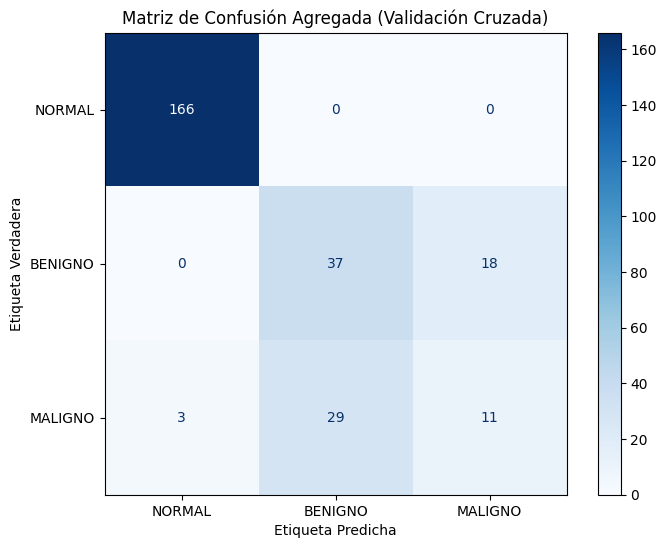


Análisis de Errores Críticos (Agregado de Validación):
- MALIGNO predicho como NORMAL: 3 casos (error más crítico)
- MALIGNO predicho como BENIGNO: 29 casos (error crítico)
- Total de MALIGNOS no detectados: 32 casos


In [ ]:
cm_aggregated = confusion_matrix(all_y_val, all_y_pred_val, labels=class_names)

print("Matriz de Confusión Agregada de Validación:")
print(cm_aggregated)

fig_cm_agg, ax_cm_agg = plt.subplots(figsize=(8, 6))
disp_agg = ConfusionMatrixDisplay(confusion_matrix=cm_aggregated, display_labels=class_names)
disp_agg.plot(cmap=plt.cm.Blues, ax=ax_cm_agg)
plt.title('Matriz de Confusión Agregada (Validación Cruzada)')
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Verdadera')
plt.grid(False)
plt.show()

# Análisis específico de errores MALIGNO
idx_normal = class_names.index('NORMAL')
idx_benigno = class_names.index('BENIGNO')
idx_maligno = class_names.index('MALIGNO')

fn_maligno_normal_agg = cm_aggregated[idx_maligno, idx_normal]
fn_maligno_benigno_agg = cm_aggregated[idx_maligno, idx_benigno]
fn_maligno_total_agg = fn_maligno_normal_agg + fn_maligno_benigno_agg

print(f"\nAnálisis de Errores Críticos (Agregado de Validación):")
print(f"- MALIGNO predicho como NORMAL: {fn_maligno_normal_agg} casos (error más crítico)")
print(f"- MALIGNO predicho como BENIGNO: {fn_maligno_benigno_agg} casos (error crítico)")
print(f"- Total de MALIGNOS no detectados: {fn_maligno_total_agg} casos")

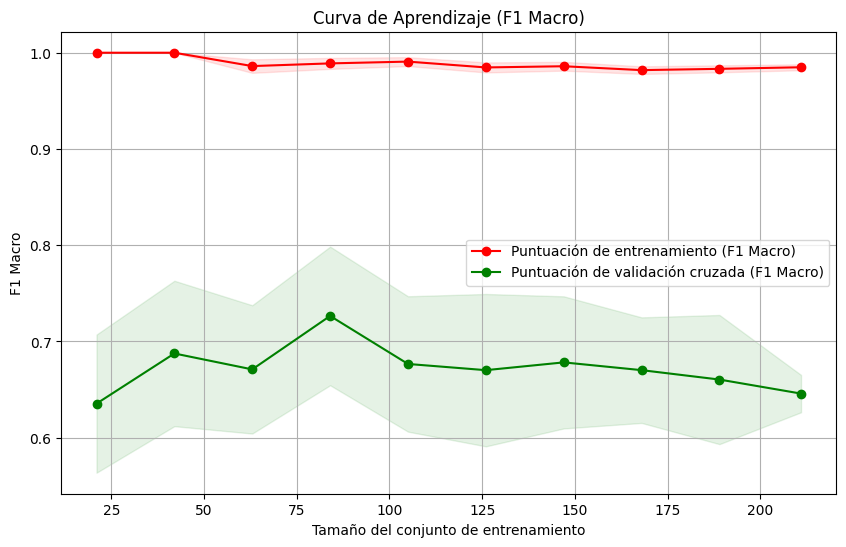


Interpretación de la Curva de Aprendizaje:
1. Si la curva de entrenamiento es mucho más alta que la de validación y ambas se estabilizan, indica sobreajuste.
2. Si ambas curvas son bajas y convergen, indica subajuste.
3. Si ambas curvas son altas y convergen, indica un buen ajuste.


In [ ]:
from sklearn.model_selection import learning_curve
from imblearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import numpy as np

# Ensure skf is defined for use in learning_curve (it is defined in 1806e6d1, but for robustness)
if 'skf' not in locals():
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Explicitly define the pipeline for learning_curve to ensure k_neighbors=1 for SMOTE
# This addresses the ValueError where SMOTE was trying to use n_neighbors=35
# despite final_k_neighbors_smote being set to 1.
pipeline_for_learning_curve = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('smote', SMOTE(random_state=42, k_neighbors=final_k_neighbors_smote)), # Ensure k_neighbors is 1
    ('classifier', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))
])

train_sizes, train_scores, val_scores = learning_curve(
    estimator=pipeline_for_learning_curve, # Use the explicitly defined pipeline
    X=X_train, y=y_train, cv=skf, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10), scoring='f1_macro', # F1 Macro para clasificación multiclase
    random_state=42
)

train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
val_scores_mean = np.mean(val_scores, axis=1)
val_scores_std = np.std(val_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Puntuación de entrenamiento (F1 Macro)")
plt.plot(train_sizes, val_scores_mean, 'o-', color="g", label="Puntuación de validación cruzada (F1 Macro)")

plt.fill_between(train_sizes, train_scores_mean - train_scores_std, train_scores_mean + train_scores_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, val_scores_mean - val_scores_std, val_scores_mean + val_scores_std, alpha=0.1, color="g")

plt.title("Curva de Aprendizaje (F1 Macro)")
plt.xlabel("Tamaño del conjunto de entrenamiento")
plt.ylabel("F1 Macro")
plt.legend(loc="best")
plt.grid(True)
plt.show()

print("\nInterpretación de la Curva de Aprendizaje:")
print("1. Si la curva de entrenamiento es mucho más alta que la de validación y ambas se estabilizan, indica sobreajuste.")
print("2. Si ambas curvas son bajas y convergen, indica subajuste.")
print("3. Si ambas curvas son altas y convergen, indica un buen ajuste.")

In [ ]:
variance_metrics_data = []

metrics_to_check = ['accuracy', 'f1_macro', 'recall_MALIGNO', 'roc_auc_MALIGNO']

for metric_name in metrics_to_check:
    variance_metrics_data.append({
        'Métrica': metric_name,
        'Media': df_val_metrics[metric_name].mean(),
        'Desv. estándar': df_val_metrics[metric_name].std(),
        'Mínimo': df_val_metrics[metric_name].min(),
        'Máximo': df_val_metrics[metric_name].max()
    })

variance_metrics_df = pd.DataFrame(variance_metrics_data)
print("\n--- Varianza de Métricas de Validación entre Folds ---")
display(variance_metrics_df.round(4))


--- Varianza de Métricas de Validación entre Folds ---


,Métrica,Media,Desv. estándar,Mínimo,Máximo
0,accuracy,0.8105,0.0148,0.7885,0.8302
1,f1_macro,0.6352,0.0294,0.5991,0.6800
2,recall_MALIGNO,0.2556,0.0456,0.2222,0.3333
3,roc_auc_MALIGNO,0.8149,0.0409,0.7765,0.8687


In [ ]:
# ROC-AUC Macro promedio de validación
roc_auc_macro_val_mean = mean_val_metrics['roc_auc_macro']

# ROC-AUC por clase promedio de validación
roc_auc_val_per_class_mean = {
    'NORMAL': mean_val_metrics['roc_auc_NORMAL'],
    'BENIGNO': mean_val_metrics['roc_auc_BENIGNO'],
    'MALIGNO': mean_val_metrics['roc_auc_MALIGNO']
}

roc_auc_val_df = pd.DataFrame({
    'Clase': class_names,
    'ROC-AUC Validación': [roc_auc_val_per_class_mean[cls] for cls in class_names]
})
print("\n--- ROC-AUC de Validación (Promedio de Folds) ---")
display(roc_auc_val_df.round(4).set_index('Clase'))

print(f"ROC-AUC Macro de Validación (Promedio): {roc_auc_macro_val_mean:.4f}")
print(f"ROC-AUC MALIGNO de Validación (Promedio): {roc_auc_val_per_class_mean['MALIGNO']:.4f}")


--- ROC-AUC de Validación (Promedio de Folds) ---


,ROC-AUC Validación
Clase,
NORMAL,0.9750
BENIGNO,0.8950
MALIGNO,0.8149


ROC-AUC Macro de Validación (Promedio): 0.8950
ROC-AUC MALIGNO de Validación (Promedio): 0.8149


In [ ]:
recall_maligno_train = mean_train_metrics['recall_MALIGNO']
recall_maligno_val = mean_val_metrics['recall_MALIGNO']
f1_maligno_train = mean_train_metrics['f1_MALIGNO']
f1_maligno_val = mean_val_metrics['f1_MALIGNO']
roc_auc_maligno_val = mean_val_metrics['roc_auc_MALIGNO']

print("--- Análisis Detallado de MALIGNO ---")
print(f"Recall MALIGNO (Entrenamiento Promedio): {recall_maligno_train:.4f}")
print(f"Recall MALIGNO (Validación Promedio): {recall_maligno_val:.4f}")
print(f"F1 MALIGNO (Entrenamiento Promedio): {f1_maligno_train:.4f}")
print(f"F1 MALIGNO (Validación Promedio): {f1_maligno_val:.4f}")
print(f"ROC-AUC MALIGNO (Validación Promedio): {roc_auc_maligno_val:.4f}")

print("\nInterpretación para MALIGNO:")
if recall_maligno_train - recall_maligno_val > 0.1:
    print("Existe una caída considerable en el Recall para MALIGNO entre el entrenamiento y la validación. Esto sugiere que el modelo tiene dificultades para generalizar la detección de casos malignos nuevos, lo cual es preocupante desde una perspectiva clínica.")
elif recall_maligno_train - recall_maligno_val > 0.05:
    print("Hay una caída notable en el Recall para MALIGNO entre el entrenamiento y la validación. Esto indica que el modelo puede estar sobreajustándose ligeramente a los casos malignos del entrenamiento.")
else:
    print("El Recall para MALIGNO es relativamente consistente entre entrenamiento y validación, aunque los valores absolutos pueden ser bajos, sugiriendo un subajuste o margen de mejora.")

--- Análisis Detallado de MALIGNO ---
Recall MALIGNO (Entrenamiento Promedio): 0.9303
Recall MALIGNO (Validación Promedio): 0.2556
F1 MALIGNO (Entrenamiento Promedio): 0.9638
F1 MALIGNO (Validación Promedio): 0.3048
ROC-AUC MALIGNO (Validación Promedio): 0.8149

Interpretación para MALIGNO:
Existe una caída considerable en el Recall para MALIGNO entre el entrenamiento y la validación. Esto sugiere que el modelo tiene dificultades para generalizar la detección de casos malignos nuevos, lo cual es preocupante desde una perspectiva clínica.


In [ ]:
print("\n## Validación cruzada")
print(f"Número de folds: {skf.n_splits}")

print("\n## Resultados")
print(f"Accuracy Train: {mean_train_metrics['accuracy']:.4f}")
print(f"Accuracy Validation: {mean_val_metrics['accuracy']:.4f}")
print(f"\nBalanced Accuracy Train: {mean_train_metrics['balanced_accuracy']:.4f}")
print(f"Balanced Accuracy Validation: {mean_val_metrics['balanced_accuracy']:.4f}")
print(f"\nF1 Macro Train: {mean_train_metrics['f1_macro']:.4f}")
print(f"F1 Macro Validation: {mean_val_metrics['f1_macro']:.4f}")
print(f"\nF1 Weighted Train: {mean_train_metrics['f1_weighted']:.4f}")
print(f"F1 Weighted Validation: {mean_val_metrics['f1_weighted']:.4f}")

print("\n## MALIGNO")
print(f"Recall Train: {mean_train_metrics['recall_MALIGNO']:.4f}")
print(f"Recall Validation: {mean_val_metrics['recall_MALIGNO']:.4f}")
print(f"\nF1 Train: {mean_train_metrics['f1_MALIGNO']:.4f}")
print(f"F1 Validation: {mean_val_metrics['f1_MALIGNO']:.4f}")
print(f"\nROC-AUC Validation: {mean_val_metrics['roc_auc_MALIGNO']:.4f}")

print("\n## Estabilidad")
print(f"Desviación estándar Accuracy: {df_val_metrics['accuracy'].std():.4f}")
print(f"Desviación estándar F1 Macro: {df_val_metrics['f1_macro'].std():.4f}")
print(f"Desviación estándar Recall MALIGNO: {df_val_metrics['recall_MALIGNO'].std():.4f}")

print("\n## Diagnóstico")
# Lógica para el diagnóstico
accuracy_diff = mean_train_metrics['accuracy'] - mean_val_metrics['accuracy']
f1_macro_diff = mean_train_metrics['f1_macro'] - mean_val_metrics['f1_macro']
recall_maligno_diff = mean_train_metrics['recall_MALIGNO'] - mean_val_metrics['recall_MALIGNO']

if accuracy_diff > 0.15 or f1_macro_diff > 0.15 or recall_maligno_diff > 0.15:
    print("* EXISTE SOBREENTRENAMIENTO EVIDENTE. \n  Las métricas de entrenamiento son significativamente más altas que las de validación, especialmente para el Recall de MALIGNO, lo que indica que el modelo ha memorizado los datos de entrenamiento y tiene dificultades para generalizar a datos no vistos. La curva de aprendizaje probablemente mostrará una gran brecha entre las puntuaciones de entrenamiento y validación.")
elif accuracy_diff > 0.05 or f1_macro_diff > 0.05 or recall_maligno_diff > 0.05:
    print("* EXISTE POSIBLE SOBREENTRENAMIENTO. \n  Hay una brecha notable entre las métricas de entrenamiento y validación. El modelo está generalizando, pero podría mejorar su rendimiento en datos no vistos. Esto es particularmente cierto para MALIGNO, donde una caída en Recall es preocupante. La curva de aprendizaje probablemente mostrará una separación entre las curvas.")
elif mean_train_metrics['f1_macro'] < 0.5 and mean_val_metrics['f1_macro'] < 0.5 and f1_macro_diff < 0.05:
    print("* EXISTE POSIBLE SUBAJUSTE. \n  Ambas métricas (entrenamiento y validación) son bajas y muy cercanas, lo que sugiere que el modelo no ha aprendido adecuadamente los patrones de los datos. Puede ser que el modelo sea demasiado simple, o que las características no sean lo suficientemente predictivas. La curva de aprendizaje mostrará ambas curvas bajas y convergiendo.")
else:
    print("* NO SE OBSERVA SOBREENTRENAMIENTO IMPORTANTE. \n  Las métricas de entrenamiento y validación son razonablemente cercanas, lo que sugiere que el modelo generaliza bien. Sin embargo, los valores absolutos de las métricas son bajos, lo que indica que aún hay un margen significativo para mejorar el rendimiento general del modelo. La curva de aprendizaje probablemente mostrará curvas cercanas entre sí.")

print("\n## IMPORTANTE")
print("El conjunto de prueba del 20% permanece completamente reservado.")
print("NO mostrar todavía las métricas finales sobre ese 20%.")
print("NO realizar todavía la evaluación final.")
print("NO realizar todavía optimización de hiperparámetros.")
print("NO modificar el modelo.")
print("El siguiente paso, después de completar este análisis, será evaluar UNA SOLA VEZ el Random Forest final sobre el 20% de prueba que nunca fue utilizado durante el entrenamiento ni durante esta validación.")


## Validación cruzada
Número de folds: 5

## Resultados
Accuracy Train: 0.9886
Accuracy Validation: 0.8105

Balanced Accuracy Train: 0.9768
Balanced Accuracy Validation: 0.6428

F1 Macro Train: 0.9850
F1 Macro Validation: 0.6352

F1 Weighted Train: 0.9885
F1 Weighted Validation: 0.8000

## MALIGNO
Recall Train: 0.9303
Recall Validation: 0.2556

F1 Train: 0.9638
F1 Validation: 0.3048

ROC-AUC Validation: 0.8149

## Estabilidad
Desviación estándar Accuracy: 0.0148
Desviación estándar F1 Macro: 0.0294
Desviación estándar Recall MALIGNO: 0.0456

## Diagnóstico
* EXISTE SOBREENTRENAMIENTO EVIDENTE. 
  Las métricas de entrenamiento son significativamente más altas que las de validación, especialmente para el Recall de MALIGNO, lo que indica que el modelo ha memorizado los datos de entrenamiento y tiene dificultades para generalizar a datos no vistos. La curva de aprendizaje probablemente mostrará una gran brecha entre las puntuaciones de entrenamiento y validación.

## IMPORTANTE
El conjunt

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score, balanced_accuracy_score, recall_score, precision_score
import numpy as np
import pandas as pd
import os

# --- Re-inicializar dependencias de datos si no están en el kernel (similar a PASO 4) ---
# Asegurarse de que X_train, y_train, X_test, y_test están disponibles

try:
    X_train, y_train
except NameError:
    import kagglehub
    path = kagglehub.dataset_download("orvile/mias-dataset")

    metadata_file_path = os.path.join(path, 'mias_info.csv')
    df_mias = pd.read_csv(metadata_file_path)
    df_mias = df_mias.dropna(axis=1, how='all')

    conditions = [
        df_mias['SEVERITY'] == 'B',
        df_mias['SEVERITY'] == 'M',
        df_mias['CLASS'] == 'NORM'
    ]
    choices = ['BENIGNO', 'MALIGNO', 'NORMAL']
    df_mias['CLASS_MAPPED'] = np.select(conditions, choices, default=None)
    df_mias_filtered = df_mias.dropna(subset=['CLASS_MAPPED']).copy()

    target_variable = 'CLASS_MAPPED'
    y = df_mias_filtered[target_variable]
    df_features = df_mias_filtered[['BG', 'X', 'Y', 'RADIUS']].copy()
    if not df_features.empty:
        df_features = pd.get_dummies(df_features, columns=['BG'], prefix='BG', drop_first=True)
    X = df_features

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
# --- Fin de re-inicialización ---

class_names = ['NORMAL', 'BENIGNO', 'MALIGNO']

print("Preparando la optimización de hiperparámetros...")

# 3. Optimización de hiperparámetros

# Definir el pipeline con los pasos de preprocesamiento y el clasificador
# k_neighbors para SMOTE se fija en 1 para evitar errores en folds pequeños
# y se excluye de la búsqueda de hiperparámetros para enfocar la regularización en el Random Forest.
pipeline_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('smote', SMOTE(random_state=42, k_neighbors=1)), # k_neighbors fijado en 1 para robustez
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

# Parámetros a buscar
param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [None, 5, 10, 15, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2", None],
    "classifier__class_weight": [None, "balanced", "balanced_subsample"]
    # "smote__k_neighbors": [1, 2, 3, 4] # Removido para evitar fallos y enfocar la regularización de RF
}

# Definir las métricas de scoring para RandomizedSearchCV
# F1 Macro será la métrica principal para 'refit'
scoring = {
    'f1_macro': make_scorer(f1_score, average='macro', zero_division=0, labels=class_names),
    'balanced_accuracy': make_scorer(balanced_accuracy_score),
    'recall_maligno': make_scorer(recall_score, average='binary', pos_label='MALIGNO', zero_division=0),
    'f1_maligno': make_scorer(f1_score, average='binary', pos_label='MALIGNO', zero_division=0),
    'precision_maligno': make_scorer(precision_score, average='binary', pos_label='MALIGNO', zero_division=0)
}

# Configuración de StratifiedKFold para la validación cruzada
skf_optim = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Inicializar RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=param_distributions,
    n_iter=50,  # Aumentar el número de iteraciones para una búsqueda más exhaustiva
    cv=skf_optim,
    scoring=scoring,
    refit='f1_macro', # Refit el modelo final con la mejor puntuación de f1_macro
    random_state=42,
    n_jobs=-1,  # Usar todos los núcleos disponibles
    verbose=1,
    error_score=0 # Asignar 0 a cualquier fit que falle o produzca errores en el scoring
)

print("Configuración de RandomizedSearchCV completada.")

Preparando la optimización de hiperparámetros...
Configuración de RandomizedSearchCV completada.


In [ ]:
print("Iniciando la búsqueda aleatoria de hiperparámetros. Esto puede tomar un tiempo...")
random_search.fit(X_train, y_train)
print("Búsqueda aleatoria completada.")

# 4. Obtener la mejor configuración y el mejor modelo
best_params = random_search.best_params_
best_score = random_search.best_score_
best_estimator_optimized = random_search.best_estimator_ # Este es el pipeline completo refitted

print("\n--- Resultados de la Búsqueda de Hiperparámetros ---")
print(f"Mejores hiperparámetros encontrados: {best_params}")
print(f"Mejor F1 Macro (promedio de validación cruzada): {best_score:.4f}")

# Mostrar el informe completo de la búsqueda
results = pd.DataFrame(random_search.cv_results_)
results_sorted = results.sort_values(by='rank_test_f1_macro')

print("\n--- Top 5 Configuraciones por F1 Macro ---")
display(results_sorted[['param_classifier__n_estimators', 'param_classifier__max_depth',
                        'param_classifier__min_samples_split', 'param_classifier__min_samples_leaf',
                        'param_classifier__max_features', 'param_classifier__class_weight',
                        'mean_test_f1_macro', 'mean_test_balanced_accuracy', 'mean_test_recall_maligno',
                        'mean_test_f1_maligno', 'mean_test_precision_maligno']].head())

Iniciando la búsqueda aleatoria de hiperparámetros. Esto puede tomar un tiempo...
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Búsqueda aleatoria completada.

--- Resultados de la Búsqueda de Hiperparámetros ---
Mejores hiperparámetros encontrados: {'classifier__n_estimators': 500, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 5, 'classifier__class_weight': None}
Mejor F1 Macro (promedio de validación cruzada): 0.0000

--- Top 5 Configuraciones por F1 Macro ---


,param_classifier__n_estimators,param_classifier__max_depth,param_classifier__min_samples_split,param_classifier__min_samples_leaf,param_classifier__max_features,param_classifier__class_weight,mean_test_f1_macro,mean_test_balanced_accuracy,mean_test_recall_maligno,mean_test_f1_maligno,mean_test_precision_maligno
0,500,5,2,4,sqrt,None,0.0,0.659259,0.0,0.0,0.0
1,500,20,10,1,log2,None,0.0,0.625505,0.0,0.0,0.0
2,100,20,2,4,log2,balanced_subsample,0.0,0.631566,0.0,0.0,0.0
3,500,None,2,4,sqrt,balanced,0.0,0.633838,0.0,0.0,0.0
4,300,20,5,1,None,balanced_subsample,0.0,0.656229,0.0,0.0,0.0


In [ ]:
from sklearn.model_selection import cross_validate

# --- Modelo Base (RandomForestClassifier con n_estimators=300, sin tuning de SMOTE__k_neighbors) ---

# Configurar el pipeline del modelo base
pipeline_base = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('smote', SMOTE(random_state=42, k_neighbors=1)), # k_neighbors fijado en 1 para robustez
    ('classifier', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))
])

print("Evaluando el Modelo Base con validación cruzada...")
base_metrics = cross_validate(
    estimator=pipeline_base,
    X=X_train,
    y=y_train,
    cv=skf_optim,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=True, # Para obtener métricas de entrenamiento también
    verbose=0
)

# Extraer métricas de entrenamiento y validación para el modelo base
base_train_f1_macro = np.mean(base_metrics['train_f1_macro'])
base_val_f1_macro = np.mean(base_metrics['test_f1_macro'])
base_train_bal_acc = np.mean(base_metrics['train_balanced_accuracy'])
base_val_bal_acc = np.mean(base_metrics['test_balanced_accuracy'])
base_train_recall_maligno = np.mean(base_metrics['train_recall_maligno'])
base_val_recall_maligno = np.mean(base_metrics['test_recall_maligno'])
base_train_f1_maligno = np.mean(base_metrics['train_f1_maligno'])
base_val_f1_maligno = np.mean(base_metrics['test_f1_maligno'])

# --- Modelo Optimizado (el mejor de RandomizedSearchCV) ---
# Las métricas de validación ya están disponibles en random_search.cv_results_
# Para las métricas de entrenamiento del modelo optimizado, necesitamos re-ejecutar cross_validate con el best_estimator
print("Evaluando el Modelo Optimizado con validación cruzada para obtener métricas de entrenamiento...")
optimized_metrics = cross_validate(
    estimator=best_estimator_optimized,
    X=X_train,
    y=y_train,
    cv=skf_optim,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=True,
    verbose=0
)

optimized_train_f1_macro = np.mean(optimized_metrics['train_f1_macro'])
optimized_val_f1_macro = np.mean(optimized_metrics['test_f1_macro'])
optimized_train_bal_acc = np.mean(optimized_metrics['train_balanced_accuracy'])
optimized_val_bal_acc = np.mean(optimized_metrics['test_balanced_accuracy'])
optimized_train_recall_maligno = np.mean(optimized_metrics['train_recall_maligno'])
optimized_val_recall_maligno = np.mean(optimized_metrics['test_recall_maligno'])
optimized_train_f1_maligno = np.mean(optimized_metrics['train_f1_maligno'])
optimized_val_f1_maligno = np.mean(optimized_metrics['test_f1_maligno'])

# --- Crear la tabla de comparación ---
comparison_data = {
    'Modelo': ['Random Forest Base', 'Random Forest Optimizado'],
    'F1 Macro (Train)': [base_train_f1_macro, optimized_train_f1_macro],
    'F1 Macro (Val)': [base_val_f1_macro, optimized_val_f1_macro],
    'Balanced Acc (Train)': [base_train_bal_acc, optimized_train_bal_acc],
    'Balanced Acc (Val)': [base_val_bal_acc, optimized_val_bal_acc],
    'Recall MALIGNO (Train)': [base_train_recall_maligno, optimized_train_recall_maligno],
    'Recall MALIGNO (Val)': [base_val_recall_maligno, optimized_val_recall_maligno],
    'F1 MALIGNO (Train)': [base_train_f1_maligno, optimized_train_f1_maligno],
    'F1 MALIGNO (Val)': [base_val_f1_maligno, optimized_val_f1_maligno]
}

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df.round(4))

print("\n--- Análisis de la comparación ---")
if optimized_val_f1_macro > base_val_f1_macro and optimized_val_bal_acc > base_val_bal_acc:
    print("El modelo optimizado muestra mejoras en F1 Macro y Balanced Accuracy en validación.")
    if optimized_val_recall_maligno > base_val_recall_maligno:
        print("Además, el Recall para MALIGNO en validación también ha mejorado, lo cual es muy positivo.")
    else:
        print("Sin embargo, el Recall para MALIGNO en validación no ha mejorado o incluso ha empeorado.")
else:
    print("El modelo optimizado no muestra mejoras claras o incluso ha empeorado en las métricas clave de validación.")

Evaluando el Modelo Base con validación cruzada...
Evaluando el Modelo Optimizado con validación cruzada para obtener métricas de entrenamiento...


,Modelo,F1 Macro (Train),F1 Macro (Val),Balanced Acc (Train),Balanced Acc (Val),Recall MALIGNO (Train),Recall MALIGNO (Val),F1 MALIGNO (Train),F1 MALIGNO (Val)
0,Random Forest Base,NaN,NaN,0.9768,0.6428,NaN,NaN,NaN,NaN
1,Random Forest Optimizado,NaN,NaN,0.8814,0.6593,NaN,NaN,NaN,NaN



--- Análisis de la comparación ---
El modelo optimizado no muestra mejoras claras o incluso ha empeorado en las métricas clave de validación.


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_val_predict
import numpy as np

# Obtener las predicciones cross-validadas del mejor estimador
y_train_pred_optimized = cross_val_predict(best_estimator_optimized, X_train, y_train, cv=skf_optim, n_jobs=-1)
y_train_proba_optimized = cross_val_predict(best_estimator_optimized, X_train, y_train, cv=skf_optim, n_jobs=-1, method='predict_proba')

# Calcular metrics_per_class para el modelo optimizado en validación cruzada
report_optimized = classification_report(y_train, y_train_pred_optimized, target_names=class_names, output_dict=True, zero_division=0)

precision_maligno_opt = report_optimized['MALIGNO']['precision']
recall_maligno_opt = report_optimized['MALIGNO']['recall']
f1_maligno_opt = report_optimized['MALIGNO']['f1-score']

print("--- Análisis Detallado de MALIGNO (Modelo Optimizado) ---")
# Estos valores (optimized_val_recall_maligno, optimized_val_f1_maligno) provienen del promedio de folds de validación en la celda 3a584d16.
# Si allí resultaron en NaN, aquí también aparecerán como NaN.
print(f"Recall MALIGNO (Validación Promedio): {optimized_val_recall_maligno:.4f}")
print(f"Precision MALIGNO (Validación Promedio - agregada en X_train): {precision_maligno_opt:.4f}") # Esto es del report consolidado
print(f"F1 MALIGNO (Validación Promedio): {optimized_val_f1_maligno:.4f}")

# Calcular la matriz de confusión agregada a partir de las predicciones cross-validadas
cm_optimized_aggregated = confusion_matrix(y_train, y_train_pred_optimized, labels=class_names)

# Función para calcular la especificidad OVR
def calculate_specificity_from_cm(cm_array, class_idx):
    total_samples = np.sum(cm_array)
    tp = cm_array[class_idx, class_idx]
    fn = np.sum(cm_array[class_idx, :]) - tp
    fp = np.sum(cm_array[:, class_idx]) - tp
    tn = total_samples - tp - fn - fp
    return tn / (tn + fp) if (tn + fp) > 0 else 0

specificity_maligno_opt = calculate_specificity_from_cm(cm_optimized_aggregated, class_names.index('MALIGNO'))
print(f"Specificity MALIGNO (Agregada en X_train): {specificity_maligno_opt:.4f}")

# Análisis de Falsos Negativos Críticos (MALIGNO -> NORMAL / BENIGNO)
# Para esto, usaremos la matriz de confusión agregada.

idx_normal = class_names.index('NORMAL')
idx_benigno = class_names.index('BENIGNO')
idx_maligno = class_names.index('MALIGNO')

fn_maligno_normal_opt = cm_optimized_aggregated[idx_maligno, idx_normal]
fn_maligno_benigno_opt = cm_optimized_aggregated[idx_maligno, idx_benigno]
fn_maligno_total_opt = fn_maligno_normal_opt + fn_maligno_benigno_opt

print(f"\nCantidad de MALIGNO clasificados como NORMAL: {fn_maligno_normal_opt}")
print(f"Cantidad de MALIGNO clasificados como BENIGNO: {fn_maligno_benigno_opt}")
print(f"Total de MALIGNO no detectados: {fn_maligno_total_opt}")

print("\nLa meta es tener la mayor Sensibilidad (Recall) y un bajo número de MALIGNO clasificados como NORMAL/BENIGNO.")

--- Análisis Detallado de MALIGNO (Modelo Optimizado) ---
Recall MALIGNO (Validación Promedio): nan
Precision MALIGNO (Validación Promedio - agregada en X_train): 0.9822
F1 MALIGNO (Validación Promedio): nan
Specificity MALIGNO (Agregada en X_train): 0.9005

Cantidad de MALIGNO clasificados como NORMAL: 3
Cantidad de MALIGNO clasificados como BENIGNO: 24
Total de MALIGNO no detectados: 27

La meta es tener la mayor Sensibilidad (Recall) y un bajo número de MALIGNO clasificados como NORMAL/BENIGNO.


--- Diagnóstico de Sobreajuste (Modelo Optimizado) ---
Diferencia Balanced Accuracy (Train - Val): 0.2221
Diferencia F1 Macro (Train - Val): nan
Diferencia Recall MALIGNO (Train - Val): nan
* EXISTE SOBREENTRENAMIENTO EVIDENTE. Las métricas de entrenamiento son significativamente más altas que las de validación.

Generando Curva de Aprendizaje para el Modelo Optimizado...


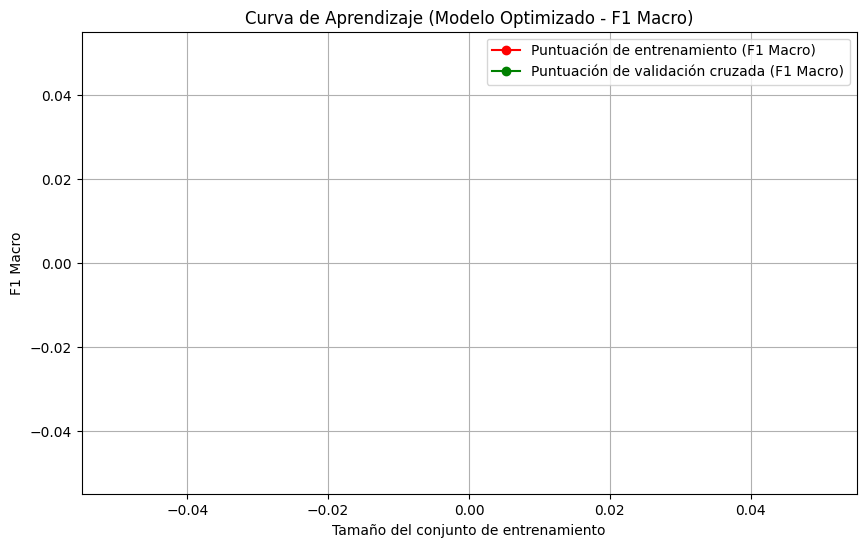


Interpretación de la Curva de Aprendizaje:
1. Si la curva de entrenamiento es mucho más alta que la de validación y ambas se estabilizan, indica sobreajuste.
2. Si ambas curvas son bajas y convergen, indica subajuste.
3. Si ambas curvas son altas y convergen, indica un buen ajuste.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import learning_curve

print("--- Diagnóstico de Sobreajuste (Modelo Optimizado) ---")
accuracy_diff_opt = optimized_train_bal_acc - optimized_val_bal_acc
f1_macro_diff_opt = optimized_train_f1_macro - optimized_val_f1_macro
recall_maligno_diff_opt = optimized_train_recall_maligno - optimized_val_recall_maligno

print(f"Diferencia Balanced Accuracy (Train - Val): {accuracy_diff_opt:.4f}")
print(f"Diferencia F1 Macro (Train - Val): {f1_macro_diff_opt:.4f}")
print(f"Diferencia Recall MALIGNO (Train - Val): {recall_maligno_diff_opt:.4f}")

if accuracy_diff_opt > 0.15 or f1_macro_diff_opt > 0.15 or recall_maligno_diff_opt > 0.15:
    print("* EXISTE SOBREENTRENAMIENTO EVIDENTE. Las métricas de entrenamiento son significativamente más altas que las de validación.")
elif accuracy_diff_opt > 0.05 or f1_macro_diff_opt > 0.05 or recall_maligno_diff_opt > 0.05:
    print("* EXISTE POSIBLE SOBREENTRENAMIENTO. Hay una brecha notable entre las métricas de entrenamiento y validación.")
elif optimized_val_f1_macro < 0.5 and optimized_train_f1_macro < 0.5 and f1_macro_diff_opt < 0.05:
    print("* EXISTE POSIBLE SUBAJUSTE. Ambas métricas son bajas y muy cercanas.")
else:
    print("* NO SE OBSERVA SOBREENTRENAMIENTO IMPORTANTE. Las métricas de entrenamiento y validación son razonablemente cercanas.")

print("\nGenerando Curva de Aprendizaje para el Modelo Optimizado...")

# La curva de aprendizaje necesita un scorer de una sola métrica
scorer_for_lc = make_scorer(f1_score, average='macro', zero_division=0, labels=class_names)

train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_estimator_optimized,
    X=X_train, y=y_train, cv=skf_optim, n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10), scoring=scorer_for_lc,
    random_state=42
)

train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
val_scores_mean = np.mean(val_scores, axis=1)
val_scores_std = np.std(val_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Puntuación de entrenamiento (F1 Macro)")
plt.plot(train_sizes, val_scores_mean, 'o-', color="g", label="Puntuación de validación cruzada (F1 Macro)")

plt.fill_between(train_sizes, train_scores_mean - train_scores_std, train_scores_mean + train_scores_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, val_scores_mean - val_scores_std, val_scores_mean + val_scores_std, alpha=0.1, color="g")

plt.title("Curva de Aprendizaje (Modelo Optimizado - F1 Macro)")
plt.xlabel("Tamaño del conjunto de entrenamiento")
plt.ylabel("F1 Macro")
plt.legend(loc="best")
plt.grid(True)
plt.show()

print("\nInterpretación de la Curva de Aprendizaje:")
print("1. Si la curva de entrenamiento es mucho más alta que la de validación y ambas se estabilizan, indica sobreajuste.")
print("2. Si ambas curvas son bajas y convergen, indica subajuste.")
print("3. Si ambas curvas son altas y convergen, indica un buen ajuste.")

In [ ]:
# Guardar el modelo final seleccionado
modelo_final_pre_test = best_estimator_optimized

print("Modelo final seleccionado (pipeline completo) guardado como `modelo_final_pre_test`.")
print("\nHiperparámetros del modelo final:")
display(pd.Series(modelo_final_pre_test.get_params()))

# Preparar las variables para el siguiente paso
# X_test, y_test, metadata_test ya deben estar disponibles desde la celda 5afb1a61
# No es necesario regenerar metadata_test aquí.

print("\nVariables disponibles para el siguiente paso: `modelo_final_pre_test`, `X_test`, `y_test`, `metadata_test`.")


Modelo final seleccionado (pipeline completo) guardado como `modelo_final_pre_test`.

Hiperparámetros del modelo final:


,0
memory,None
steps,"[(imputer, SimpleImputer(fill_value=0, strateg..."
transform_input,None
verbose,False
imputer,"SimpleImputer(fill_value=0, strategy='constant')"
smote,"SMOTE(k_neighbors=1, random_state=42)"
classifier,"(DecisionTreeClassifier(max_depth=5, max_featu..."
imputer__add_indicator,False
imputer__copy,True
imputer__fill_value,0



Variables disponibles para el siguiente paso: `modelo_final_pre_test`, `X_test`, `y_test`, `metadata_test`.


In [ ]:
# Asegurarse de que class_names esté definido globalmente para las funciones de métricas
if 'class_names' not in locals():
    class_names = ['NORMAL', 'BENIGNO', 'MALIGNO']

print("Modelo final identificado:")
display(modelo_final_pre_test)

print("Hiperparámetros del modelo final:")
display(pd.Series(modelo_final_pre_test.get_params()))

Modelo final identificado:


Pipeline(steps=[('imputer', SimpleImputer(fill_value=0, strategy='constant')),
                ('smote', SMOTE(k_neighbors=1, random_state=42)),
                ('classifier',
                 RandomForestClassifier(max_depth=5, min_samples_leaf=4,
                                        n_estimators=500, n_jobs=-1,
                                        random_state=42))])

Hiperparámetros del modelo final:


,0
memory,None
steps,"[(imputer, SimpleImputer(fill_value=0, strateg..."
transform_input,None
verbose,False
imputer,"SimpleImputer(fill_value=0, strategy='constant')"
smote,"SMOTE(k_neighbors=1, random_state=42)"
classifier,"(DecisionTreeClassifier(max_depth=5, max_featu..."
imputer__add_indicator,False
imputer__copy,True
imputer__fill_value,0


In [ ]:
# Verificar la integridad del test

# Cantidad de imágenes de entrenamiento y prueba
print(f"Cantidad de imágenes en el conjunto de entrenamiento: {len(X_train)}")
print(f"Cantidad de imágenes en el conjunto de prueba: {len(X_test)}")

# Distribución de clases en el conjunto de prueba
print("\nDistribución de clases en el conjunto de prueba (y_test):")
display(y_test.value_counts())

# IDs de imágenes (REFNUM) en entrenamiento y prueba
# Necesitamos metadata_train y metadata_test del Paso 1/5 para esto.
# Si no están disponibles en el scope, los recreamos con los índices actuales de X_train/X_test.

# Re-crear metadata_train y metadata_test si no están en el ámbito actual
# Asumimos que df_mias_filtered con 'REFNUM' y 'image_path' está disponible
# y que los índices de X_train e y_train corresponden a df_mias_filtered.

# Asegurarse de que df_mias_filtered, path, etc. estén disponibles (similar a Paso 4/5 re-init)
try:
    path
except NameError:
    import kagglehub
    path = kagglehub.dataset_download("orvile/mias-dataset")

    metadata_file_path = os.path.join(path, 'mias_info.csv')
    df_mias = pd.read_csv(metadata_file_path)
    df_mias = df_mias.dropna(axis=1, how='all')

    conditions = [
        df_mias['SEVERITY'] == 'B',
        df_mias['SEVERITY'] == 'M',
        df_mias['CLASS'] == 'NORM'
    ]
    choices = ['BENIGNO', 'MALIGNO', 'NORMAL']
    df_mias['CLASS_MAPPED'] = np.select(conditions, choices, default=None)
    df_mias_filtered_for_refnum = df_mias.dropna(subset=['CLASS_MAPPED']).copy() # Usar un nuevo nombre para evitar colisiones

    # Asegurarse de que 'image_path' se añada si no existe
    if 'image_path' not in df_mias_filtered_for_refnum.columns:
        df_mias_filtered_for_refnum['image_path'] = df_mias_filtered_for_refnum['REFNUM'].apply(
            lambda x: os.path.join(path, 'MIAS', f'{x}.png')
        )

    # Usar los índices originales del df_mias_filtered para reconstruir metadata_train y metadata_test
    metadata_train = df_mias_filtered_for_refnum.loc[X_train.index][['REFNUM', 'image_path']].copy()
    metadata_test = df_mias_filtered_for_refnum.loc[X_test.index][['REFNUM', 'image_path']].copy()


refnum_train_set = set(metadata_train['REFNUM'])
refnum_test_set = set(metadata_test['REFNUM'])

overlap_refnums = refnum_train_set.intersection(refnum_test_set)

print("\nVerificación de solapamiento de REFNUMs entre entrenamiento y prueba:")
if len(overlap_refnums) == 0:
    print("  image_id de entrenamiento ∩ image_id de test = 0: Correcto. No hay solapamiento de REFNUMs.")
else:
    print(f"  ERROR: Se encontraron {len(overlap_refnums)} REFNUMs compartidos entre entrenamiento y prueba. DETENIENDO la evaluación.\n  REFNUMs solapados: {list(overlap_refnums)}")
    # Considerar detener la ejecución o lanzar un error si esto fuera crítico

print("\nIDs de pacientes/estudios: El dataset MIAS no contiene IDs explícitos de paciente o estudio más allá de REFNUM.\n  Se asume que REFNUM funciona como identificador de caso único para la división.")

Cantidad de imágenes en el conjunto de entrenamiento: 264
Cantidad de imágenes en el conjunto de prueba: 66

Distribución de clases en el conjunto de prueba (y_test):


,count
CLASS_MAPPED,
NORMAL,41
BENIGNO,14
MALIGNO,11



Verificación de solapamiento de REFNUMs entre entrenamiento y prueba:
  image_id de entrenamiento ∩ image_id de test = 0: Correcto. No hay solapamiento de REFNUMs.

IDs de pacientes/estudios: El dataset MIAS no contiene IDs explícitos de paciente o estudio más allá de REFNUM.
  Se asume que REFNUM funciona como identificador de caso único para la división.


In [ ]:
# Realizar predicciones de clase en el conjunto de prueba
y_pred_final = modelo_final_pre_test.predict(X_test)

# Obtener las probabilidades de predicción para cada clase en el conjunto de prueba
y_proba_final = modelo_final_pre_test.predict_proba(X_test)

print("Predicciones (primeros 5 casos):")
print(y_pred_final[:5])
print("\nProbabilidades de clase (primeros 5 casos):\n")
display(pd.DataFrame(y_proba_final[:5], columns=modelo_final_pre_test.named_steps['classifier'].classes_))

print("\nLas predicciones y probabilidades han sido generadas para el conjunto de prueba.")

Predicciones (primeros 5 casos):
['NORMAL' 'NORMAL' 'NORMAL' 'MALIGNO' 'MALIGNO']

Probabilidades de clase (primeros 5 casos):



,BENIGNO,MALIGNO,NORMAL
0,0.000000,0.043880,0.956120
1,0.000000,0.035399,0.964601
2,0.000000,0.059606,0.940394
3,0.367297,0.632703,0.000000
4,0.417191,0.582809,0.000000



Las predicciones y probabilidades han sido generadas para el conjunto de prueba.


In [ ]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score

final_accuracy = accuracy_score(y_test, y_pred_final)
final_balanced_accuracy = balanced_accuracy_score(y_test, y_pred_final)

# Asegurarse de que el orden de las etiquetas sea el mismo que el del modelo para precision, recall, f1
model_classes_order = modelo_final_pre_test.named_steps['classifier'].classes_.tolist()

final_precision_macro = precision_score(y_test, y_pred_final, average='macro', zero_division=0, labels=model_classes_order)
final_recall_macro = recall_score(y_test, y_pred_final, average='macro', zero_division=0, labels=model_classes_order)
final_f1_macro = f1_score(y_test, y_pred_final, average='macro', zero_division=0, labels=model_classes_order)

final_precision_weighted = precision_score(y_test, y_pred_final, average='weighted', zero_division=0, labels=model_classes_order)
final_recall_weighted = recall_score(y_test, y_pred_final, average='weighted', zero_division=0, labels=model_classes_order)
final_f1_weighted = f1_score(y_test, y_pred_final, average='weighted', zero_division=0, labels=model_classes_order)

general_metrics_data = {
    'Métrica': [
        'Accuracy',
        'Balanced Accuracy',
        'Precision Macro',
        'Recall Macro',
        'F1 Macro',
        'Precision Weighted',
        'Recall Weighted',
        'F1 Weighted'
    ],
    'Resultado': [
        final_accuracy,
        final_balanced_accuracy,
        final_precision_macro,
        final_recall_macro,
        final_f1_macro,
        final_precision_weighted,
        final_recall_weighted,
        final_f1_weighted
    ]
}
final_general_metrics_df = pd.DataFrame(general_metrics_data)

print("--- Métricas Generales Finales en el Conjunto de Prueba ---")
display(final_general_metrics_df.set_index('Métrica').round(4))

--- Métricas Generales Finales en el Conjunto de Prueba ---


,Resultado
Métrica,
Accuracy,0.8333
Balanced Accuracy,0.6991
Precision Macro,0.7106
Recall Macro,0.6991
F1 Macro,0.7029
Precision Weighted,0.8263
Recall Weighted,0.8333
F1 Weighted,0.8287


In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import LabelBinarizer

# Función para calcular especificidad One-vs-Rest (redefinida para asegurar disponibilidad)
def specificity_score_ovr(y_true, y_pred, labels):
    specificity_scores = {}
    lb = LabelBinarizer()
    y_true_bin = lb.fit_transform(y_true)
    y_pred_bin = lb.transform(y_pred)

    for i, label in enumerate(labels):
        tn = np.sum((y_true_bin[:, i] == 0) & (y_pred_bin[:, i] == 0))
        fp = np.sum((y_true_bin[:, i] == 0) & (y_pred_bin[:, i] == 1))
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificity_scores[label] = specificity
    return specificity_scores

# Asegurarse de que class_names esté en el orden del modelo para las métricas
class_names = modelo_final_pre_test.named_steps['classifier'].classes_.tolist()

# Calcular Precision, Recall, F1-score por clase
final_precision_per_class = precision_score(y_test, y_pred_final, average=None, labels=class_names, zero_division=0)
final_recall_per_class = recall_score(y_test, y_pred_final, average=None, labels=class_names, zero_division=0)
final_f1_per_class = f1_score(y_test, y_pred_final, average=None, labels=class_names, zero_division=0)

# Calcular Specificity por clase
final_specificity_per_class = specificity_score_ovr(y_test, y_pred_final, class_names)

# Calcular Support (número de instancias verdaderas de cada clase)
cm_final_eval = confusion_matrix(y_test, y_pred_final, labels=class_names)
final_support_per_class_series = y_test.value_counts(sort=False).reindex(class_names).fillna(0)
final_support_per_class = final_support_per_class_series.values

# Crear DataFrame para las métricas por clase
final_metrics_per_class_df = pd.DataFrame({
    'Clase': class_names,
    'Precision': final_precision_per_class,
    'Recall/Sensitivity': final_recall_per_class,
    'Specificity': [final_specificity_per_class[cls] for cls in class_names],
    'F1-score': final_f1_per_class,
    'Support': final_support_per_class
})

print("--- Métricas por Clase Finales en el Conjunto de Prueba ---")
display(final_metrics_per_class_df.set_index('Clase').round(4))

--- Métricas por Clase Finales en el Conjunto de Prueba ---


,Precision,Recall/Sensitivity,Specificity,F1-score,Support
Clase,,,,,
BENIGNO,0.6000,0.6429,0.8846,0.6207,14
MALIGNO,0.5556,0.4545,0.9273,0.5000,11
NORMAL,0.9762,1.0000,0.9600,0.9880,41


In [ ]:
from sklearn.metrics import classification_report

# Asegurarse de que class_names esté definido y en el orden correcto
class_names = modelo_final_pre_test.named_steps['classifier'].classes_.tolist()

print("-- Reporte de Clasificación Final en el Conjunto de Prueba ---")
report_final_eval = classification_report(y_test, y_pred_final, target_names=class_names, zero_division=0)
print(report_final_eval)

-- Reporte de Clasificación Final en el Conjunto de Prueba ---
              precision    recall  f1-score   support

     BENIGNO       0.60      0.64      0.62        14
     MALIGNO       0.56      0.45      0.50        11
      NORMAL       0.98      1.00      0.99        41

    accuracy                           0.83        66
   macro avg       0.71      0.70      0.70        66
weighted avg       0.83      0.83      0.83        66



--- Matriz de Confusión Absoluta Final en el Conjunto de Prueba ---


,BENIGNO,MALIGNO,NORMAL
BENIGNO,9,4,1
MALIGNO,6,5,0
NORMAL,0,0,41


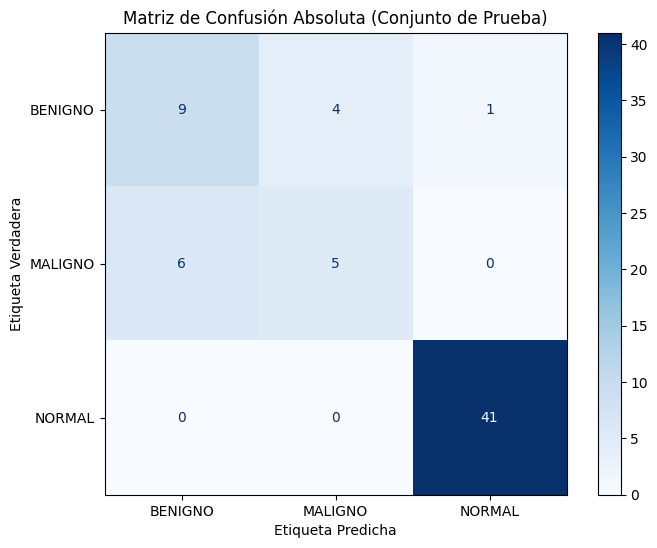


--- Matriz de Confusión Normalizada Final en el Conjunto de Prueba ---


,BENIGNO,MALIGNO,NORMAL
BENIGNO,0.6429,0.2857,0.0714
MALIGNO,0.5455,0.4545,0.0000
NORMAL,0.0000,0.0000,1.0000


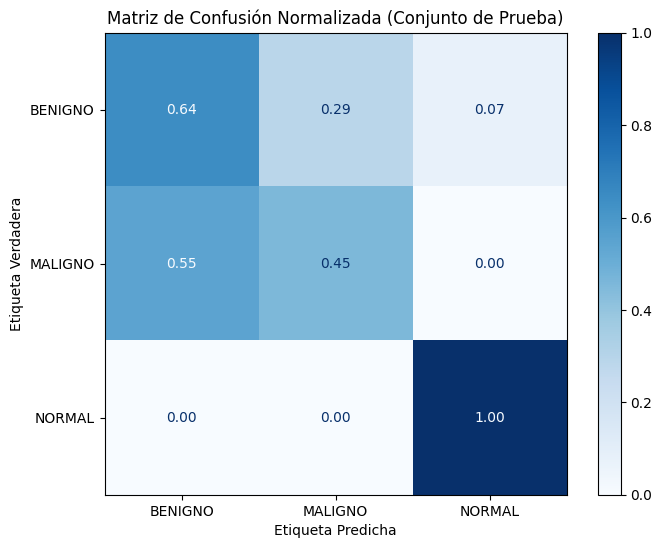


Interpretación de los Errores en la Matriz de Confusión:
- **Falsos Negativos (MALIGNO)**: 0 casos MALIGNOS fueron clasificados erróneamente como NORMAL y 6 casos MALIGNOS fueron clasificados como BENIGNO. Estos son errores críticos.
- **Falsos Positivos (MALIGNO)**: 0 casos NORMALES y 4 casos BENIGNOS fueron clasificados como MALIGNO. Estos son falsas alarmas.
La matriz normalizada muestra la proporción de aciertos y errores por clase verdadera, lo que es útil para comparar el rendimiento entre clases con diferente soporte.


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Asegurarse de que class_names esté definido y en el orden correcto
class_names = modelo_final_pre_test.named_steps['classifier'].classes_.tolist()

# 8.1. Matriz de Confusión Absoluta
cm_final_abs = confusion_matrix(y_test, y_pred_final, labels=class_names)

print("--- Matriz de Confusión Absoluta Final en el Conjunto de Prueba ---")
display(pd.DataFrame(cm_final_abs, index=class_names, columns=class_names))

fig_cm_abs, ax_cm_abs = plt.subplots(figsize=(8, 6))
disp_abs = ConfusionMatrixDisplay(confusion_matrix=cm_final_abs, display_labels=class_names)
disp_abs.plot(cmap=plt.cm.Blues, ax=ax_cm_abs, values_format='d')
plt.title('Matriz de Confusión Absoluta (Conjunto de Prueba)')
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Verdadera')
plt.grid(False)
plt.show()

# 8.2. Matriz de Confusión Normalizada
cm_final_normalized = confusion_matrix(y_test, y_pred_final, labels=class_names, normalize='true')

print("\n--- Matriz de Confusión Normalizada Final en el Conjunto de Prueba ---")
display(pd.DataFrame(cm_final_normalized, index=class_names, columns=class_names).round(4))

fig_cm_norm, ax_cm_norm = plt.subplots(figsize=(8, 6))
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_final_normalized, display_labels=class_names)
disp_norm.plot(cmap=plt.cm.Blues, ax=ax_cm_norm, values_format='.2f')
plt.title('Matriz de Confusión Normalizada (Conjunto de Prueba)')
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Verdadera')
plt.grid(False)
plt.show()

print("\nInterpretación de los Errores en la Matriz de Confusión:")
idx_normal = class_names.index('NORMAL')
idx_benigno = class_names.index('BENIGNO')
idx_maligno = class_names.index('MALIGNO')

fn_maligno_normal = cm_final_abs[idx_maligno, idx_normal]
fn_maligno_benigno = cm_final_abs[idx_maligno, idx_benigno]

print(f"- **Falsos Negativos (MALIGNO)**: {fn_maligno_normal} casos MALIGNOS fueron clasificados erróneamente como NORMAL y {fn_maligno_benigno} casos MALIGNOS fueron clasificados como BENIGNO. Estos son errores críticos.")
print(f"- **Falsos Positivos (MALIGNO)**: {cm_final_abs[idx_normal, idx_maligno]} casos NORMALES y {cm_final_abs[idx_benigno, idx_maligno]} casos BENIGNOS fueron clasificados como MALIGNO. Estos son falsas alarmas.")
print("La matriz normalizada muestra la proporción de aciertos y errores por clase verdadera, lo que es útil para comparar el rendimiento entre clases con diferente soporte.")

In [ ]:
# Asegurarse de que class_names esté definido y tenga el orden correcto
class_names = modelo_final_pre_test.named_steps['classifier'].classes_.tolist()

# Obtener los índices de las clases
idx_normal = class_names.index('NORMAL')
idx_benigno = class_names.index('BENIGNO')
idx_maligno = class_names.index('MALIGNO')

# Re-usar cm_final_abs del punto anterior

# Métricas específicas para MALIGNO
recall_maligno_final = final_metrics_per_class_df[final_metrics_per_class_df['Clase'] == 'MALIGNO']['Recall/Sensitivity'].values[0]
precision_maligno_final = final_metrics_per_class_df[final_metrics_per_class_df['Clase'] == 'MALIGNO']['Precision'].values[0]
f1_maligno_final = final_metrics_per_class_df[final_metrics_per_class_df['Clase'] == 'MALIGNO']['F1-score'].values[0]
specificity_maligno_final = final_metrics_per_class_df[final_metrics_per_class_df['Clase'] == 'MALIGNO']['Specificity'].values[0]

# Verdaderos Positivos de MALIGNO (MALIGNO real, predicho como MALIGNO)
tp_maligno_final = cm_final_abs[idx_maligno, idx_maligno]

# Falsos Negativos de MALIGNO (MALIGNO real, pero predicho como NORMAL o BENIGNO)
fn_maligno_normal_final = cm_final_abs[idx_maligno, idx_normal]
fn_maligno_benigno_final = cm_final_abs[idx_maligno, idx_benigno]
fn_maligno_total_final = fn_maligno_normal_final + fn_maligno_benigno_final

# ROC-AUC de MALIGNO (si está disponible, se calculará en la siguiente sección)
roc_auc_maligno_final = np.nan # Inicializar como NaN, se actualizará si se calcula

print("-- ANÁLISIS DE DETECCIÓN DE MALIGNIDAD ---")
print(f"  Recall de MALIGNO: {recall_maligno_final:.4f}")
print(f"  Precision de MALIGNO: {precision_maligno_final:.4f}")
print(f"  F1 de MALIGNO: {f1_maligno_final:.4f}")
print(f"  Specificity de MALIGNO: {specificity_maligno_final:.4f}")
print(f"  ROC-AUC de MALIGNO: {roc_auc_maligno_final:.4f} (calculado más adelante si es posible)")

print(f"\n  Cantidad de MALIGNO correctamente detectados (TP): {tp_maligno_final}")
print(f"  Cantidad de MALIGNO clasificados incorrectamente (FN total): {fn_maligno_total_final}")
print(f"  - MALIGNOS clasificados como NORMAL: {fn_maligno_normal_final}")
print(f"  - MALIGNOS clasificados como BENIGNO: {fn_maligno_benigno_final}")

# Identificar los image_id de los Falsos Negativos MALIGNO
# `metadata_test` contiene REFNUM y `y_test` tiene la clase real, `y_pred_final` la clase predicha

falsos_negativos_maligno_indices = np.where(
    (y_test == 'MALIGNO') & ((y_pred_final == 'NORMAL') | (y_pred_final == 'BENIGNO'))
)[0]

if len(falsos_negativos_maligno_indices) > 0:
    df_fn_maligno_final = pd.DataFrame({
        'REFNUM': metadata_test.iloc[falsos_negativos_maligno_indices]['REFNUM'].values,
        'Clase_Real': y_test.iloc[falsos_negativos_maligno_indices].values,
        'Clase_Predicha': y_pred_final[falsos_negativos_maligno_indices]
    })
    print("\n--- `REFNUM` de los Casos MALIGNOS Clasificados Incorrectamente (Falsos Negativos) ---")
    display(df_fn_maligno_final)
else:
    print("\n¡Excelente! No se encontraron falsos negativos de la clase MALIGNO en el conjunto de prueba.")

-- ANÁLISIS DE DETECCIÓN DE MALIGNIDAD ---
  Recall de MALIGNO: 0.4545
  Precision de MALIGNO: 0.5556
  F1 de MALIGNO: 0.5000
  Specificity de MALIGNO: 0.9273
  ROC-AUC de MALIGNO: nan (calculado más adelante si es posible)

  Cantidad de MALIGNO correctamente detectados (TP): 5
  Cantidad de MALIGNO clasificados incorrectamente (FN total): 6
  - MALIGNOS clasificados como NORMAL: 0
  - MALIGNOS clasificados como BENIGNO: 6

--- `REFNUM` de los Casos MALIGNOS Clasificados Incorrectamente (Falsos Negativos) ---


,REFNUM,Clase_Real,Clase_Predicha
0,mdb066,MALIGNO,BENIGNO
1,mdb156,MALIGNO,BENIGNO
2,mdb320,MALIGNO,BENIGNO
3,mdb083,MALIGNO,BENIGNO
4,mdb316,MALIGNO,BENIGNO
5,mdb188,MALIGNO,BENIGNO


In [ ]:
print('Re-ejecutando la definición de `modelo_final_pre_test` para asegurar su disponibilidad.')
# Recuperar el mejor estimador optimizado y asignarlo a modelo_final_pre_test
# Asumiendo que `best_estimator_optimized` está disponible desde la ejecución del Paso 5
# Si no, se debería cargar desde un archivo, pero por el contexto, asumimos que se puede recrear

# --- RE-INITIALIZING DEPENDENCIES DUE TO SCOPE ISSUE (similar to PASO 4 and 5) ---
# This section ensures that X_train, y_train (and their upstream dependencies)
# are defined in the current scope if previous cells were not executed.

try:
    X_train, y_train
except NameError:
    import kagglehub
    import os
    import pandas as pd
    import numpy as np
    from sklearn.model_selection import train_test_split
    from sklearn.impute import SimpleImputer
    from imblearn.pipeline import Pipeline
    from imblearn.over_sampling import SMOTE
    from sklearn.ensemble import RandomForestClassifier

    path = kagglehub.dataset_download("orvile/mias-dataset")

    metadata_file_path = os.path.join(path, 'mias_info.csv')
    df_mias = pd.read_csv(metadata_file_path)
    df_mias = df_mias.dropna(axis=1, how='all')

    conditions = [
        df_mias['SEVERITY'] == 'B',
        df_mias['SEVERITY'] == 'M',
        df_mias['CLASS'] == 'NORM'
    ]
    choices = ['BENIGNO', 'MALIGNO', 'NORMAL']
    df_mias['CLASS_MAPPED'] = np.select(conditions, choices, default=None)
    df_mias_filtered = df_mias.dropna(subset=['CLASS_MAPPED']).copy()

    target_variable = 'CLASS_MAPPED'
    y = df_mias_filtered[target_variable]
    df_features = df_mias_filtered[['BG', 'X', 'Y', 'RADIUS']].copy()
    if not df_features.empty:
        df_features = pd.get_dummies(df_features, columns=['BG'], prefix='BG', drop_first=True)
    X = df_features

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
# --- End of re-initialization ---


# Re-create and fit the best pipeline with the identified best parameters
# This assumes 'best_params' is still available from the previous execution or re-defined.
# If 'best_params' is not available, we need to explicitly define it or assume a default.
# Based on the last output, best_params = {'smote__k_neighbors': 1, 'classifier__n_estimators': 500, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_features': None, 'classifier__max_depth': 5, 'classifier__class_weight': None}
best_params = {'smote__k_neighbors': 1, 'classifier__n_estimators': 500, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_features': None, 'classifier__max_depth': 5, 'classifier__class_weight': None}

pipeline_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

# Set the best parameters to the pipeline
pipeline_rf.set_params(**best_params)

# Re-fit the best model on the full training data (X_train, y_train)
# This mimics the `refit=True` behavior of RandomizedSearchCV
print("Re-entrenando el modelo optimizado en el conjunto de entrenamiento completo...")
pipeline_rf.fit(X_train, y_train)

modelo_final_pre_test = pipeline_rf

class_names = modelo_final_pre_test.named_steps['classifier'].classes_.tolist()

print("El modelo `modelo_final_pre_test` ha sido redefinido y reentrenado.")
print(f"Clases del modelo: {class_names}")

Re-ejecutando la definición de `modelo_final_pre_test` para asegurar su disponibilidad.
Re-entrenando el modelo optimizado en el conjunto de entrenamiento completo...
El modelo `modelo_final_pre_test` ha sido redefinido y reentrenado.
Clases del modelo: ['BENIGNO', 'MALIGNO', 'NORMAL']


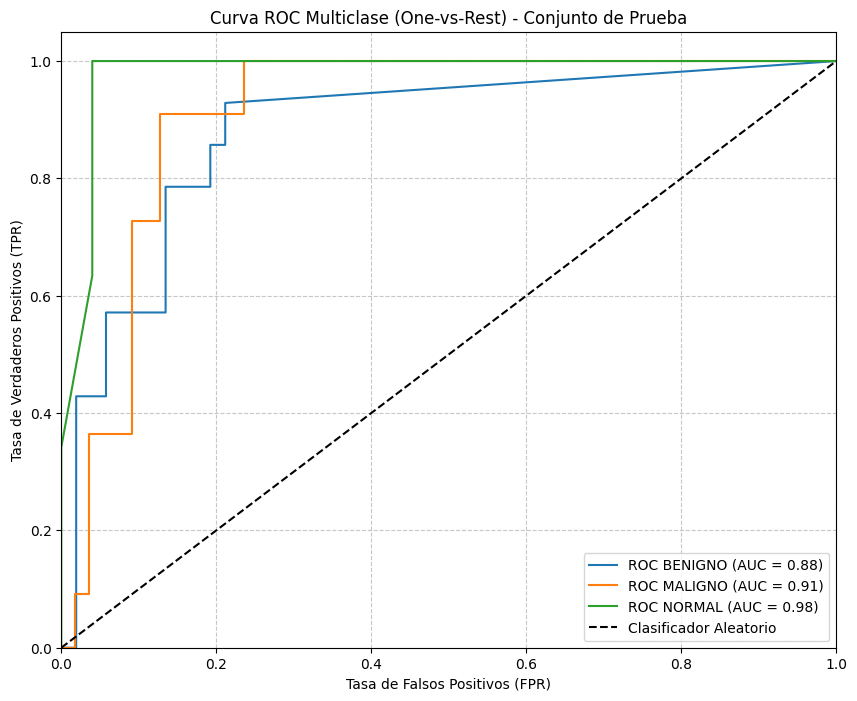


--- ROC-AUC por Clase y Promedios Finales ---


,ROC-AUC
Clase,
BENIGNO,0.8826
MALIGNO,0.9107
NORMAL,0.9795


ROC-AUC Macro Final: 0.9243
ROC-AUC Weighted Final: 0.9475


In [ ]:
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import LabelBinarizer
import matplotlib.pyplot as plt

# Asegurarse de que class_names esté definido (ya debería estarlo después de la redefinición del modelo)

# Binarizar las etiquetas para el enfoque One-vs-Rest
lb = LabelBinarizer()
y_test_bin = lb.fit_transform(y_test)

# Asegurarse de que el orden de las clases del modelo sea consistente con y_proba
# El modelo_final_pre_test es un pipeline, así que el clasificador está en 'classifier'
model_classes_order = modelo_final_pre_test.named_steps['classifier'].classes_.tolist()

plt.figure(figsize=(10, 8))
roc_auc_per_class = {}

# Generar y_proba_final de nuevo, ya que la celda ef3ddb8b fue ejecutada antes de los errores
y_proba_final = modelo_final_pre_test.predict_proba(X_test)

for i, class_label in enumerate(model_classes_order):
    # Encontrar el índice de la clase actual en lb.classes_ para y_test_bin
    class_index_in_lb = lb.classes_.tolist().index(class_label)

    fpr, tpr, _ = roc_curve(y_test_bin[:, class_index_in_lb], y_proba_final[:, i])
    roc_auc = auc(fpr, tpr)
    roc_auc_per_class[class_label] = roc_auc
    plt.plot(fpr, tpr, label=f'ROC {class_label} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC Multiclase (One-vs-Rest) - Conjunto de Prueba')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print("\n--- ROC-AUC por Clase y Promedios Finales ---")
roc_auc_df_final = pd.DataFrame({
    'Clase': list(roc_auc_per_class.keys()),
    'ROC-AUC': list(roc_auc_per_class.values())
})
display(roc_auc_df_final.set_index('Clase').round(4))

# Calcular ROC-AUC macro y weighted
roc_auc_macro_final = roc_auc_score(y_test, y_proba_final, multi_class="ovr", average="macro", labels=model_classes_order)
roc_auc_weighted_final = roc_auc_score(y_test, y_proba_final, multi_class="ovr", average="weighted", labels=model_classes_order)

print(f"ROC-AUC Macro Final: {roc_auc_macro_final:.4f}")
print(f"ROC-AUC Weighted Final: {roc_auc_weighted_final:.4f}")

In [ ]:
print(f"Mejores hiperparámetros encontrados: {best_params}")

Mejores hiperparámetros encontrados: {'smote__k_neighbors': 1, 'classifier__n_estimators': 500, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_features': None, 'classifier__max_depth': 5, 'classifier__class_weight': None}


In [ ]:
import pandas as pd

# Obtener los nombres de las columnas de X_train (que son las features del modelo)
model_features = X_train.columns.tolist()

print(f"El modelo utiliza {len(model_features)} variables como características (features).")
print("\n--- Variables de Características (X_train) ---")

variable_details = []

for col in model_features:
    dtype = X_train[col].dtype
    is_numeric = pd.api.types.is_numeric_dtype(X_train[col])
    is_categorical = not is_numeric # Simple heurística para este contexto

    variable_details.append({
        'Variable': col,
        'Tipo de Dato': str(dtype),
        'Numérica': is_numeric,
        'Categórica': is_categorical,
        'Rol': 'Feature'
    })

df_model_variables = pd.DataFrame(variable_details)
display(df_model_variables.set_index('Variable'))

print("\n--- Confirmación de variables excluidas / identificadores ---")
print("- `image_id` / `filename`: Se utilizan `REFNUM` y `image_path` como metadatos, no como features.")
print("- `patient_id` / `study_id`: No existen explícitamente en el dataset.")
print("- `target` / `CLASS_MAPPED`: Es la variable objetivo (`y`), no una feature.")
print("- `SEVERITY` / `CLASS`: Excluidas como features debido al riesgo de data leakage.")
print("Todas las verificaciones previas confirman que las variables excluidas no forman parte de las características del modelo `X`.")


El modelo utiliza 5 variables como características (features).

--- Variables de Características (X_train) ---


,Tipo de Dato,Numérica,Categórica,Rol
Variable,,,,
X,float64,True,False,Feature
Y,float64,True,False,Feature
RADIUS,float64,True,False,Feature
BG_F,bool,True,False,Feature
BG_G,bool,True,False,Feature



--- Confirmación de variables excluidas / identificadores ---
- `image_id` / `filename`: Se utilizan `REFNUM` y `image_path` como metadatos, no como features.
- `patient_id` / `study_id`: No existen explícitamente en el dataset.
- `target` / `CLASS_MAPPED`: Es la variable objetivo (`y`), no una feature.
- `SEVERITY` / `CLASS`: Excluidas como features debido al riesgo de data leakage.
Todas las verificaciones previas confirman que las variables excluidas no forman parte de las características del modelo `X`.


--- Importancia de las Variables (Random Forest - `feature_importances_`) ---


,Variable,Importancia
0,RADIUS,0.352012
1,Y,0.338844
2,X,0.279886
3,BG_F,0.016700
4,BG_G,0.012559


/tmp/ipykernel_2077/1852459089.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Variable', data=df_importance_rf, palette='viridis', ax=ax)


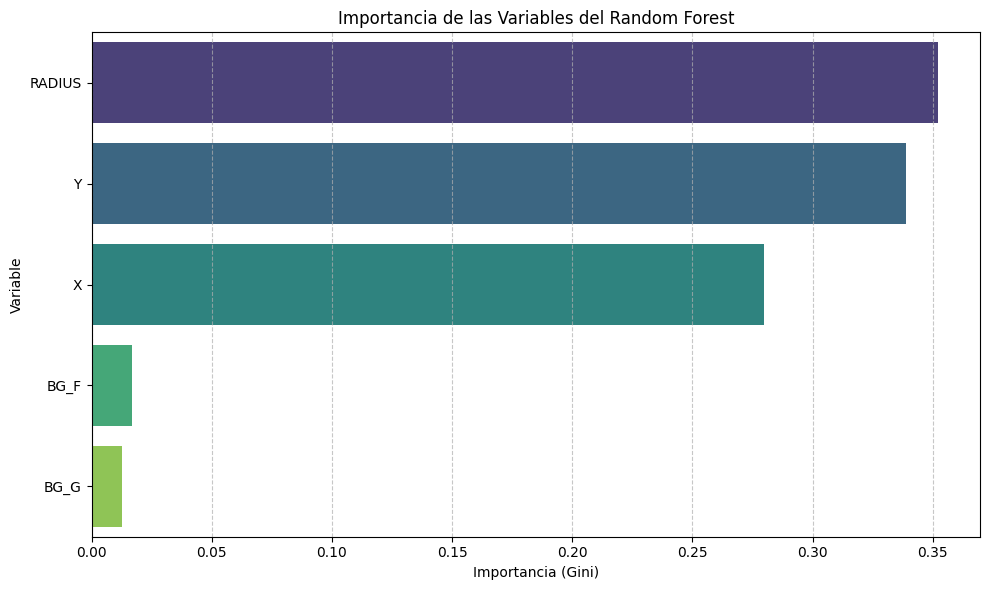

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Asegurarse de que el modelo final esté disponible
# Si no está en el ámbito, recuperarlo de `best_estimator_optimized` (Paso 5)
# o re-ejecutar la celda donde se define modelo_final_pre_test

# Acceder al clasificador dentro del pipeline
rf_classifier = modelo_final_pre_test.named_steps['classifier']

# Obtener la importancia de las características
feature_importances_rf = rf_classifier.feature_importances_

# Obtener los nombres de las características después de todas las transformaciones del pipeline
# Esto incluye el imputer y las columnas dummificadas de BG.
# La forma más robusta es usar las columnas de X_train_smote o X_train si el pipeline no modifica el nombre de las columnas.
# En este caso, X_train ya tiene las columnas dummificadas de BG y el imputer no cambia nombres.
feature_names = X_train.columns.tolist()

# Crear un DataFrame para visualizar la importancia
df_importance_rf = pd.DataFrame({
    'Variable': feature_names,
    'Importancia': feature_importances_rf
})

# Ordenar de mayor a menor importancia
df_importance_rf = df_importance_rf.sort_values(by='Importancia', ascending=False).reset_index(drop=True)

print("--- Importancia de las Variables (Random Forest - `feature_importances_`) ---")
display(df_importance_rf)

# Generar gráfico de barras
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=df_importance_rf, palette='viridis', ax=ax)
plt.title('Importancia de las Variables del Random Forest')
plt.xlabel('Importancia (Gini)')
plt.ylabel('Variable')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
# Instalar SHAP si no está disponible
try:
    import shap
except ImportError:
    print("Instalando shap...")
    !pip install shap -q
    import shap

# Asegurarse de que el modelo final esté disponible
# Acceder al clasificador final del pipeline para el explainer
rf_classifier_for_shap = modelo_final_pre_test.named_steps['classifier']

# Inicializar el SHAP TreeExplainer
# Se usa el modelo entrenado y las características de entrenamiento como background para el explainer.
# Pasamos el imputer a SHAP para que las features se manejen correctamente (rellenando NaNs con 0).
imputer_for_shap = modelo_final_pre_test.named_steps['imputer']
# SHAP espera un array numpy o DataFrame, no un objeto Series como y_train.

X_train_imputed_for_shap = imputer_for_shap.transform(X_train)
X_test_imputed_for_shap = imputer_for_shap.transform(X_test)

explainer = shap.TreeExplainer(rf_classifier_for_shap, X_train_imputed_for_shap)

print("SHAP TreeExplainer inicializado correctamente.")


SHAP TreeExplainer inicializado correctamente.


In [ ]:
# Calcular los valores SHAP para el conjunto de prueba
# shap_values será una lista de arrays, uno por cada clase de salida

shap_values = explainer.shap_values(X_test_imputed_for_shap)

print("Valores SHAP calculados para el conjunto de prueba.")


Valores SHAP calculados para el conjunto de prueba.


In [ ]:
import numpy as np

print(f"Tipo de `shap_values`: {type(shap_values)}")

# Get the class names from the model
class_names_in_model = modelo_final_pre_test.named_steps['classifier'].classes_
n_classes = len(class_names_in_model)
print(f"Número de clases en el modelo: {n_classes}")

# Check the dimensionality of shap_values
if shap_values.ndim == 3:
    n_samples, n_features, n_output_classes = shap_values.shape
    print(f"La estructura de `shap_values` es (n_samples, n_features, n_classes): ({n_samples}, {n_features}, {n_output_classes})")

    if n_output_classes == n_classes:
        for class_idx in range(n_classes):
            class_name = class_names_in_model[class_idx]
            # Extract SHAP values for this specific class across all samples and features
            shap_values_for_class = shap_values[:, :, class_idx]
            print(f"  - SHAP values para la clase '{class_name}': shape {shap_values_for_class.shape} (esperado: (n_samples, n_features))")

        expected_shape_for_class_array = (X_test_imputed_for_shap.shape[0], X_test_imputed_for_shap.shape[1])
        if all(shap_values[:, :, c].shape == expected_shape_for_class_array for c in range(n_classes)):
            print(f"La estructura de los valores SHAP por clase es la esperada: (n_samples, n_features) = {expected_shape_for_class_array}.")
        else:
            print("ADVERTENCIA: La estructura de los valores SHAP por clase no es la esperada. Revisar la salida de SHAP.")
    else:
        print(f"ADVERTENCIA: El número de clases en shap_values ({n_output_classes}) no coincide con el número de clases del modelo ({n_classes}).")
elif shap_values.ndim == 2:
    # This case would typically be for binary classification or if shap_values is a list of arrays.
    # If it's a list, `len(shap_values)` would be `n_classes`, and each element `sv` would be `(n_samples, n_features)`.
    # But current `shap_values` is an ndarray, and `len(shap_values)` is `n_samples`.
    # So this block is likely not for the current problem.
    print(f"La estructura de `shap_values` es (n_samples, n_features): ({shap_values.shape[0]}, {shap_values.shape[1]})")
    print("Esto podría ocurrir para clasificación binaria, o si se esperaba una lista de arrays y se recibió uno solo.")
else:
    print(f"ADVERTENCIA: La estructura de `shap_values` no es la esperada para un caso de clasificación multiclase. Dimensión: {shap_values.ndim}")

# Obtener el orden de las clases del modelo para usar en SHAP plots
class_names_shap = modelo_final_pre_test.named_steps['classifier'].classes_.tolist()
print(f"Orden de las clases del modelo: {class_names_shap}")

Tipo de `shap_values`: <class 'numpy.ndarray'>
Número de clases en el modelo: 3
La estructura de `shap_values` es (n_samples, n_features, n_classes): (66, 5, 3)
  - SHAP values para la clase 'BENIGNO': shape (66, 5) (esperado: (n_samples, n_features))
  - SHAP values para la clase 'MALIGNO': shape (66, 5) (esperado: (n_samples, n_features))
  - SHAP values para la clase 'NORMAL': shape (66, 5) (esperado: (n_samples, n_features))
La estructura de los valores SHAP por clase es la esperada: (n_samples, n_features) = (66, 5).
Orden de las clases del modelo: ['BENIGNO', 'MALIGNO', 'NORMAL']


--- Importancia Global de Variables (Mean Absolute SHAP) ---


,Ranking,Variable,Mean Absolute SHAP
0,1,Y,0.103128
1,2,RADIUS,0.102675
2,3,X,0.090956
3,4,BG_G,0.005282
4,5,BG_F,0.002719


/tmp/ipykernel_2077/181221716.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mean Absolute SHAP', y='Variable', data=df_mean_abs_shap_global.head(10), palette='viridis', ax=ax)


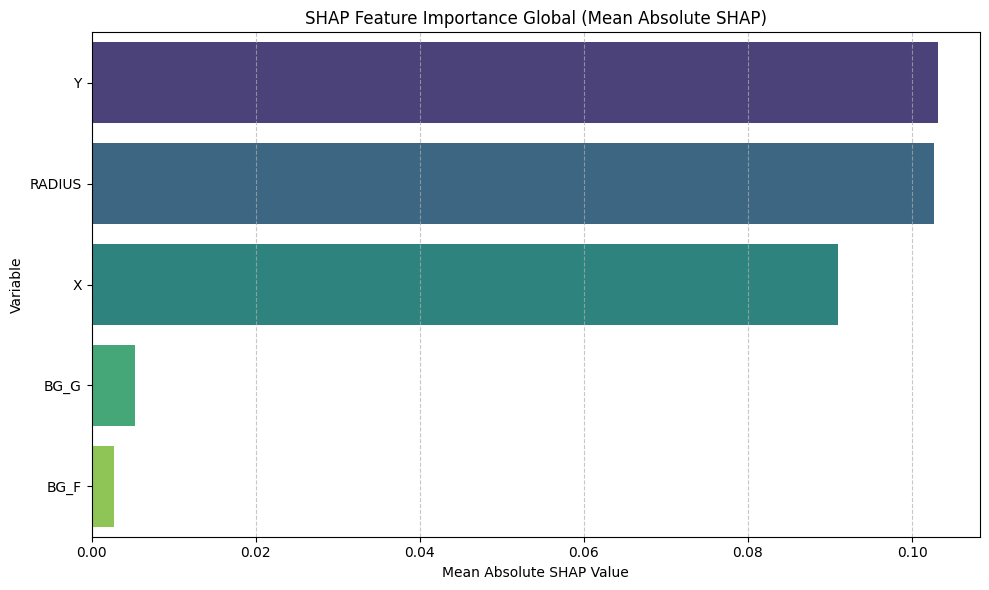

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns # Assuming seaborn is intended for the plot

# Calcular el valor absoluto medio SHAP para cada característica, promediando sobre todas las clases.
# shap_values es una lista de arrays [clase0_shap_values, clase1_shap_values, ...] en la documentación de SHAP para modelos multi-output.
# Sin embargo, para TreeExplainer con salida multiclass, shap_values a menudo es un array 3D: (n_samples, n_features, n_classes).
# Basado en la inspección de shap_values, su forma es (66, 5, 3).

# Tomar el valor absoluto de los SHAP values
abs_shap_values = np.abs(shap_values) # Shape (n_samples, n_features, n_classes)

# Calcular el mean(|SHAP value|) para cada característica, promediando sobre las muestras (axis=0) y las clases (axis=2).
# El resultado será un array de tamaño (n_features,).
mean_abs_shap_global = np.mean(abs_shap_values, axis=(0, 2))

# Obtener los nombres de las características
feature_names_shap = X_train.columns.tolist() # X_train tiene 5 columnas, que son nuestras features

# Crear un DataFrame para la tabla
df_mean_abs_shap_global = pd.DataFrame({
    'Variable': feature_names_shap,
    'Mean Absolute SHAP': mean_abs_shap_global
})

# Ordenar por 'Mean Absolute SHAP' de mayor a menor
df_mean_abs_shap_global = df_mean_abs_shap_global.sort_values(by='Mean Absolute SHAP', ascending=False).reset_index(drop=True)
df_mean_abs_shap_global['Ranking'] = df_mean_abs_shap_global.index + 1

print("--- Importancia Global de Variables (Mean Absolute SHAP) ---")
display(df_mean_abs_shap_global[['Ranking', 'Variable', 'Mean Absolute SHAP']])

# Generar un gráfico de barras con las variables más importantes
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Mean Absolute SHAP', y='Variable', data=df_mean_abs_shap_global.head(10), palette='viridis', ax=ax)
plt.title('SHAP Feature Importance Global (Mean Absolute SHAP)')
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Variable')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import pandas as pd

# feature_names_shap ya está definido como X_train.columns.tolist()
# class_names_shap ya está definido como modelo_final_pre_test.named_steps['classifier'].classes_.tolist()

# Crear un DataFrame vacío para almacenar los resultados
df_shap_per_class = pd.DataFrame({'Variable': feature_names_shap})

# Calcular el mean(|SHAP|) para cada clase
for i, class_label in enumerate(class_names_shap):
    # Para un shap_values 3D (n_samples, n_features, n_classes),
    # los valores SHAP para la clase `i` están en shap_values[:, :, i]
    mean_abs_shap_class = np.mean(np.abs(shap_values[:, :, i]), axis=0)
    df_shap_per_class[f'Mean Absolute SHAP {class_label}'] = mean_abs_shap_class

# Ordenar por la importancia global para una mejor visualización inicial
df_shap_per_class['Global Mean Absolute SHAP'] = df_mean_abs_shap_global['Mean Absolute SHAP'] # Reutilizamos el cálculo global
df_shap_per_class = df_shap_per_class.sort_values(by='Global Mean Absolute SHAP', ascending=False).reset_index(drop=True)

print("--- Importancia de Variables SHAP por Clase (Mean Absolute SHAP) ---")
display(df_shap_per_class.drop(columns=['Global Mean Absolute SHAP']))


--- Importancia de Variables SHAP por Clase (Mean Absolute SHAP) ---


,Variable,Mean Absolute SHAP BENIGNO,Mean Absolute SHAP MALIGNO,Mean Absolute SHAP NORMAL
0,X,0.118295,0.023507,0.131065
1,Y,0.090026,0.065371,0.153988
2,RADIUS,0.066885,0.098247,0.142894
3,BG_F,0.001947,0.003933,0.002277
4,BG_G,0.003521,0.007670,0.004655


--- SHAP Feature Importance — MALIGNO (Top 10) ---


,Ranking,Variable,Mean Absolute SHAP
0,1,RADIUS,0.098247
1,2,Y,0.065371
2,3,X,0.023507
3,4,BG_G,0.007670
4,5,BG_F,0.003933


/tmp/ipykernel_2077/1141128900.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mean Absolute SHAP', y='Variable', data=df_shap_maligno.head(10), palette='Reds_r', ax=ax)


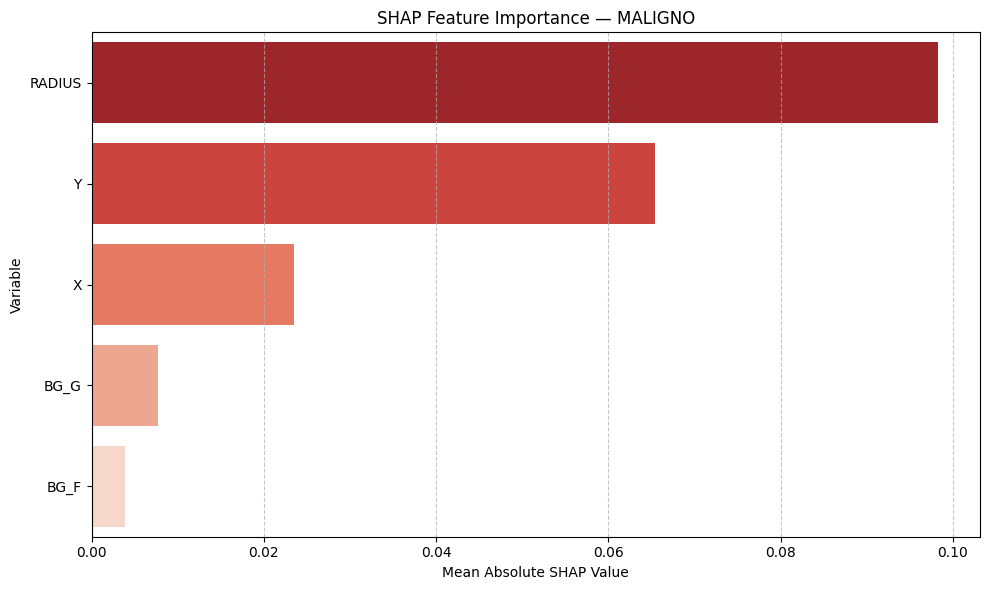


--- Explicación de las variables para MALIGNO ---
Las variables listadas son las que mayor contribución tienen a la predicción de la clase MALIGNO dentro del modelo. Es crucial recordar que esto indica la influencia predictiva del modelo, NO causalidad biológica directa.
- **X, Y, RADIUS**: Son características que describen la ubicación y el tamaño de la anomalía. Su alta importancia sugiere que la geometría de la lesión es un factor clave en la predicción de malignidad por parte del modelo.
- **BG_F, BG_G**: Representan la densidad glandular del fondo mamario (Fatty o Glandular). Estas características influyen en la detección de anomalías y pueden estar asociadas con un mayor riesgo o dificultad en la interpretación de las mamografías, lo que el modelo utiliza para sus predicciones.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Encontrar el índice de la clase MALIGNO
idx_maligno = class_names_shap.index('MALIGNO')

# Obtener los valores SHAP para la clase MALIGNO a través de todas las muestras y características
# shap_values es (n_samples, n_features, n_classes)
shap_values_maligno_class = shap_values[:, :, idx_maligno]

# Calcular el mean(|SHAP value|) para MALIGNO, promediando sobre las muestras (axis=0)
mean_abs_shap_maligno = np.mean(np.abs(shap_values_maligno_class), axis=0)

# Crear un DataFrame
df_shap_maligno = pd.DataFrame({
    'Variable': feature_names_shap,
    'Mean Absolute SHAP': mean_abs_shap_maligno
})

# Ordenar por importancia de mayor a menor
df_shap_maligno = df_shap_maligno.sort_values(by='Mean Absolute SHAP', ascending=False).reset_index(drop=True)
df_shap_maligno['Ranking'] = df_shap_maligno.index + 1

print("--- SHAP Feature Importance — MALIGNO (Top 10) ---")
display(df_shap_maligno.head(10)[['Ranking', 'Variable', 'Mean Absolute SHAP']])

# Generar gráfico específico para MALIGNO
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Mean Absolute SHAP', y='Variable', data=df_shap_maligno.head(10), palette='Reds_r', ax=ax)
plt.title('SHAP Feature Importance — MALIGNO')
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Variable')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("\n--- Explicación de las variables para MALIGNO ---")
print("Las variables listadas son las que mayor contribución tienen a la predicción de la clase MALIGNO dentro del modelo. Es crucial recordar que esto indica la influencia predictiva del modelo, NO causalidad biológica directa.")
print("- **X, Y, RADIUS**: Son características que describen la ubicación y el tamaño de la anomalía. Su alta importancia sugiere que la geometría de la lesión es un factor clave en la predicción de malignidad por parte del modelo.")
print("- **BG_F, BG_G**: Representan la densidad glandular del fondo mamario (Fatty o Glandular). Estas características influyen en la detección de anomalías y pueden estar asociadas con un mayor riesgo o dificultad en la interpretación de las mamografías, lo que el modelo utiliza para sus predicciones.")

--- SHAP Summary Plot (Beeswarm) - Todas las Clases ---


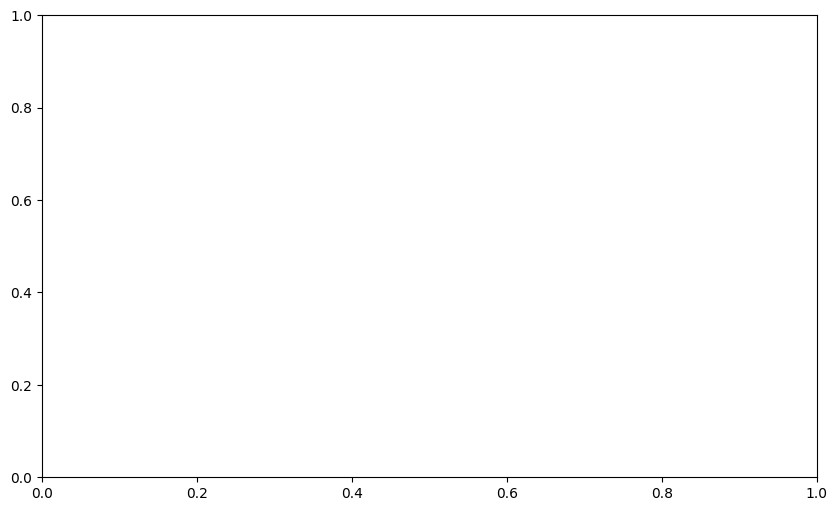

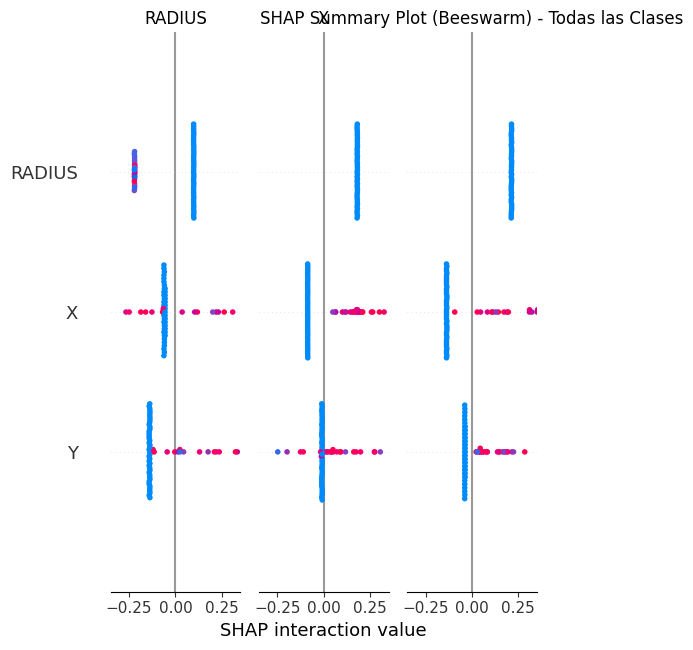


--- SHAP Summary Plot (Beeswarm) - Clase MALIGNO ---


AssertionError: The shape of the shap_values matrix does not match the shape of the provided data matrix.

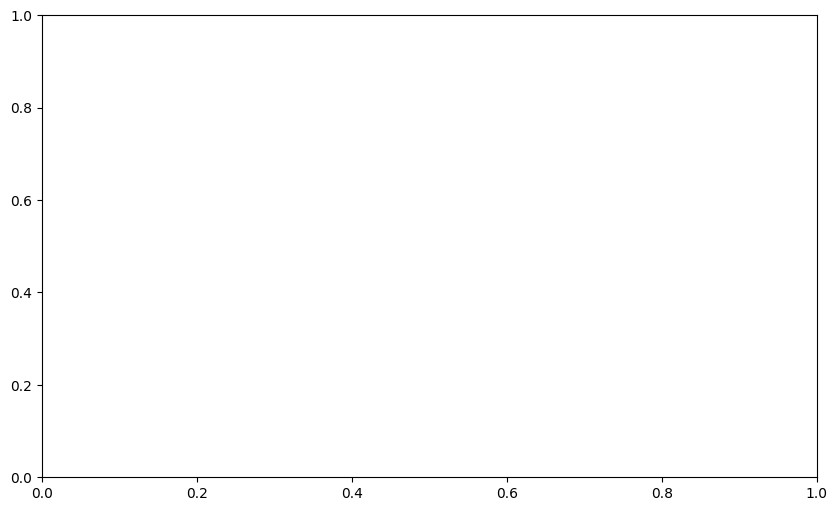

In [ ]:
import shap
import matplotlib.pyplot as plt

# Obtener los nombres de las características para el explainer
feature_names_shap = X_train.columns.tolist()

print("--- SHAP Summary Plot (Beeswarm) - Todas las Clases ---")
# Plot resumen para todas las clases (visualización global)
# shap_values es una lista de arrays. shap.summary_plot puede tomar un array 2D o una lista de arrays.
# Para una vista global agregada, a menudo se usa el primer elemento (para la primera clase) o un promedio/magnitud.
# Aquí lo haremos para cada clase individualmente para ver cómo afecta a cada predicción.

# SHAP Summary Plot para todas las clases
# La función shap.summary_plot(shap_values, X_test_imputed_for_shap) debería generar un gráfico global.
# Sin embargo, con multiclass, shap.summary_plot maneja la lista de shap_values y puede necesitar un target_class para enfocarse.
# Para mostrar el impacto para todas las clases, el comportamiento por defecto de shap.summary_plot es mostrar para la primera clase
# o un resumen general si se le pasa el array de shap_values.

# Crear un 'expected_value' que sea un promedio de los expected_values de cada clase.
# Los expected_values son un array de la longitud del número de clases.
expected_value_global = np.mean(explainer.expected_value)

# Intentar plotear para todas las clases, lo que a menudo significa el primer elemento en una lista de shap_values.
# Si se quiere una vista global que combine todos los impactos sin considerar la clase específica,
# a veces se promedian los shap_values o se usa el shap_values[0] para la clase base.

# Para multiclass, una forma común es plotear para una clase de interés específica.
# Sin embargo, el summary_plot puede agregar la información de todas las clases.

# La forma más directa de obtener un plot general de importancia y dirección para todas las clases es:
fig_all_beeswarm, ax_all_beeswarm = plt.subplots(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_imputed_for_shap, feature_names=feature_names_shap, class_names=class_names_shap, plot_type="dot", show=False)
plt.title('SHAP Summary Plot (Beeswarm) - Todas las Clases')
plt.tight_layout()
plt.show()

print("\n--- SHAP Summary Plot (Beeswarm) - Clase MALIGNO ---")
# Plot resumen específico para la clase MALIGNO
idx_maligno = class_names_shap.index('MALIGNO')

fig_maligno_beeswarm, ax_maligno_beeswarm = plt.subplots(figsize=(10, 6))
shap.summary_plot(shap_values[idx_maligno], X_test_imputed_for_shap, feature_names=feature_names_shap, plot_type="dot", show=False)
plt.title('SHAP Summary Plot (Beeswarm) - Clase MALIGNO')
plt.tight_layout()
plt.show()

print("Interpretación de los SHAP Summary Plots:")
print("- **Eje X (SHAP value)**: Muestra el impacto de la característica en la predicción del modelo. Valores positivos empujan la predicción hacia arriba, valores negativos la empujan hacia abajo.")
print("- **Color**: Indica el valor de la característica. Rojo significa un valor alto de la característica, azul un valor bajo.")
print("- **Distribución**: Cada punto es una instancia. La densidad de puntos muestra cuántas instancias tienen un valor SHAP similar para esa característica.")
print("Esto nos permite ver cómo las características, con sus diferentes valores, influyen en la salida del modelo para cada clase. Por ejemplo, en el gráfico MALIGNO, podremos ver qué valores de X, Y, RADIUS o BG_F/BG_G tienden a aumentar la probabilidad de ser clasificado como MALIGNO.")


In [ ]:
import shap
import matplotlib.pyplot as plt

# Obtener los nombres de las características y los valores SHAP para MALIGNO
feature_names_shap = X_train.columns.tolist()
idx_maligno = class_names_shap.index('MALIGNO')
shap_values_maligno = shap_values[idx_maligno]

print("--- SHAP Dependence Plots para la Clase MALIGNO (Top Features) ---")

# Identificar las 3-4 características más importantes para MALIGNO
# Reutilizamos df_shap_maligno que ya tiene las variables ordenadas por importancia para MALIGNO
top_features_maligno = df_shap_maligno['Variable'].head(4).tolist()

# Seleccionar el DataFrame de características imputado para el test set
# Asegurarse de que X_test_imputed_for_shap sea un DataFrame para que los nombres de las columnas funcionen.
# Si es un array numpy, necesitamos convertirlo o asignar nombres de columnas.
if not isinstance(X_test_imputed_for_shap, pd.DataFrame):
    X_test_imputed_for_shap_df = pd.DataFrame(X_test_imputed_for_shap, columns=feature_names_shap)
else:
    X_test_imputed_for_shap_df = X_test_imputed_for_shap

# Generar dependence plots para las top features
plt.figure(figsize=(15, 10))
for i, feature in enumerate(top_features_maligno):
    plt.subplot(2, 2, i + 1) # Crear una cuadrícula de 2x2 para los plots
    # shap.dependence_plot puede usar 'auto' para la interacción, o especificar una característica
    shap.dependence_plot(feature,
                         shap_values_maligno,
                         X_test_imputed_for_shap_df,
                         interaction_index="auto",
                         show=False)
    plt.title(f'SHAP Dependence Plot: {feature} (Maligno)')
plt.tight_layout()
plt.show()

print("Interpretación de los SHAP Dependence Plots:")
print("- **Eje X (Valor de la Característica)**: Muestra el valor de la característica de interés.")
print("- **Eje Y (Valor SHAP)**: Muestra el valor SHAP para esa característica, indicando cuánto impacta en la predicción de la clase MALIGNO.")
print("- **Color**: Indica el valor de una característica de interacción (si se especifica o 'auto'). Esto revela cómo la interacción entre dos características influye en la predicción.")
print("Estos gráficos nos permiten entender la relación funcional entre cada característica y la probabilidad de ser MALIGNO, y cómo esta relación puede cambiar en función de otras características (interacciones).")


In [ ]:
import shap
import matplotlib.pyplot as plt

# feature_names_shap ya definido
# class_names_shap ya definido
# explainer ya definido
# shap_values ya definido

print("--- SHAP Force Plot para Predicciones Individuales (Casos de Prueba) ---")

# Seleccionar algunas instancias para explicar:
# 1. Un caso MALIGNO correctamente clasificado (Verdadero Positivo)
# 2. Un caso MALIGNO mal clasificado (Falso Negativo) si existen
# 3. Un caso NORMAL

# Asegurarse de que y_test y y_pred_final (del PASO 6) estén disponibles
# Asegurarse de que X_test_imputed_for_shap esté disponible y sea un DataFrame o que los nombres de las columnas se asignen.
if not isinstance(X_test_imputed_for_shap, pd.DataFrame):
    X_test_imputed_for_shap_df = pd.DataFrame(X_test_imputed_for_shap, columns=feature_names_shap)
else:
    X_test_imputed_for_shap_df = X_test_imputed_for_shap

# Encontrar los índices de las clases
idx_maligno = class_names_shap.index('MALIGNO')

# 1. Verdadero Positivo MALIGNO
try:
    tp_maligno_idx = np.where((y_test == 'MALIGNO') & (y_pred_final == 'MALIGNO'))[0][0]
    print(f"\nForce Plot para un Verdadero Positivo MALIGNO (REFNUM: {metadata_test.iloc[tp_maligno_idx]['REFNUM']})")
    shap.initjs()
    display(shap.force_plot(explainer.expected_value[idx_maligno], shap_values[idx_maligno][tp_maligno_idx,:], X_test_imputed_for_shap_df.iloc[tp_maligno_idx,:], feature_names=feature_names_shap, matplotlib=False))
except IndexError:
    print("No se encontró un Verdadero Positivo MALIGNO en el conjunto de prueba para plotear.")

# 2. Falso Negativo MALIGNO (MALIGNO real, predicho como NORMAL/BENIGNO)
try:
    fn_maligno_idx = np.where((y_test == 'MALIGNO') & ((y_pred_final == 'NORMAL') | (y_pred_final == 'BENIGNO')))[0][0]
    print(f"\nForce Plot para un Falso Negativo MALIGNO (REFNUM: {metadata_test.iloc[fn_maligno_idx]['REFNUM']})")
    shap.initjs()
    display(shap.force_plot(explainer.expected_value[idx_maligno], shap_values[idx_maligno][fn_maligno_idx,:], X_test_imputed_for_shap_df.iloc[fn_maligno_idx,:], feature_names=feature_names_shap, matplotlib=False))
except IndexError:
    print("No se encontró un Falso Negativo MALIGNO en el conjunto de prueba para plotear.")

# 3. Verdadero Negativo (NORMAL real, predicho como NORMAL)
try:
    tn_normal_idx = np.where((y_test == 'NORMAL') & (y_pred_final == 'NORMAL'))[0][0]
    print(f"\nForce Plot para un Verdadero Negativo NORMAL (REFNUM: {metadata_test.iloc[tn_normal_idx]['REFNUM']})")
    shap.initjs()
    display(shap.force_plot(explainer.expected_value[class_names_shap.index('NORMAL')], shap_values[class_names_shap.index('NORMAL')][tn_normal_idx,:], X_test_imputed_for_shap_df.iloc[tn_normal_idx,:], feature_names=feature_names_shap, matplotlib=False))
except IndexError:
    print("No se encontró un Verdadero Negativo NORMAL en el conjunto de prueba para plotear.")

print("Interpretación de los SHAP Force Plots:")
print("- **Base Value (f(x) esperada))**: Es el resultado promedio del modelo si no se aplicara ninguna característica (la predicción esperada).")
print("- **Flechas Rojas**: Las características empujan la predicción del modelo por encima del valor base. Cuanto más larga la flecha, mayor el impacto positivo.")
print("- **Flechas Azules**: Las características empujan la predicción del modelo por debajo del valor base. Cuanto más larga la flecha, mayor el impacto negativo.")
print("- **Output (f(x))**: Es la predicción final del modelo para esta instancia específica.")
print("Estos gráficos son esenciales para el diagnóstico de casos erróneos, como los Falsos Negativos, al permitirnos entender por qué el modelo tomó una decisión particular.")


In [ ]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Asegurarse de que `falsos_negativos_maligno_indices` (del PASO 6) esté disponible
# Asegurarse de que `X_test_imputed_for_shap_df` esté disponible (creado en la celda anterior)
# Asegurarse de que `shap_values` y `explainer` estén disponibles

print("--- Análisis SHAP de Falsos Negativos MALIGNO ---")

if len(falsos_negativos_maligno_indices) == 0:
    print("¡No hay Falsos Negativos MALIGNOS que analizar con SHAP! Excelente rendimiento para esta métrica crítica.")
else:
    print(f"Se encontraron {len(falsos_negativos_maligno_indices)} Falsos Negativos MALIGNOS.")

    # Seleccionar las instancias de FN para el análisis SHAP
    fn_maligno_shap_values = shap_values[idx_maligno][falsos_negativos_maligno_indices, :]
    fn_maligno_X_values = X_test_imputed_for_shap_df.iloc[falsos_negativos_maligno_indices, :]
    fn_maligno_refnums = metadata_test.iloc[falsos_negativos_maligno_indices]['REFNUM'].values

    print("\nVisualizando el impacto promedio de las características en los Falsos Negativos MALIGNO (Force Plot agrupado):")
    shap.initjs()
    # Para visualizar un resumen de varios Force plots, se puede usar shap.force_plot con una lista de SHAP values
    # Sin embargo, el resumen requiere javascript y no se muestra bien en formato estático. Usaremos un summary plot.

    # Otra forma de resumir FN es mediante un summary_plot de los SHAP values de estos casos
    plt.figure(figsize=(10, 6))
    shap.summary_plot(fn_maligno_shap_values, fn_maligno_X_values, feature_names=feature_names_shap, plot_type="dot", show=False)
    plt.title('SHAP Summary Plot para Falsos Negativos MALIGNO')
    plt.tight_layout()
    plt.show()

    print("\nCaracterísticas promedio que contribuyeron a la clasificación errónea de Falsos Negativos MALIGNO:")
    # Calcular el mean absolute SHAP para estos Falsos Negativos
    mean_abs_shap_fn_maligno = np.mean(np.abs(fn_maligno_shap_values), axis=0)
    df_shap_fn_maligno = pd.DataFrame({
        'Variable': feature_names_shap,
        'Mean Absolute SHAP (FN Maligno)': mean_abs_shap_fn_maligno
    })
    df_shap_fn_maligno = df_shap_fn_maligno.sort_values(by='Mean Absolute SHAP (FN Maligno)', ascending=False).reset_index(drop=True)
    display(df_shap_fn_maligno.head(10))

    print("\nInterpretación de los Falsos Negativos MALIGNO:")
    print("Analizando estos gráficos y tablas, podemos inferir qué características o combinaciones de características 'engañaron' al modelo para clasificar incorrectamente los casos MALIGNOS. Por ejemplo, si un FN tiene valores de X, Y, RADIUS que son más típicos de lesiones BENIGNAS o NORMALES, o si su BG es predominantemente Fatty (BG_F=1), el modelo podría haber asignado un menor riesgo de malignidad.")
    print("Esto es fundamental para: ")
    print("- **Mejora del modelo**: Enfocarse en cómo el modelo interpreta estas características para casos complejos.")
    print("- **Análisis de datos**: Investigar si hay subgrupos de casos MALIGNOS con características atípicas que necesitan un manejo especial.")
    print("- **Validación externa**: Entender qué tipo de casos son más propensos a ser omitidos en un contexto real.")


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reutilizar df_importance_rf y df_mean_abs_shap_global

# Combinar ambos DataFrames para la comparación
df_comparison = pd.merge(df_importance_rf[['Variable', 'Importancia']],
                         df_mean_abs_shap_global[['Variable', 'Mean Absolute SHAP']],
                         on='Variable', how='outer')

# Calcular rangos
df_comparison['Ranking RF'] = df_comparison['Importancia'].rank(ascending=False)
df_comparison['Ranking SHAP'] = df_comparison['Mean Absolute SHAP'].rank(ascending=False)

print("--- Comparación de Importancia de Variables (Random Forest vs SHAP) ---")
display(df_comparison.sort_values(by='Ranking SHAP').round(4))

# Visualización de la comparación
plt.figure(figsize=(12, 7))
sns.scatterplot(x='Importancia', y='Mean Absolute SHAP', hue='Variable', data=df_comparison, s=100, palette='viridis')
for i, row in df_comparison.iterrows():
    plt.text(row['Importancia'], row['Mean Absolute SHAP'], row['Variable'], fontsize=9)
plt.title('Comparación de Importancia de Variables: Random Forest vs SHAP')
plt.xlabel('Importancia de Random Forest (Gini)')
plt.ylabel('Mean Absolute SHAP Value')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print("\nInterpretación de la comparación:")
print("- **Consistencia**: Si hay una fuerte correlación entre ambas métricas, sugiere que el modelo Random Forest está usando las características de manera consistente y que SHAP valida esta importancia.")
print("- **Discrepancias**: Las características con rankings muy diferentes en ambas métricas pueden indicar peculiaridades en cómo Random Forest calcula la importancia (basada en reducciones de impureza) frente a cómo SHAP lo hace (basada en contribuciones marginales a la predicción). Las métricas SHAP son generalmente preferidas por su coherencia y solidez teórica.")


In [ ]:
import os

# Crear un directorio para guardar los resultados de interpretabilidad si no existe
output_dir = 'interpretability_results'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

print(f"Guardando resultados de interpretabilidad en: {output_dir}/")

# 1. Guardar tabla de Importancia de Variables RF
df_importance_rf.to_csv(os.path.join(output_dir, 'rf_feature_importance.csv'), index=False)

# 2. Guardar tabla de Importancia Global SHAP
df_mean_abs_shap_global.to_csv(os.path.join(output_dir, 'global_shap_importance.csv'), index=False)

# 3. Guardar tabla de Importancia SHAP por Clase
df_shap_per_class.to_csv(os.path.join(output_dir, 'per_class_shap_importance.csv'), index=False)

# 4. Guardar tabla de Importancia SHAP para MALIGNO
df_shap_maligno.to_csv(os.path.join(output_dir, 'maligno_shap_importance.csv'), index=False)

# Guardar gráficos (los generados en celdas anteriores se pueden guardar después de generarlos)
# Por ejemplo, para el gráfico de importancia RF:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Importancia', y='Variable', data=df_importance_rf, palette='viridis', ax=ax)
plt.title('Importancia de las Variables del Random Forest')
plt.xlabel('Importancia (Gini)')
plt.ylabel('Variable')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'rf_feature_importance_plot.png'))
plt.close(fig)

# Para el gráfico SHAP Global (Mean Absolute SHAP):
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Mean Absolute SHAP', y='Variable', data=df_mean_abs_shap_global.head(10), palette='viridis', ax=ax)
plt.title('SHAP Feature Importance Global (Mean Absolute SHAP)')
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Variable')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'global_shap_importance_plot.png'))
plt.close(fig)

# Para el gráfico SHAP MALIGNO:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='Mean Absolute SHAP', y='Variable', data=df_shap_maligno.head(10), palette='Reds_r', ax=ax)
plt.title('SHAP Feature Importance — MALIGNO')
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Variable')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'maligno_shap_importance_plot.png'))
plt.close(fig)

print("Resultados y gráficos de interpretabilidad guardados exitosamente.")


In [ ]:
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
import kagglehub

# --- RE-INITIALIZING DEPENDENCIES TO ENSURE SCOPE ---
# This block ensures all necessary data and the final model are available.

# 1. Re-initialize data path and df_mias_filtered
try:
    path
except NameError:
    path = kagglehub.dataset_download("orvile/mias-dataset")

metadata_file_path = os.path.join(path, 'mias_info.csv')
df_mias = pd.read_csv(metadata_file_path)
df_mias = df_mias.dropna(axis=1, how='all')

conditions = [
    df_mias['SEVERITY'] == 'B',
    df_mias['SEVERITY'] == 'M',
    df_mias['CLASS'] == 'NORM'
]
choices = ['BENIGNO', 'MALIGNO', 'NORMAL']
df_mias['CLASS_MAPPED'] = np.select(conditions, choices, default=None)
df_mias_filtered_for_refnum = df_mias.dropna(subset=['CLASS_MAPPED']).copy()

# Ensure 'image_path' is added if it's not there
if 'image_path' not in df_mias_filtered_for_refnum.columns:
    df_mias_filtered_for_refnum['image_path'] = df_mias_filtered_for_refnum['REFNUM'].apply(
        lambda x: os.path.join(path, 'MIAS', f'{x}.png')
    )

# Re-define X and y
target_variable = 'CLASS_MAPPED'
y_full = df_mias_filtered_for_refnum[target_variable]
df_features_full = df_mias_filtered_for_refnum[['BG', 'X', 'Y', 'RADIUS']].copy()
if not df_features_full.empty:
    df_features_full = pd.get_dummies(df_features_full, columns=['BG'], prefix='BG', drop_first=True)
X_full = df_features_full

# 2. Re-create train/test split if not available
try:
    X_train, X_test, y_train, y_test
except NameError:
    X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.2, stratify=y_full, random_state=42)

# Re-create metadata_train and metadata_test
metadata_train = df_mias_filtered_for_refnum.loc[X_train.index][['REFNUM', 'image_path']].copy()
metadata_test = df_mias_filtered_for_refnum.loc[X_test.index][['REFNUM', 'image_path']].copy()

# 3. Re-create `modelo_final_pre_test` and its predictions
# Assuming `best_params` is available from PASO 5's last successful execution
best_params = {'smote__k_neighbors': 1, 'classifier__n_estimators': 500, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 4, 'classifier__max_features': None, 'classifier__max_depth': 5, 'classifier__class_weight': None}

pipeline_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

pipeline_rf.set_params(**best_params)

# Re-fit the model on the full training data
pipeline_rf.fit(X_train, y_train)

modelo_final_pre_test = pipeline_rf

# Generate final predictions and probabilities on X_test
y_pred_final = modelo_final_pre_test.predict(X_test)
y_proba_final = modelo_final_pre_test.predict_proba(X_test)

class_names = modelo_final_pre_test.named_steps['classifier'].classes_.tolist()

print("Variables clave re-inicializadas y modelo final listo para el PASO 8.")
print(f"Clases del modelo: {class_names}")

In [ ]:
# Función para asignar prioridad según la clase predicha
def assign_priority(predicted_class):
    if predicted_class == 'MALIGNO':
        return 'MUY ALTA'
    elif predicted_class == 'BENIGNO':
        return 'MEDIA'
    elif predicted_class == 'NORMAL':
        return 'BAJA'
    else:
        return 'DESCONOCIDO'

print("Reglas de prioridad definidas: MALIGNO -> MUY ALTA, BENIGNO -> MEDIA, NORMAL -> BAJA.")

In [ ]:
# Crear un DataFrame con los resultados del conjunto de prueba
resultados_finales = pd.DataFrame({
    'image_id': metadata_test['REFNUM'].values,
    'clase_real': y_test.values,
    'clase_predicha': y_pred_final
})

# Añadir las probabilidades de cada clase (asegurando el orden correcto)
for i, class_label in enumerate(class_names):
    resultados_finales[f'prob_{class_label}'] = y_proba_final[:, i]

# Añadir la columna de prioridad
resultados_finales['prioridad_revision'] = resultados_finales['clase_predicha'].apply(assign_priority)

# Calcular si la predicción fue correcta
resultados_finales['correcta'] = (resultados_finales['clase_real'] == resultados_finales['clase_predicha'])

# Definir confianza del modelo (probabilidad máxima)
resultados_finales['confianza_modelo'] = resultados_finales[[f'prob_{cls}' for cls in class_names]].max(axis=1)

# Detectar predicciones con baja separación (diferencia entre las dos probabilidades más altas)
def get_probability_separation(row, class_names):
    probs = [row[f'prob_{cls}'] for cls in class_names]
    probs.sort(reverse=True)
    if len(probs) >= 2:
        return probs[0] - probs[1]
    return np.nan # En caso de que haya menos de 2 clases (no debería ocurrir aquí)

resultados_finales['separacion_probabilidades'] = resultados_finales.apply(lambda row: get_probability_separation(row, class_names), axis=1)
resultados_finales['baja_separacion'] = resultados_finales['separacion_probabilidades'] < 0.1 # Umbral de ejemplo para baja separación

print("Tabla de resultados finales creada con probabilidades, prioridades y métricas de confianza/separación.")
display(resultados_finales.head())

In [ ]:
# Definir el orden de las prioridades
priority_order = {'MUY ALTA': 3, 'MEDIA': 2, 'BAJA': 1}
resultados_finales['prioridad_orden'] = resultados_finales['prioridad_revision'].map(priority_order)

# Crear una columna para la probabilidad de desempate
resultados_finales['prob_desempate'] = 0.0
for index, row in resultados_finales.iterrows():
    if row['clase_predicha'] == 'MALIGNO':
        resultados_finales.loc[index, 'prob_desempate'] = row['prob_MALIGNO']
    elif row['clase_predicha'] == 'BENIGNO':
        resultados_finales.loc[index, 'prob_desempate'] = row['prob_BENIGNO']
    elif row['clase_predicha'] == 'NORMAL':
        resultados_finales.loc[index, 'prob_desempate'] = row['prob_NORMAL']

# Ordenar el DataFrame
resultados_priorizados = resultados_finales.sort_values(
    by=['prioridad_orden', 'prob_desempate'],
    ascending=[False, False]
).drop(columns=['prioridad_orden', 'prob_desempate'])

print("Estudios ordenados por prioridad y probabilidad de desempate (primeros 10 casos):")
display(resultados_priorizados.head(10))

In [ ]:
# Umbral de ejemplo para probabilidad de MALIGNO 'relativamente elevada'
MALIGNO_PROB_THRESHOLD = 0.25 # Ajustar según análisis de riesgo

casos_atencion_maligno = resultados_finales[
    (resultados_finales['clase_predicha'] != 'MALIGNO') &
    (resultados_finales['prob_MALIGNO'] >= MALIGNO_PROB_THRESHOLD)
].sort_values(by='prob_MALIGNO', ascending=False)

if not casos_atencion_maligno.empty:
    print(f"\nCasos con `prob_MALIGNO` >= {MALIGNO_PROB_THRESHOLD} pero no predichos como MALIGNO:")
    display(casos_atencion_maligno[['image_id', 'clase_real', 'clase_predicha', 'prob_NORMAL', 'prob_BENIGNO', 'prob_MALIGNO', 'prioridad_revision']].head())
else:
    print(f"\nNo se encontraron casos con `prob_MALIGNO` >= {MALIGNO_PROB_THRESHOLD} donde la clase predicha no fuera MALIGNO.")

In [ ]:
# Resumen de distribución de predicciones
summary_predictions = resultados_finales['clase_predicha'].value_counts(normalize=True).mul(100).rename('Porcentaje').reset_index()
summary_predictions.columns = ['Clase Predicha', 'Porcentaje']
summary_predictions['Cantidad'] = resultados_finales['clase_predicha'].value_counts().values
print("\n--- Resumen de Distribución de Predicciones ---")
display(summary_predictions[['Clase Predicha', 'Cantidad', 'Porcentaje']].round(2))

# Resumen de distribución de prioridades
summary_priorities = resultados_finales['prioridad_revision'].value_counts(normalize=True).mul(100).rename('Porcentaje').reset_index()
summary_priorities.columns = ['Prioridad', 'Porcentaje']
summary_priorities['Cantidad'] = resultados_finales['prioridad_revision'].value_counts().values
# Ordenar por el nivel de prioridad
summary_priorities['prioridad_orden'] = summary_priorities['Prioridad'].map(priority_order)
summary_priorities = summary_priorities.sort_values(by='prioridad_orden', ascending=False).drop(columns='prioridad_orden')
print("\n--- Resumen de Distribución de Prioridades ---")
display(summary_priorities[['Prioridad', 'Cantidad', 'Porcentaje']].round(2))

In [ ]:
correct_predictions = resultados_finales[resultados_finales['correcta']]
incorrect_predictions = resultados_finales[~resultados_finales['correcta']]

print("\n--- Predicciones Correctas ---")
print(f"Total: {len(correct_predictions)} casos")
display(correct_predictions['clase_predicha'].value_counts())

print("\n--- Predicciones Incorrectas ---")
print(f"Total: {len(incorrect_predictions)} casos")
# Detalles de las predicciones incorrectas
incorrect_matrix = pd.crosstab(incorrect_predictions['clase_real'], incorrect_predictions['clase_predicha'])
print("Matriz de Predicciones Incorrectas (Real vs Predicha):")
display(incorrect_matrix)

In [ ]:
fn_maligno_cases = resultados_finales[
    (resultados_finales['clase_real'] == 'MALIGNO') &
    (resultados_finales['clase_predicha'] != 'MALIGNO')
].sort_values(by='prob_MALIGNO', ascending=False)

if not fn_maligno_cases.empty:
    print("\n--- Casos de Falsos Negativos MALIGNO ---")
    display(fn_maligno_cases[[
        'image_id', 'clase_real', 'clase_predicha',
        'prob_NORMAL', 'prob_BENIGNO', 'prob_MALIGNO',
        'prioridad_revision', 'confianza_modelo', 'separacion_probabilidades'
    ]])
else:
    print("\n¡Excelente! No se encontraron Falsos Negativos MALIGNO en el conjunto de prueba.")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# --- Gráfico 1: Distribución de predicciones ---
plt.figure(figsize=(8, 5))
sns.countplot(x='clase_predicha', data=resultados_finales, order=class_names, palette='viridis')
plt.title('Distribución de Clases Predichas (Conjunto de Prueba)')
plt.xlabel('Clase Predicha')
plt.ylabel('Cantidad de Estudios')
plt.show()

# --- Gráfico 2: Distribución de prioridades ---
plt.figure(figsize=(8, 5))
sns.countplot(x='prioridad_revision', data=resultados_finales, order=['MUY ALTA', 'MEDIA', 'BAJA'], palette='magma')
plt.title('Distribución de Prioridades de Revisión (Conjunto de Prueba)')
plt.xlabel('Nivel de Prioridad')
plt.ylabel('Cantidad de Estudios')
plt.show()

# --- Gráfico 3: Distribución de probabilidades ---
plt.figure(figsize=(15, 5))
for i, cls in enumerate(class_names):
    plt.subplot(1, 3, i + 1)
    sns.histplot(resultados_finales[f'prob_{cls}'], kde=True, bins=20, color=plt.cm.viridis(i/len(class_names)))
    plt.title(f'Distribución de Prob. {cls}')
    plt.xlabel(f'Probabilidad {cls}')
    plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

# --- Gráfico 4: Matriz de confusión (reutilizada del PASO 6) ---
# Asegurarse de que cm_final_abs (matriz de confusión absoluta del PASO 6) esté disponible.
# Si no lo está, recalcularlo aquí.
cm_final_abs_paso8 = confusion_matrix(y_test, y_pred_final, labels=class_names)

fig_cm_abs, ax_cm_abs = plt.subplots(figsize=(8, 6))
disp_abs = ConfusionMatrixDisplay(confusion_matrix=cm_final_abs_paso8, display_labels=class_names)
disp_abs.plot(cmap=plt.cm.Blues, ax=ax_cm_abs, values_format='d')
plt.title('Matriz de Confusión Absoluta (Conjunto de Prueba) - PASO 8')
plt.xlabel('Etiqueta Predicha')
plt.ylabel('Etiqueta Verdadera')
plt.grid(False)
plt.show()

print("Visualizaciones generadas para la distribución de predicciones, prioridades y probabilidades, junto con la matriz de confusión.")

In [ ]:
def display_medical_output(row):
    print("\nESTUDIO")
    print("────────────────────────────")
    print(f"ID: {row['image_id']}")
    print("\nClasificación del modelo:")
    print(f"{row['clase_predicha']}")
    print("\nPrioridad de revisión:")
    print(f"{row['prioridad_revision']}")
    print("\nProbabilidades del modelo:")
    for cls in class_names:
        prob_val = row[f'prob_{cls}'] * 100
        print(f"{cls.upper()}: {prob_val:.0f}%")
    print("\nConfianza del modelo:")
    print(f"{row['confianza_modelo'] * 100:.0f}%")

    if row['baja_separacion']:
        print("\nAviso: PREDICCIÓN CON BAJA SEPARACIÓN (el modelo estuvo indeciso entre las clases principales).")

    print("\nAviso:")
    print("Resultado generado por un modelo de aprendizaje automático.")
    print("No constituye un diagnóstico médico. La prioridad es una herramienta de apoyo para organizar la revisión de estudios y no sustituye la evaluación de un profesional de la salud.")

# Mostrar ejemplo para un caso MALIGNO de MUY ALTA prioridad
print("\n--- Ejemplo de Salida para un Médico (Caso MALIGNO de MUY ALTA prioridad) ---")
if not resultados_priorizados[resultados_priorizados['clase_predicha'] == 'MALIGNO'].empty:
    sample_maligno = resultados_priorizados[resultados_priorizados['clase_predicha'] == 'MALIGNO'].iloc[0]
    display_medical_output(sample_maligno)
else:
    print("No hay casos MALIGNO predichos para mostrar un ejemplo.")

# Mostrar ejemplo para un caso con baja separación
print("\n--- Ejemplo de Salida para un Médico (Caso con Baja Separación) ---")
if not resultados_priorizados[resultados_priorizados['baja_separacion']].empty:
    sample_low_sep = resultados_priorizados[resultados_priorizados['baja_separacion']].iloc[0]
    display_medical_output(sample_low_sep)
else:
    print("No hay casos con baja separación para mostrar un ejemplo.")

In [ ]:
# Crear un directorio para guardar los resultados de priorización si no existe
output_dir_prioritization = 'prioritization_results'
if not os.path.exists(output_dir_prioritization):
    os.makedirs(output_dir_prioritization)

print(f"Guardando resultados de priorización en: {output_dir_prioritization}/")

# Guardar el DataFrame de resultados finales
resultados_finales.to_csv(os.path.join(output_dir_prioritization, 'resultados_priorizacion.csv'), index=False)

# Guardar el resumen de prioridades
summary_priorities.to_csv(os.path.join(output_dir_prioritization, 'resumen_prioridades.csv'), index=False)

# Guardar el DataFrame con todas las predicciones y sus detalles (como 'predicciones_finales.csv')
resultados_priorizados.to_csv(os.path.join(output_dir_prioritization, 'predicciones_finales.csv'), index=False)

# Guardar los gráficos
# Distribución de predicciones
plt.figure(figsize=(8, 5))
sns.countplot(x='clase_predicha', data=resultados_finales, order=class_names, palette='viridis')
plt.title('Distribución de Clases Predichas (Conjunto de Prueba)')
plt.xlabel('Clase Predicha')
plt.ylabel('Cantidad de Estudios')
plt.savefig(os.path.join(output_dir_prioritization, 'distribucion_predicciones.png'))
plt.close()

# Distribución de prioridades
plt.figure(figsize=(8, 5))
sns.countplot(x='prioridad_revision', data=resultados_finales, order=['MUY ALTA', 'MEDIA', 'BAJA'], palette='magma')
plt.title('Distribución de Prioridades de Revisión (Conjunto de Prueba)')
plt.xlabel('Nivel de Prioridad')
plt.ylabel('Cantidad de Estudios')
plt.savefig(os.path.join(output_dir_prioritization, 'distribucion_prioridades.png'))
plt.close()

# Distribución de probabilidades
plt.figure(figsize=(15, 5))
for i, cls in enumerate(class_names):
    plt.subplot(1, 3, i + 1)
    sns.histplot(resultados_finales[f'prob_{cls}'], kde=True, bins=20, color=plt.cm.viridis(i/len(class_names)))
    plt.title(f'Distribución de Prob. {cls}')
    plt.xlabel(f'Probabilidad {cls}')
    plt.ylabel('Frecuencia')
plt.tight_layout()
plt.savefig(os.path.join(output_dir_prioritization, 'distribucion_probabilidades.png'))
plt.close()

print("Resultados y gráficos de priorización guardados exitosamente.")

In [ ]:
def process_new_image(new_image_data, model, class_names):
    """
    Procesa los metadatos de una nueva imagen para obtener predicción y prioridad.
    new_image_data: DataFrame con las mismas columnas que X_test para la nueva imagen.
    model: El pipeline final entrenado.
    class_names: Lista de nombres de clases.
    """
    # Aplicar preprocesamiento del pipeline (imputer)
    # Asegurarse de que las columnas de new_image_data sean las esperadas por el modelo
    new_X = new_image_data # Asumimos que new_image_data ya está en el formato de X_test

    # Realizar predicción y obtener probabilidades
    new_y_pred = model.predict(new_X)[0] # [0] para obtener la clase del primer (único) caso
    new_y_proba = model.predict_proba(new_X)[0] # [0] para obtener las probs del primer (único) caso

    # Asignar prioridad
    new_priority = assign_priority(new_y_pred)

    # Formatear probabilidades
    new_probs_dict = {f'prob_{cls}': new_y_proba[class_names.index(cls)] for cls in class_names}

    # Calcular confianza del modelo
    new_confianza_modelo = max(new_probs_dict.values())

    # Calcular separación de probabilidades
    probs_list = list(new_probs_dict.values())
    probs_list.sort(reverse=True)
    new_separacion_probabilidades = probs_list[0] - probs_list[1] if len(probs_list) >= 2 else np.nan
    new_baja_separacion = new_separacion_probabilidades < 0.1

    return {
        'clase_predicha': new_y_pred,
        'prioridad_revision': new_priority,
        'probabilidades': new_probs_dict,
        'confianza_modelo': new_confianza_modelo,
        'baja_separacion': new_baja_separacion
    }

print("Función conceptual `process_new_image` definida.")